# Сложные задачи, ось B: близнецы иглы

**Вопрос ноутбука:** сохраняют ли головы, найденные на простой задаче, свою роль, когда в тексте рядом с иглой стоят записи того же вида с другими фактами — и не начинают ли они смотреть на эти записи.

Игла и вопрос те же, что на уровне A0; в стог добавлены близнецы.

| Часть | Что в ней | Прогоны |
|---|---|---|
| 1 | уровни оси и как проверяется ответ | — |
| 2 | **метрики ответов**: без маски и под масками; те же расчёты без семейства `oslo`; формулировки ответов; формулировки без `oslo` | все четыре |
| 3 | **метрики голов**: те же графики, что на исходной задаче, по уровням; сохранение рейтинга; контроли; игла против близнецов | только без маски |

Прогоны: без маски (внимание сохранено, есть метрики голов) и три маски по рейтингу детекции на простой задаче — 40 и 60 лучших голов, 60 случайных. В каждом 3 семейства игл × 4 уровня × 11 длин × 6 глубин = 792 примера. Точка отсчёта — уровень A0 из прогонов оси A: та же игла, тот же вопрос, та же сетка и те же маски, но без вставок.

## 0. Настройки

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # корень репозитория: ноутбук лежит в vizual/

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vizual import data, hard, paraphrase, plots, style

RUNS = "results/new/qwen3_hard_fast/B/*"          # все прогоны оси
NONE = "results/new/qwen3_hard_fast/B/none"       # прогон без маски: в нём метрики голов
REFERENCE = "results/new/qwen3_hard_fast/A/*"     # прогоны оси A: из них берётся уровень A0, точка отсчёта
BASE = "A0"
DETECT = "results/new/qwen3_detect"               # детекция на простой задаче: рейтинг, по которому строились маски

METRIC = "copy_recall"    # скор головы: copy_recall — как в статье, copy_count — как в коде авторов
THRESHOLD = 0.1           # порог retrieval-головы из статьи
EXCLUDE = ["oslo"]        # семейства, которые убираются в разделах «без oslo»
SAVE = False              # сохранять рисунки в vizual/figures/

style.use(scale=1.0, dpi=110)
pd.set_option("display.max_colwidth", 220)

def show(ax, name):
    if SAVE:
        plots.save(np.ravel(ax)[0].figure, name)
    plt.show()

def panels(n, width=5.0, height=4.2, extra=0.0, **kwargs):
    # n панелей в ряд, по одной на уровень
    return plt.subplots(1, n, figsize=style.size(width * n + extra, height), **kwargs)[1]

In [2]:
# ответы читаются из outputs/, метрики ответа считаются по ним; уровень A0 добавлен из прогонов оси A
base = hard.load(REFERENCE)
sweep = pd.concat([base[base["level"] == BASE], hard.load(RUNS)], ignore_index=True)
sweep["twin_words"] = hard.twin_words(sweep)
levels = sorted(sweep["level"].unique())            # A0, B1, B2, B3, B4
twin_levels = [level for level in levels if level != BASE]
families = sorted(sweep["family"].unique())
none = sweep[sweep["run"] == "none"]
print(f"прогонов: {sweep['run'].nunique()}; семейства: {families}; уровни: {levels}")
print("примеров в прогоне по уровням:")
display(sweep.groupby(["run", "level"]).size().unstack())

# маски оси B те же, что у оси A: иначе A0 не был бы точкой отсчёта
for run in sorted(set(sweep["run"]) - {"none"}):
    same = data.run_info(REFERENCE.replace("*", run)).get("block_list") == data.run_info(RUNS.replace("*", run)).get("block_list")
    print(f"{run}: маска совпадает с осью A — {same}")

прогонов: 4; семейства: ['cairo', 'lisbon', 'oslo']; уровни: ['A0', 'B1', 'B2', 'B3', 'B4']
примеров в прогоне по уровням:


level,A0,B1,B2,B3,B4
run,,,,,
none,198,193,198,198,198
random60,198,198,198,198,198
top40,198,198,198,198,198
top60,198,198,198,198,198


random60: маска совпадает с осью A — True
top40: маска совпадает с осью A — True
top60: маска совпадает с осью A — True


## 1. Уровни и как мы их проверяем

### 1.1. Что меняется на каждом уровне

Близнец — предложение того же шаблона, что игла, но про другой город и с другими фактами: «Every visitor to the **Porto** Tram Museum is asked to pull the iron lever…». На вопрос про Лиссабон оно не отвечает, но выглядит как ответ.

| Уровень | Что добавлено в стог | Где стоит | Что проверяет |
|---|---|---|---|
| **A0** | ничего | — | точка отсчёта: та же игла и вопрос без вставок |
| **B1** | один близнец | далеко: на противоположной глубине, `(глубина иглы + 50) mod 100` | мешает ли сам факт существования похожей записи |
| **B2** | три близнеца | на случайных границах предложений по всему контексту | число конкурентов |
| **B3** | три близнеца | рядом: в пределах 200 токенов от иглы | близость конкурентов к игле |
| **B4** | одна запись с **тем же ключом**, но о другом (сотрудники музея вместо посетителей; хлеб вместо супа; самый новый дом вместо самого старого) | рядом | различает ли модель записи про одно и то же место |

B1 → B2 меняет число близнецов, B2 → B3 — только их расстояние до иглы. B4 — отдельный случай: ключ совпадает с вопросом, отличается предмет.

Длина вставок вычитается из стога, поэтому промпт каждого уровня той же длины, что на A0.

In [3]:
# иглы, эталоны и факты, по которым проверяется ответ
first = none.drop_duplicates("family").set_index("family")
needles = {name: data.read_jsonl(data.path(f"data/needles_hard/{name}/axis_B.jsonl"))[0]["needle"] for name in families}
display(pd.DataFrame({"игла": needles, "вопрос": first["question"], "эталон (ответ внутри иглы)": first["reference"],
                      "факты ответа (допустимые написания)": first["answer_key"].map(lambda key: "; ".join(" / ".join(fact) for fact in key))}))

# вставки: текст, факты и уровни, на которых они стоят
rows = []
for name in families:
    with open(data.path(f"data/needles_hard/{name}/inserts_B.json"), encoding="utf-8") as f:
        spec = json.load(f)
    for insert, item in spec["inserts"].items():
        used = [f"{level} ({cfg['placement']})" for level, cfg in spec["levels"].items() if insert in cfg["use"]]
        rows.append({"семейство": name, "вставка": insert, "уровни": ", ".join(used), "текст": item["text"],
                     "факты вставки": "; ".join(" / ".join(fact) for fact in item["facts"])})
display(pd.DataFrame(rows).set_index(["семейство", "вставка"]))

# фактическое расстояние вставок от иглы, токены
offsets = pd.DataFrame([{"level": row["level"], "offset": item["offset"]} for row in none.to_dict("records") for item in row["inserts"].values()])
print("расстояние вставки от иглы, токены")
display(offsets.groupby("level")["offset"].describe()[["count", "min", "50%", "max"]].round(0).astype(int))

,игла,вопрос,эталон (ответ внутри иглы),факты ответа (допустимые написания)
cairo,The famous soup of the Zahira Cafe in Cairo is cooked with smoked lemon peel and served in a bowl of black clay.,How is the famous soup of the Zahira Cafe in Cairo cooked and served?,cooked with smoked lemon peel and served in a bowl of black clay,lemon peel; black clay
lisbon,Every visitor to the Lisbon Tram Museum is asked to ring the brass bell at the entrance and sign the guest book with a green pen.,What is every visitor to the Lisbon Tram Museum asked to do?,ring the brass bell at the entrance and sign the guest book with a green pen,brass bell; guest book / guestbook
oslo,The oldest house in Oslo has a roof of red slate and a door painted with a white reindeer.,What does the oldest house in Oslo have?,a roof of red slate and a door painted with a white reindeer,red slate; white reindeer / reindeer


уровни  \
семейство вставка                                              
cairo     alexandria        B1 (far), B2 (random), B3 (near)   
          tunis                       B2 (random), B3 (near)   
          amman                       B2 (random), B3 (near)   
          cairo_bread                              B4 (near)   
lisbon    porto             B1 (far), B2 (random), B3 (near)   
          madrid                      B2 (random), B3 (near)   
          vienna                      B2 (random), B3 (near)   
          lisbon_employees                         B4 (near)   
oslo      bergen            B1 (far), B2 (random), B3 (near)   
          stockholm                   B2 (random), B3 (near)   
          helsinki                    B2 (random), B3 (near)   
          oslo_newest                              B4 (near)   

                                                                                                                                                         текст  \
семейство вставка                                                                                                                                                
cairo     alexandria                         The famous soup of the Nour Cafe in Alexandria is cooked with dried fig leaves and served in a cup of blue glass.   
          tunis                             The famous stew of the Marsa Cafe in Tunis is cooked with roasted date seeds and served on a plate of white stone.   
          amman                                The famous tea of the Qamar Cafe in Amman is brewed with crushed pine bark and served in a jar of green copper.   
          cairo_bread                            The famous bread of the Zahira Cafe in Cairo is baked with salted melon rind and served on a tray of red tin.   
lisbon    porto                   Every visitor to the Porto Tram Museum is asked to pull the iron lever at the gate and stamp the entry card with a red seal.   
          madrid                     Every visitor to the Madrid Railway Museum is asked to wind the old clock in the hall and leave a coin in the wooden box.   
          vienna            Every visitor to the Vienna Transport Museum is asked to press the copper button by the stairs and write a wish on a paper ticket.   
          lisbon_employees         Every employee of the Lisbon Tram Museum is asked to polish the silver rails at dawn and lock the depot with a heavy chain.   
oslo      bergen                                                     The oldest house in Bergen has a roof of grey turf and a door painted with a black raven.   
          stockholm                                             The oldest house in Stockholm has a wall of yellow brick and a gate carved with a blue anchor.   
          helsinki                                            The oldest house in Helsinki has a tower of pale granite and a window framed with a golden fish.   
          oslo_newest                                               The newest house in Oslo has a roof of clear glass and a door painted with a purple comet.   

                                                 факты вставки  
семейство вставка                                               
cairo     alexandria                    fig leaves; blue glass  
          tunis                        date seeds; white stone  
          amman                        pine bark; green copper  
          cairo_bread                      melon rind; red tin  
lisbon    porto                         iron lever; entry card  
          madrid                         old clock; wooden box  
          vienna                   copper button; paper ticket  
          lisbon_employees           silver rails; heavy chain  
oslo      bergen                grey turf; black raven / raven  
          stockholm         yellow brick; blue anchor / anchor  
          helsinki                   pale granite; golden fish  
          oslo_newest        clear glass; p

расстояние вставки от иглы, токены


,count,min,50%,max
level,,,,
B1,193,-14903,349,14914
B2,594,-29414,-262,29323
B3,594,-200,-13,196
B4,198,-200,-22,196


### 1.2. Как проверяется ответ

Ответ проверяется по **фактам**, правило — `fact_class` из `rh/metrics.py`. На оси B у каждого примера два набора фактов: факты иглы (`answer_key`) и факты близнецов (`confusion_facts`).

1. Ответ и факты приводятся к одному виду: нижний регистр, без пунктуации, Unicode NFKC.
2. Факт засчитан, если любое из его допустимых написаний стоит в ответе целым словом или фразой.
3. Класс ответа:

| Класс | Условие | Что это значит на оси B |
|---|---|---|
| **верно** | оба факта иглы, ни одного факта близнецов | модель нашла нужную запись и не перепутала её с близнецом |
| **смешано** | оба факта иглы и хотя бы один факт близнеца | модель перечислила несколько записей, включая нужную |
| **частично** | один факт иглы из двух, фактов близнецов нет | ответ найден, но оборван |
| **путаница** | не оба факта иглы и есть факт близнеца | ответ списан с близнеца — именно та ошибка, ради которой сделана ось |
| **иное** | ни одного факта | отказ, рассуждение или ответ с потерей деталей («ring the bell») |

Класс «шум» на оси B невозможен: вставок с ролью шума нет.

**ROUGE здесь не годится как критерий.** Близнец повторяет шаблон иглы, поэтому ответ, списанный с него, набирает высокий ROUGE-1 recall и может пройти порог 50 (по README — 54–85 для дословно списанного близнеца). Что получается на данных — в разделе 2.1.

**Чего проверка не ловит.** Факт засчитывается только в написании из данных. «Pull the lever» вместо «pull the iron lever» путаницей не считается и попадает в «иное». Поэтому рядом с классами считается более мягкий признак — **слова близнецов в ответе**: последнее слово каждого факта близнеца (`lever`, `clock`, `raven`), если его нет в самом эталоне и вопросе. Это не класс, а контроль того, что путаница не занижена.

### 1.3. Как проверяются головы

- Метрики голов считаются только в прогоне без маски: под маской внимание не сохранялось.
- В скор головы на уровне входят только примеры с **верным** ответом (по фактам).
- Рейтинг голов **не переопределяется**: он взят из детекции на простой задаче.
- Уровни сравниваются на одних и тех же местах иглы (семейство, длина, глубина) — тех, где ответ верен на всех уровнях, включая A0.
- Новое на этой оси: у каждой вставки размечен свой отрезок, поэтому для каждой головы известна масса внимания на близнецах и число токенов, скопированных из них (раздел 3.6).

# 2. Метрики ответов

| Метрика | Годится? | Почему |
|---|---|---|
| класс ответа по фактам | да, основная | отличает ответ из иглы от ответа, списанного с близнеца |
| доля названных фактов иглы | да | та же проверка без порога «оба факта» |
| слова близнецов в ответе | да, как контроль | мягкий признак путаницы, не зависящий от точного написания факта |
| ROUGE-1/2/3 recall | **нет** | близнец повторяет шаблон иглы: списанный с него ответ может пройти порог; и, как на оси A, порог ROUGE-1 проходят ответы с одним фактом из двух |
| точная фраза | только как вспомогательная | ответ из близнеца её не проходит, но и верный пересказ тоже |

## 2.1. Без маски

Насколько сама задача труднее без вмешательства в модель.

верные ответы без маски, %


level,A0,B1,B2,B3,B4
family,,,,,
cairo,100.0,100.0,100.0,98.5,100.0
lisbon,100.0,100.0,100.0,100.0,100.0
oslo,100.0,100.0,98.5,100.0,100.0


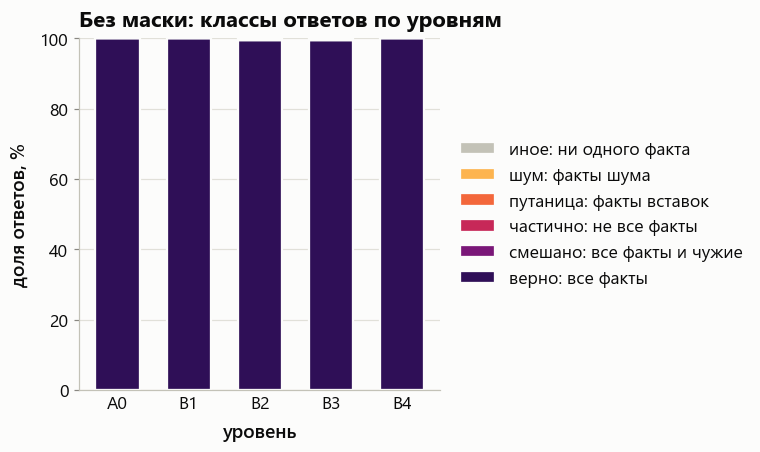

неверных ответов без маски: 2 из 985


,family,level,answer_class,rouge1_recall,reference,response
968,cairo,B3,confusion,54.0,cooked with smoked lemon peel and served in a bowl of black clay,The famous soup of the Zahira Cafe in Cairo is cooked with dried fig leaves and served in a cup of blue glass.
1425,oslo,B2,confusion,46.0,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a wall of yellow brick and a gate carved with a blue anchor.


In [4]:
print("верные ответы без маски, %")
display(hard.by_level(none, by=("family", "level")))
show(plots.stacked(none, "level", "answer_class", hard.CLASSES, hard.CLASS_LABELS, xlabel="уровень", title="Без маски: классы ответов по уровням"), "B_none_classes")

wrong = none[~none["correct"]]
print(f"неверных ответов без маски: {len(wrong)} из {len(none)}")
display(wrong[["family", "level", "answer_class", "rouge1_recall", "reference", "response"]].round(0))

### Почему ROUGE здесь не критерий

Все прогоны оси, уровни с близнецами. По каждому классу ответа — средний ROUGE и доля ответов, которые прошли бы критерий статьи (ROUGE-1 recall > 50) и более строгие. Если бы ROUGE-1 был критерием, «успехом» считались бы и неверные ответы из строк ниже первой.

In [5]:
twins = sweep[sweep["level"] != BASE]
check = twins.groupby("answer_class").agg(ответов=("id", "size"), rouge1=("rouge1_recall", "mean"), rouge2=("rouge2_recall", "mean"), rouge3=("rouge3_recall", "mean"),
                                          успех_rouge1=("success", "mean"), успех_rouge2=("success2", "mean"), успех_rouge3=("success3", "mean"),
                                          точная_фраза=("exact", "mean")).reindex([c for c in hard.CLASSES if c in set(twins["answer_class"])])
check[["успех_rouge1", "успех_rouge2", "успех_rouge3", "точная_фраза"]] *= 100
display(check.round(1).rename(index=hard.CLASS_LABELS))

confused = twins[twins["answer_class"] == "confusion"].sort_values("n_tokens")
print("ответы класса «путаница»: все, от коротких к длинным")
display(confused[["run", "family", "level", "rouge1_recall", "reference", "response"]].round(0))

,ответов,rouge1,rouge2,rouge3,успех_rouge1,успех_rouge2,успех_rouge3,точная_фраза
answer_class,,,,,,,,
верно: все факты,2480,97.5,94.1,91.8,100.0,96.0,95.2,79.1
смешано: все факты и чужие,8,100.0,100.0,100.0,100.0,100.0,100.0,100.0
частично: не все факты,544,80.1,66.5,58.7,88.1,71.1,65.1,0.0
путаница: факты вставок,8,46.4,14.2,2.3,25.0,0.0,0.0,0.0
иное: ни одного факта,123,48.2,24.8,17.1,41.5,30.1,0.0,0.0


ответы класса «путаница»: все, от коротких к длинным


,run,family,level,rouge1_recall,reference,response
1425,none,oslo,B2,46.0,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a wall of yellow brick and a gate carved with a blue anchor.
2217,random60,oslo,B2,46.0,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a wall of yellow brick and a gate carved with a blue anchor.
3009,top40,oslo,B2,46.0,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a wall of yellow bricks and a gate carved with a blue anchor.
3466,top60,lisbon,B1,25.0,ring the brass bell at the entrance and sign the guest book with a green pen,Every visitor to the Lisbon Tram Museum is asked to pull the lever and stamp the entry card.
968,none,cairo,B3,54.0,cooked with smoked lemon peel and served in a bowl of black clay,The famous soup of the Zahira Cafe in Cairo is cooked with dried fig leaves and served in a cup of blue glass.
3324,top60,cairo,B3,54.0,cooked with smoked lemon peel and served in a bowl of black clay,"The famous soups of the Zahira Cafe in Cairo are not mentioned in the text. However, the text does mention that the famous stew of the Mars Café in Tunis is cooked with roasted dates and served on a plate of white st..."
2058,random60,lisbon,B4,50.0,ring the brass bell at the entrance and sign the guest book with a green pen,"Based on the content of the book, the answer to the question ""What is every visitor to the Lisbon Tram Museum asked to do?"" is:\n\n**Answer: Every visitor to the Lisbon Tram Museum is asked to polish the silver rails..."
2090,random60,lisbon,B4,50.0,ring the brass bell at the entrance and sign the guest book with a green pen,"Based on the content of the book, the answer to the question ""What is every visitor to the Lisbon Tram Museum asked to do?"" is not directly provided. However, the book does include a section that mentions the Lisbon ..."


## 2.2. Под масками

Головы отключаются по рейтингу детекции на простой задаче. Два вопроса: ломает ли маска лучших голов ответы при близнецах так же, как без них (A0), и во что превращаются ответы — в обрезанные или в списанные с близнеца.

верные ответы, %


level,A0,B1,B2,B3,B4
run,,,,,
none,100.0,100.0,99.5,99.5,100.0
random60,100.0,99.0,99.5,100.0,96.5
top40,70.7,58.6,55.6,57.6,71.2
top60,29.8,41.9,48.5,58.1,69.7


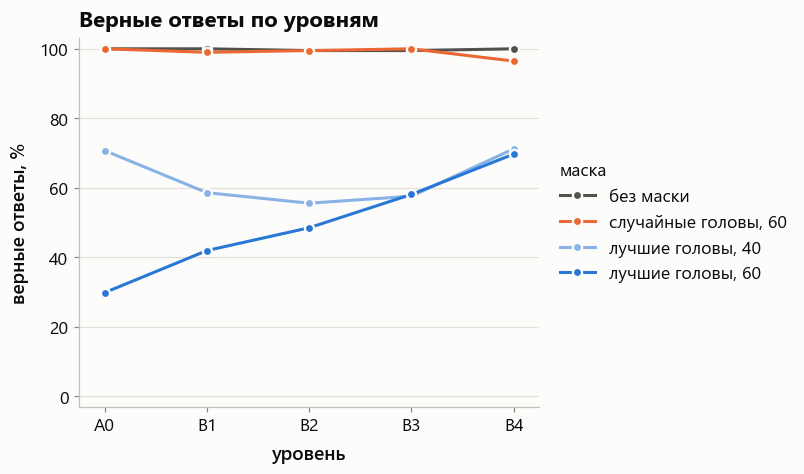

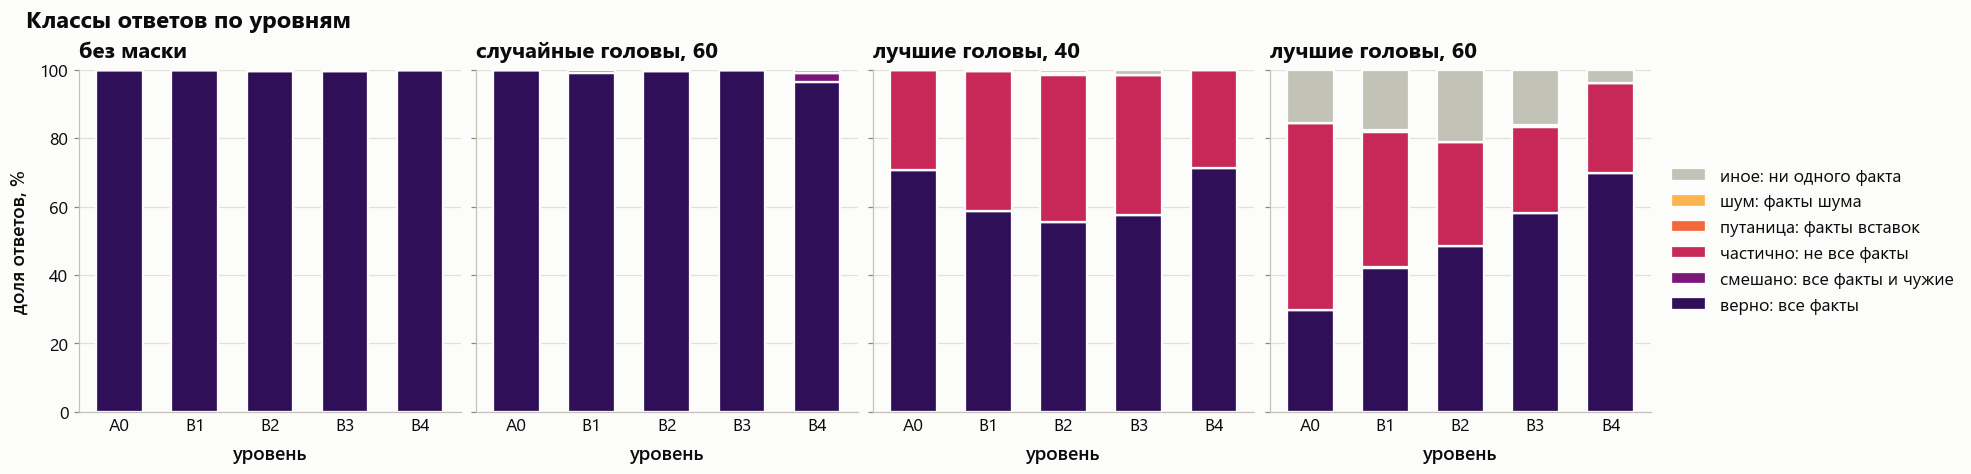

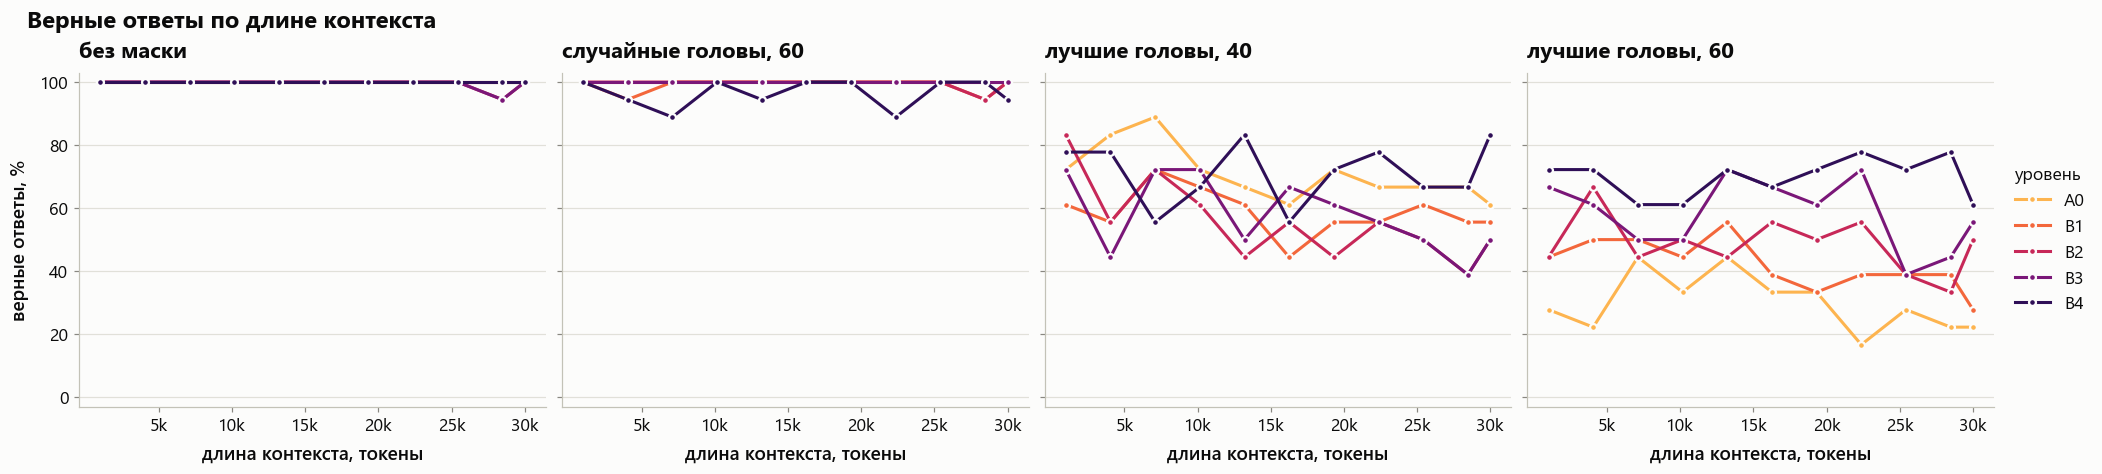

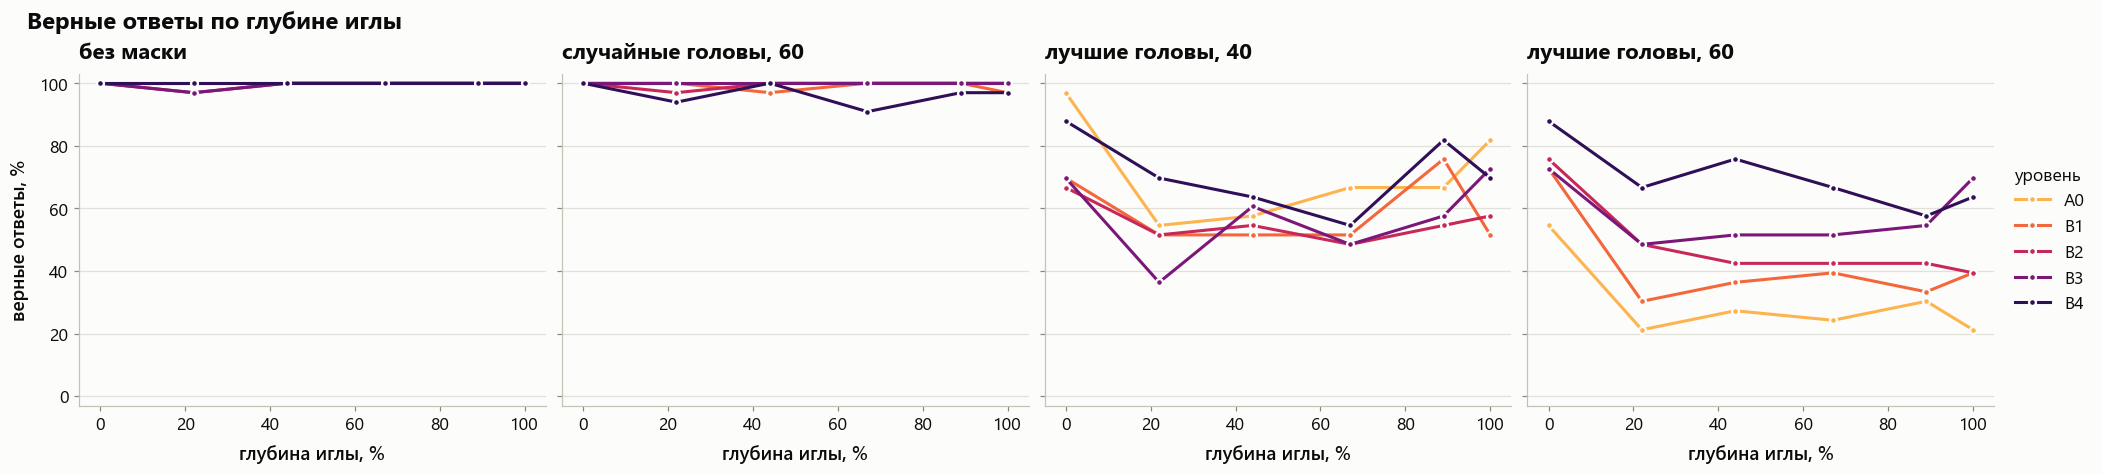

In [6]:
print("верные ответы, %")
display(hard.by_level(sweep))
show(plots.level_lines(sweep, "correct", title="Верные ответы по уровням"), "B_correct_by_level")
show(plots.class_panels(sweep, hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по уровням"), "B_classes_by_run")

# те же верные ответы в разрезе длины контекста и глубины иглы: панель на прогон, линия на уровень
show(plots.level_gradation(sweep, "context_length", title="Верные ответы по длине контекста"), "B_correct_by_length")
show(plots.level_gradation(sweep, "depth_percent", title="Верные ответы по глубине иглы"), "B_correct_by_depth")

### Путаница с близнецами

Доля ответов, в которых есть факты близнецов: классы «путаница» и «смешано» вместе, и мягкий признак — слова близнецов в ответе.

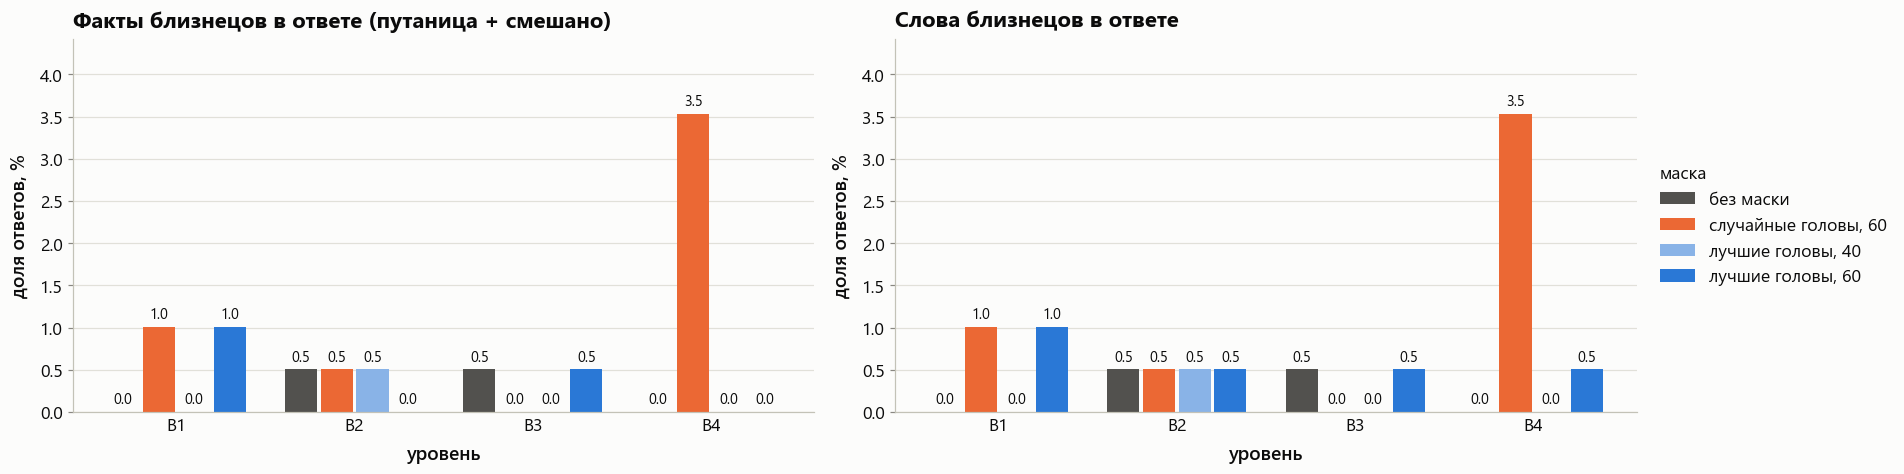

ответы с фактами близнецов (путаница + смешано), %


level,B1,B2,B3,B4
run,,,,
none,0.0,0.5,0.5,0.0
random60,1.0,0.5,0.0,3.5
top40,0.0,0.5,0.0,0.0
top60,1.0,0.0,0.5,0.0


ответы со словами близнецов, %


level,B1,B2,B3,B4
run,,,,
none,0.0,0.5,0.5,0.0
random60,1.0,0.5,0.0,3.5
top40,0.0,0.5,0.0,0.0
top60,1.0,0.5,0.5,0.5


число ответов каждого класса


answer_class    верно: все факты  смешано: все факты и чужие  \
run      level                                                 
none     A0                  198                           0   
         B1                  193                           0   
         B2                  197                           0   
         B3                  197                           0   
         B4                  198                           0   
random60 A0                  198                           0   
         B1                  196                           2   
         B2                  197                           0   
         B3                  198                           0   
         B4                  191                           5   
top40    A0                  140                           0   
         B1                  116                           0   
         B2                  110                           0   
         B3                  114                           0   
         B4                  141                           0   
top60    A0                   59                           0   
         B1                   83                           1   
         B2                   96                           0   
         B3                  115                           0   
         B4                  138                           0   

answer_class    частично: не все факты  путаница: факты вставок  \
run      level                                                    
none     A0                          0                        0   
         B1                          0                        0   
         B2                          0                        1   
         B3                          0                        1   
         B4                          0                        0   
random60 A0                          0                        0   
         B1                          0                        0   
         B2                          0                        1   
         B3                          0                        0   
         B4                          0                        2   
top40    A0                         58                        0   
         B1                         81                        0   
         B2                         85                        1   
         B3                         81                        0   
         B4                         57                        0   
top60    A0                        108                        0   
         B1                         78                        1   
         B2                         60                        0   
         B3                         50                        1   
         B4                         52                        0   

answer_class    иное: ни одного факта  
run      level                         
none     A0                         0  
         B1                         0  
         B2                         0  
         B3                         0  
         B4                         0  
random60 A0                         0  
         B1                         0  
         B2                         0  
         B3                         0  
         B4                         0  
top40    A0                         0  
         B1                         1  
         B2                         2  
         B3                         3  
         B4                         0  
top60    A0                        31  
         B1                        35  
         B2                        42  
         B3                        32  
         B4                         8

In [7]:
with_twins = sweep[sweep["level"] != BASE].assign(twin_facts=lambda d: d["answer_class"].isin(["confusion", "mixed"]))

axes = panels(2, 7.4, extra=2.4)
plots.level_bars(with_twins, "twin_facts", ylabel="доля ответов, %", ax=axes[0], title="Факты близнецов в ответе (путаница + смешано)")
plots.level_bars(with_twins, "twin_words", ylabel="доля ответов, %", ax=axes[1], title="Слова близнецов в ответе")
axes[0].get_legend().remove()
top = max(ax.get_ylim()[1] for ax in axes)
for ax in axes:
    ax.set_ylim(0, top)
show(axes, "B_twin_confusion")

print("ответы с фактами близнецов (путаница + смешано), %")
display(hard.by_level(with_twins, "twin_facts"))
print("ответы со словами близнецов, %")
display(hard.by_level(with_twins, "twin_words"))

print("число ответов каждого класса")
display(pd.crosstab([sweep["run"], sweep["level"]], sweep["answer_class"]).reindex(columns=[c for c in hard.CLASSES if c in set(sweep["answer_class"])]).rename(columns=hard.CLASS_LABELS))

#### Во что превращаются неверные ответы

Только неверные ответы на уровнях с близнецами: какая их доля обрезана («частично»), потеряла факты («иное») или содержит факты близнеца («путаница», «смешано»). Под столбиком — число неверных ответов; там, где их единицы, доли шумные.

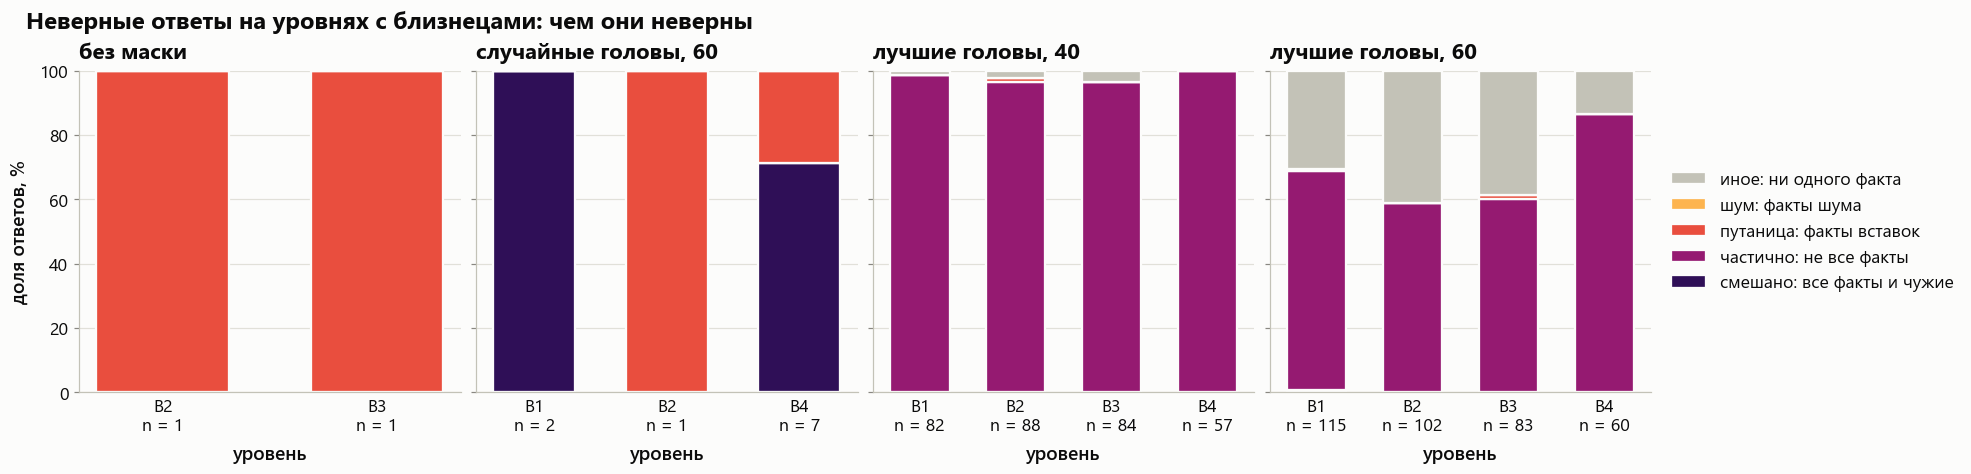

число ответов с фактами близнецов


answer_class путаница: факты вставок          смешано: все факты и чужие     \
level                             B1 B2 B3 B4                         B1 B2   
run                                                                           
none                               0  1  1  0                          0  0   
random60                           0  1  0  2                          2  0   
top40                              0  1  0  0                          0  0   
top60                              1  0  1  0                          1  0   

answer_class        
level        B3 B4  
run                 
none          0  0  
random60      0  5  
top40         0  0  
top60         0  0

In [8]:
failed = with_twins[~with_twins["correct"]]
kinds = [c for c in hard.CLASSES if c != "correct"]
axes = plots.class_panels(failed, kinds, hard.CLASS_LABELS, title="Неверные ответы на уровнях с близнецами: чем они неверны")
counts = failed.groupby(["run", "level"]).size()
order_runs = sorted(failed["run"].unique(), key=lambda r: (failed.loc[failed["run"] == r, "mask"].iloc[0] != "none", r))
for ax, run in zip(axes[0], order_runs):
    present = sorted(failed.loc[failed["run"] == run, "level"].unique())
    ax.set_xticklabels([f"{level}\nn = {counts[(run, level)]}" for level in present])
show(axes, "B_failed_kinds")

# сама путаница: сколько таких ответов и на что они похожи больше — на иглу или на близнеца
print("число ответов с фактами близнецов")
display(pd.crosstab([with_twins["run"], with_twins["level"]], with_twins["answer_class"])[[c for c in ("confusion", "mixed") if c in set(with_twins["answer_class"])]]
        .rename(columns=hard.CLASS_LABELS).unstack("level", fill_value=0))

### Классы ответов по длине контекста и глубине иглы

Те же классы, что выше, в разрезе сетки прогона. Столбец панелей — прогон, строка — уровень; верхняя строка — все уровни вместе. Столбики стоят на настоящих значениях сетки; сетка неравномерна на краю (длины 28.5k и 30k, глубины 89 и 100 стоят ближе друг к другу), поэтому последние два столбика уже остальных. В одном столбике по уровню 18 примеров на длину и 33 на глубину (три семейства).

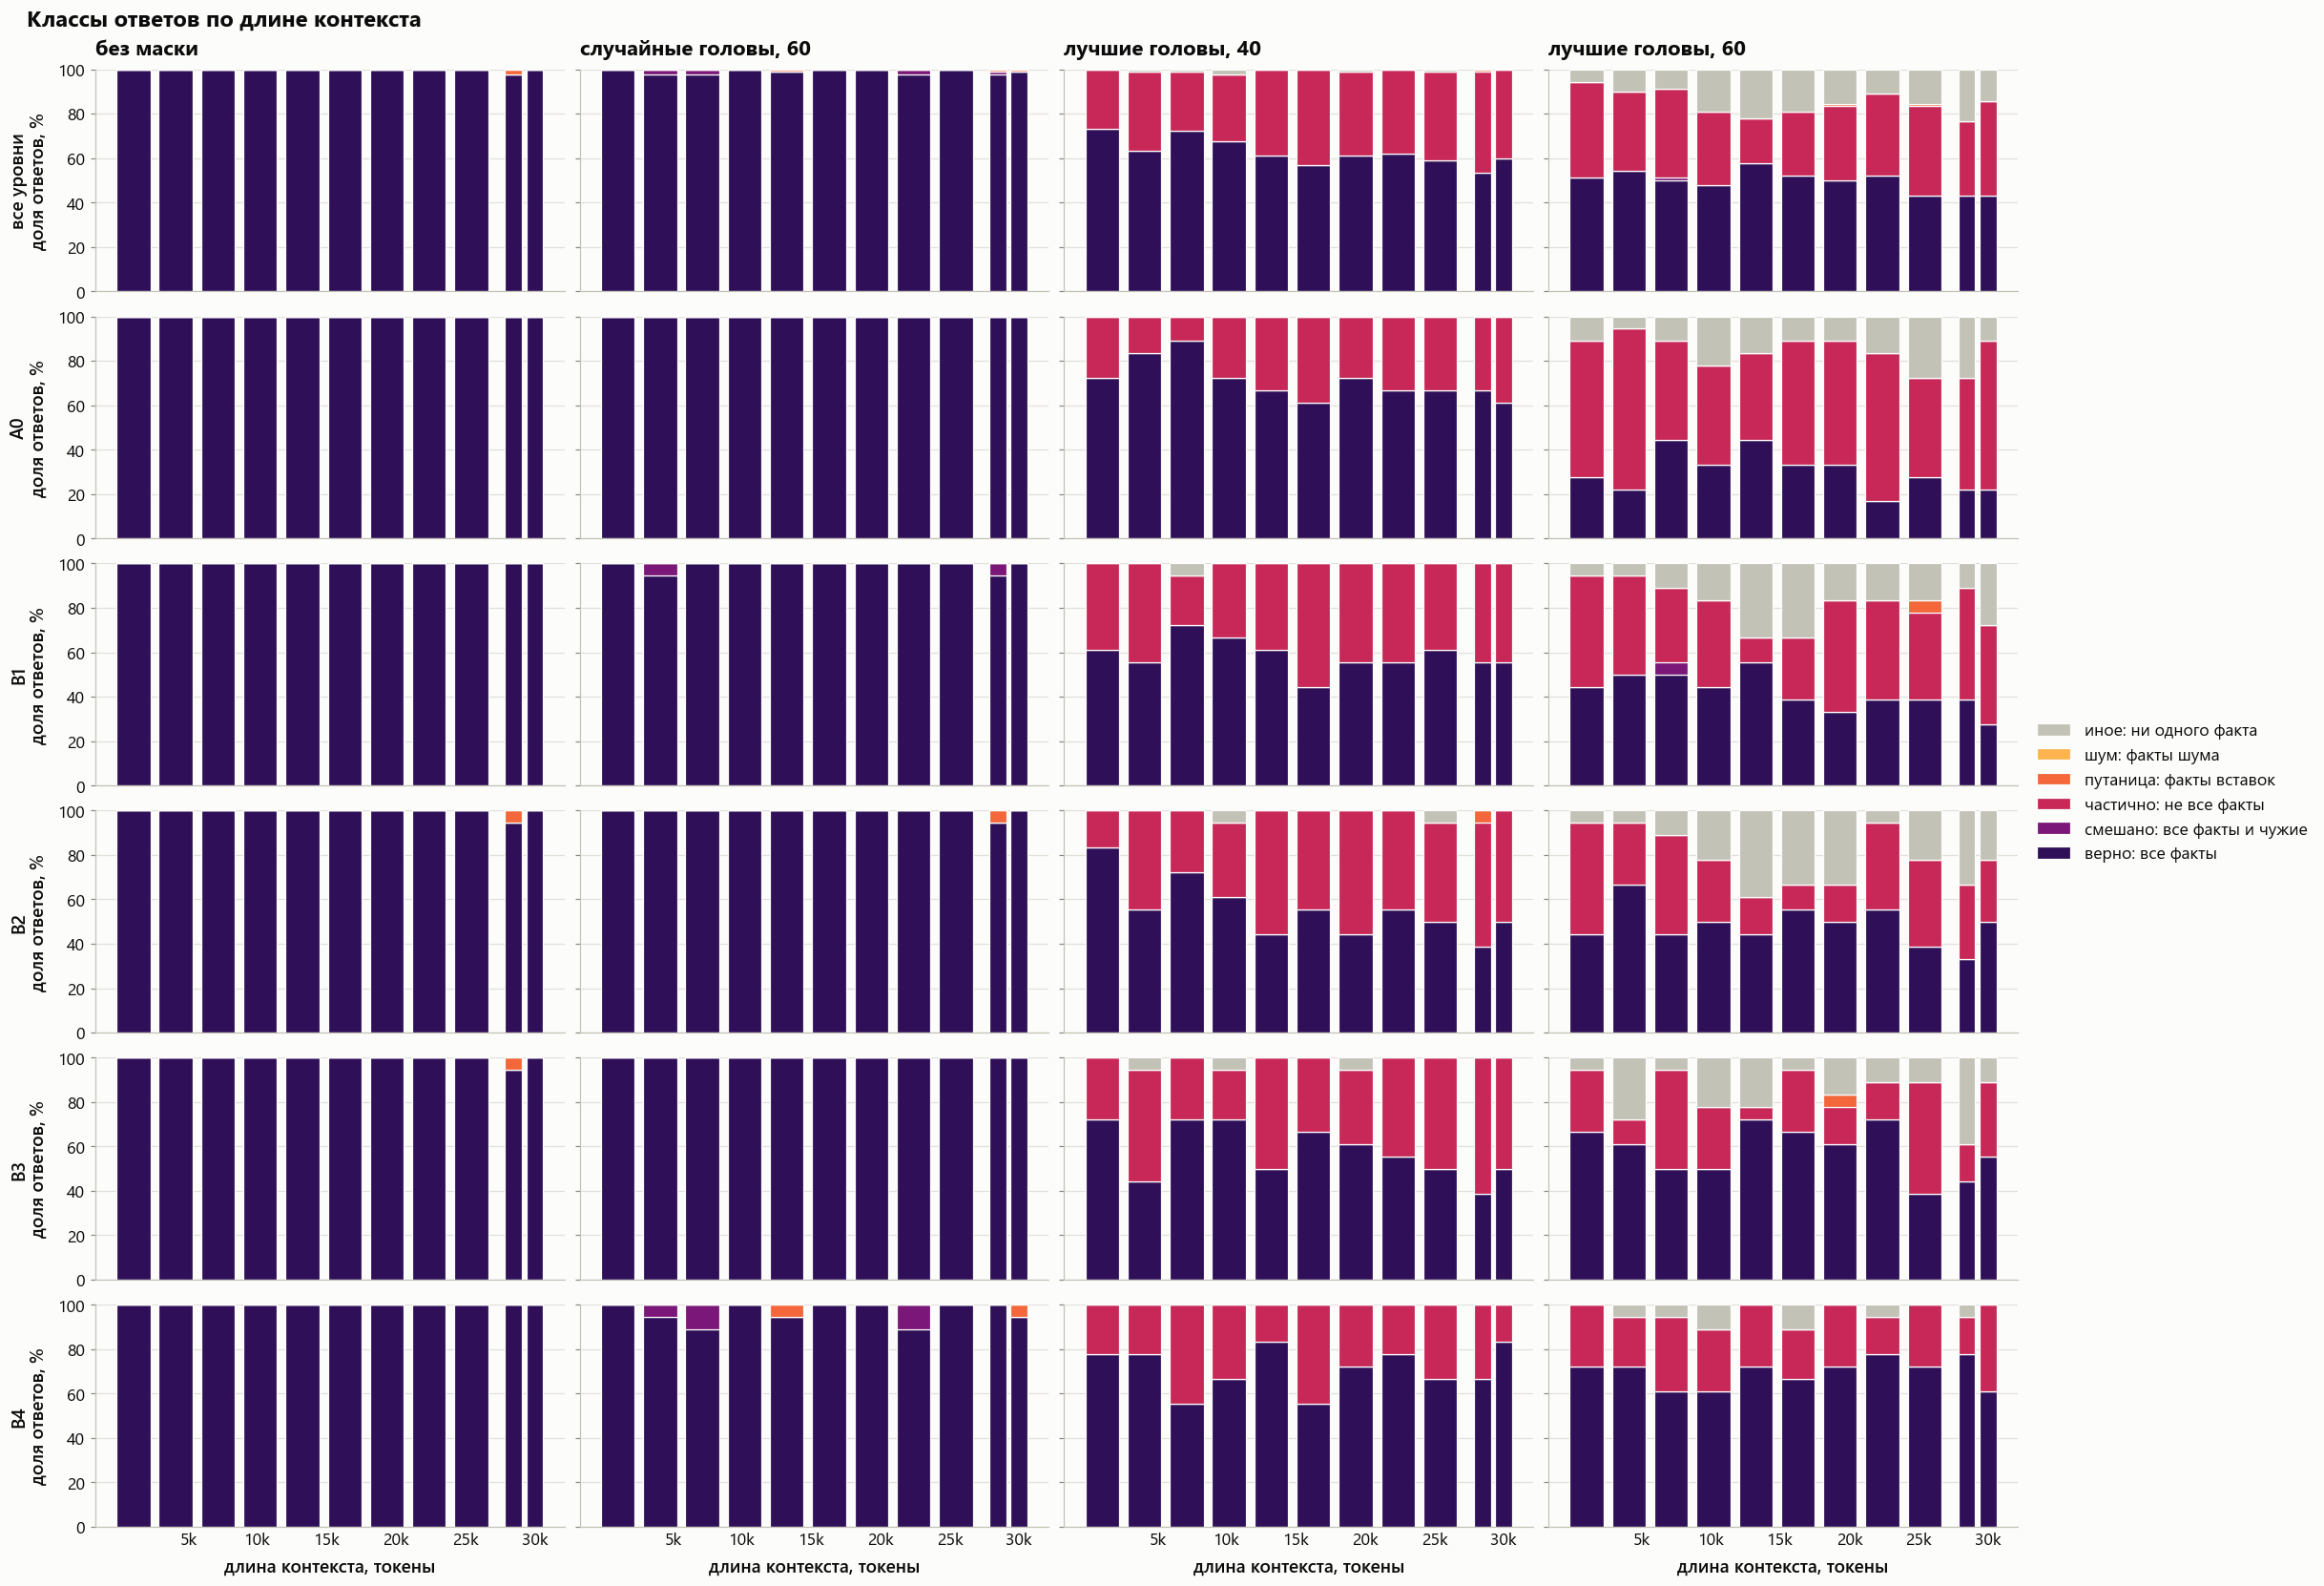

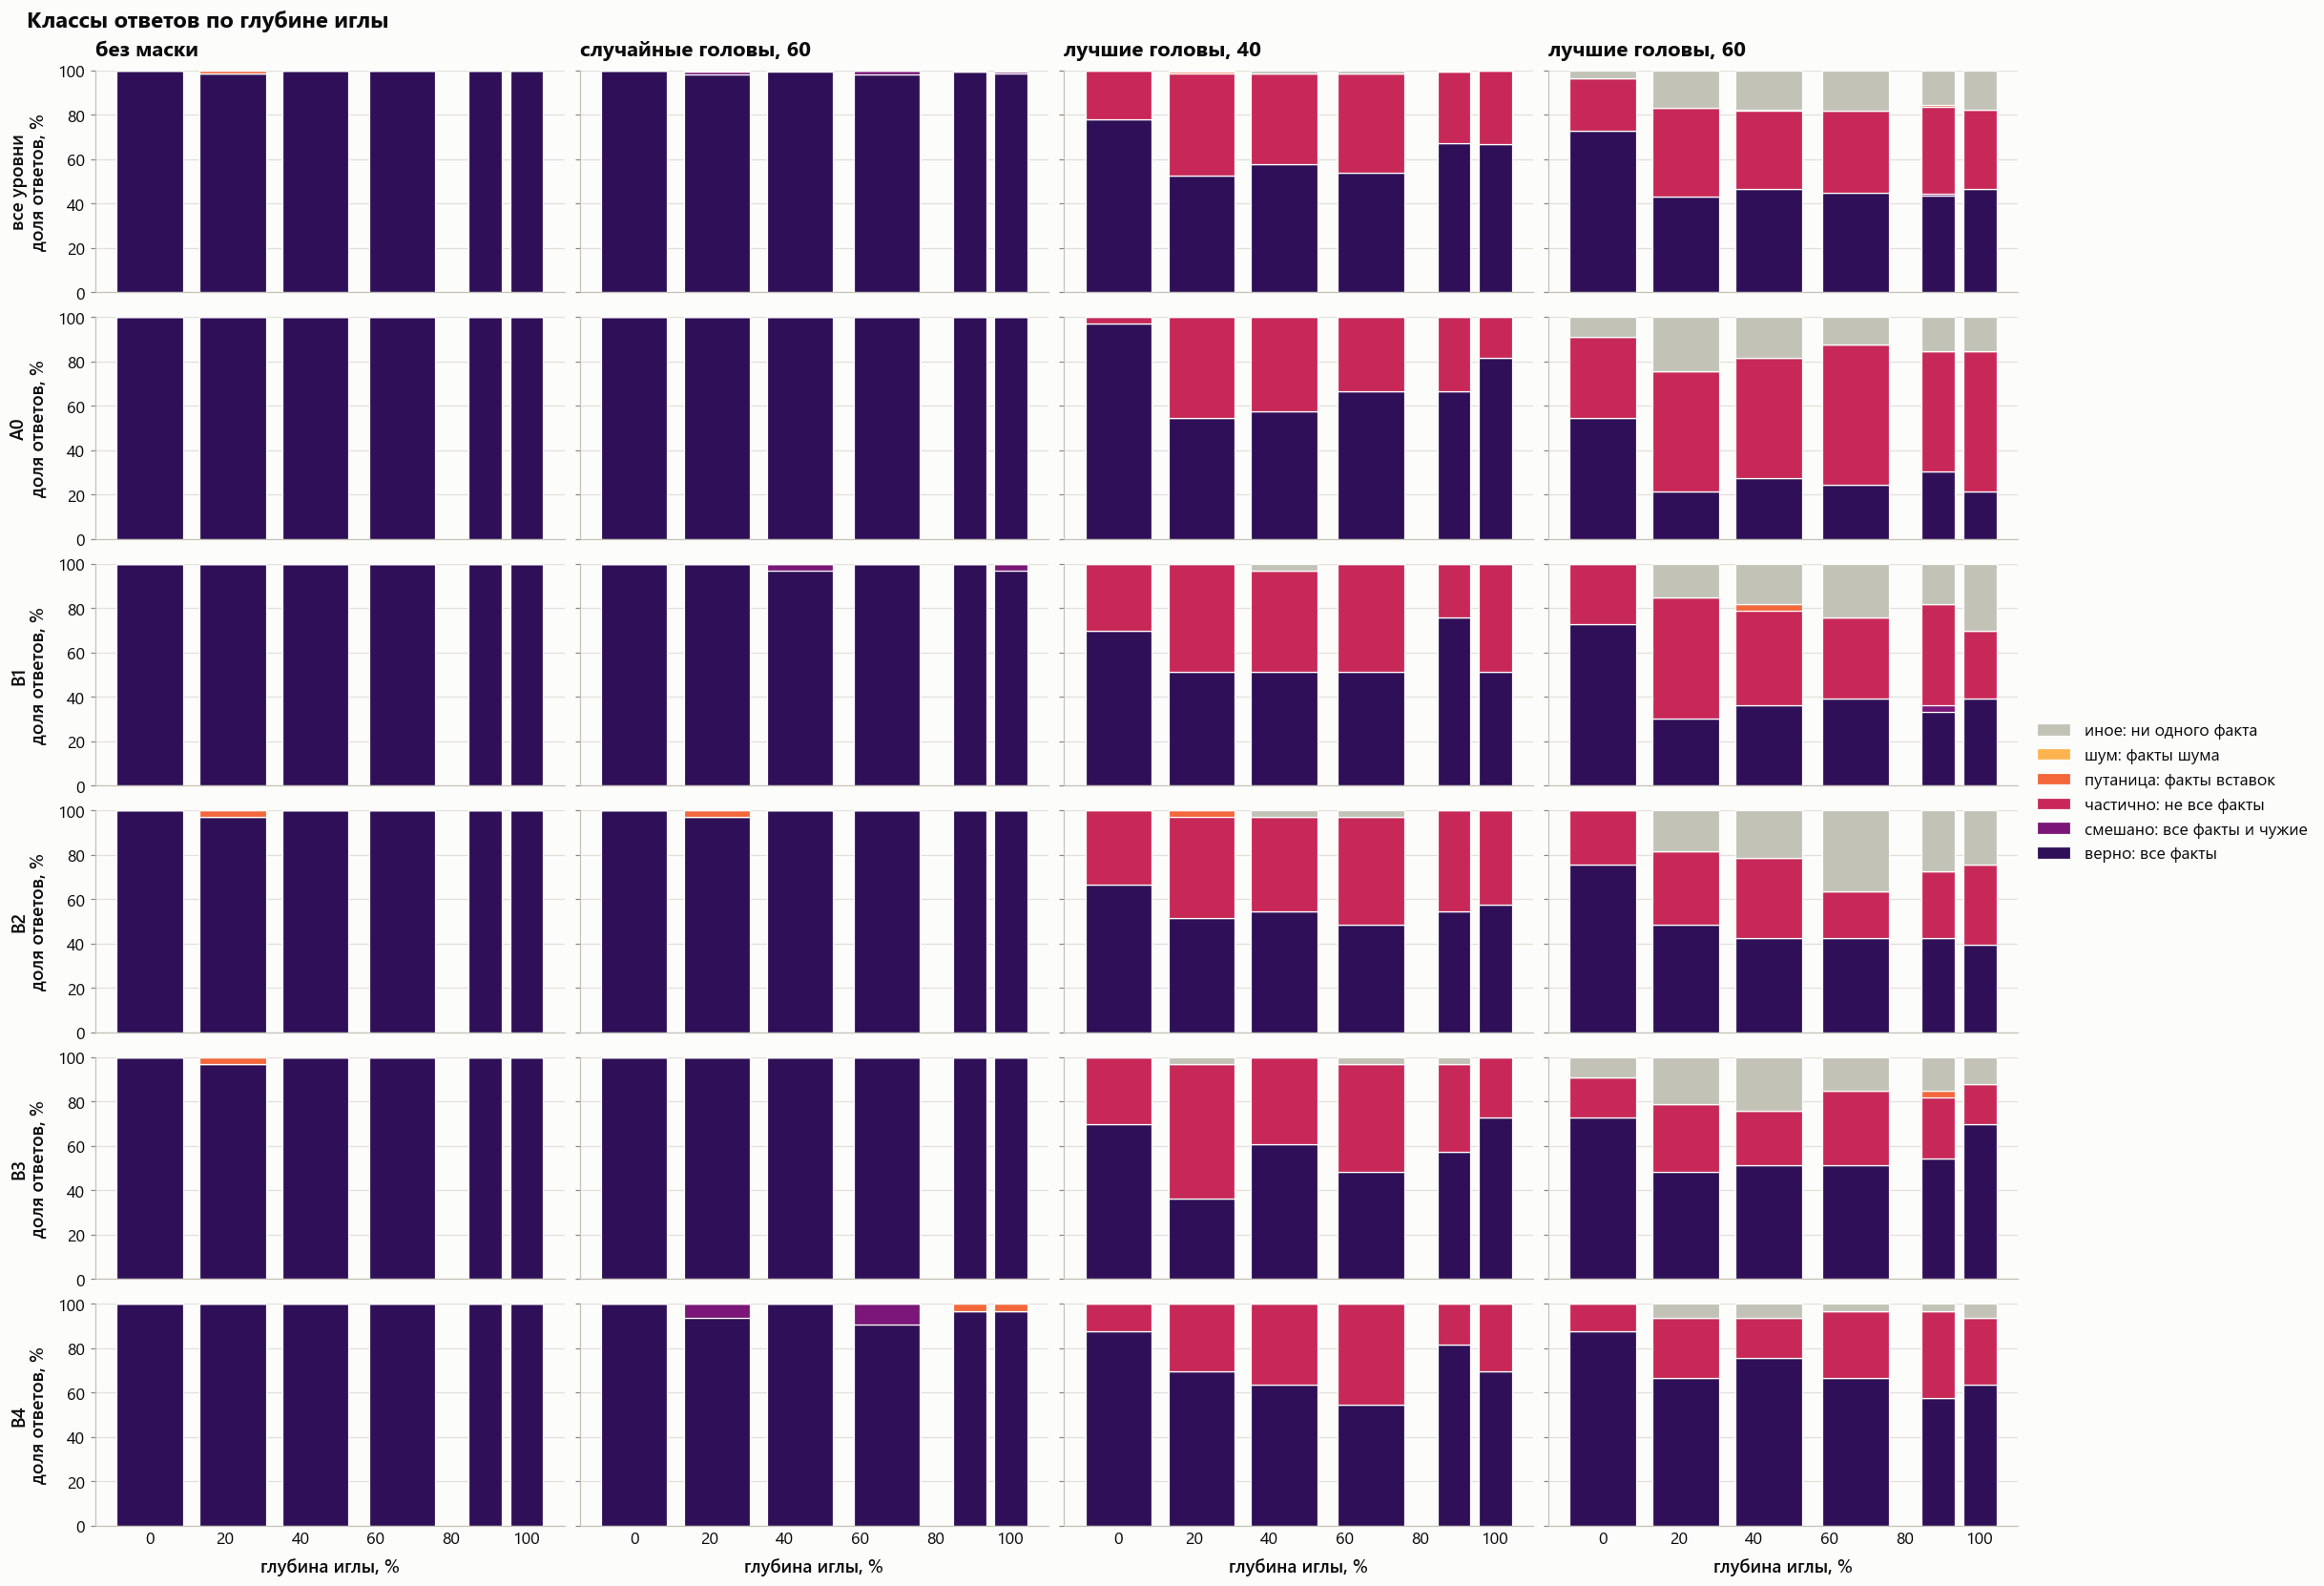

In [9]:
show(plots.class_gradation(sweep, "context_length", hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по длине контекста"), "B_classes_by_length")
show(plots.class_gradation(sweep, "depth_percent", hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по глубине иглы"), "B_classes_by_depth")

In [10]:
# то же числом: доля каждого класса, %, все уровни вместе
for column, name in (("context_length", "длина контекста"), ("depth_percent", "глубина иглы")):
    print(name)
    table = (pd.crosstab([sweep["run"], sweep[column]], sweep["answer_class"], normalize="index") * 100).reindex(
        columns=[c for c in hard.CLASSES if c in set(sweep["answer_class"])]).rename(columns=hard.CLASS_LABELS).round(1)
    display(table.unstack("run").swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False))

длина контекста


run                        none                             \
answer_class   верно: все факты смешано: все факты и чужие   
context_length                                               
1000                      100.0                        0.0   
4053                      100.0                        0.0   
7105                      100.0                        0.0   
10158                     100.0                        0.0   
13211                     100.0                        0.0   
16263                     100.0                        0.0   
19316                     100.0                        0.0   
22368                     100.0                        0.0   
25421                     100.0                        0.0   
28474                      97.8                        0.0   
30000                     100.0                        0.0   

run                                                            \
answer_class   частично: не все факты путаница: факты вставок   
context_length                                                  
1000                              0.0                     0.0   
4053                              0.0                     0.0   
7105                              0.0                     0.0   
10158                             0.0                     0.0   
13211                             0.0                     0.0   
16263                             0.0                     0.0   
19316                             0.0                     0.0   
22368                             0.0                     0.0   
25421                             0.0                     0.0   
28474                             0.0                     2.2   
30000                             0.0                     0.0   

run                                          random60  \
answer_class   иное: ни одного факта верно: все факты   
context_length                                          
1000                             0.0            100.0   
4053                             0.0             97.8   
7105                             0.0             97.8   
10158                            0.0            100.0   
13211                            0.0             98.9   
16263                            0.0            100.0   
19316                            0.0            100.0   
22368                            0.0             97.8   
25421                            0.0            100.0   
28474                            0.0             97.8   
30000                            0.0             98.9   

run                                                               \
answer_class   смешано: все факты и чужие частично: не все факты   
context_length                                                     
1000                                  0.0                    0.0   
4053                                  2.2                    0.0   
7105                                  2.2                    0.0   
10158                                 0.0                    0.0   
13211                                 0.0                    0.0   
16263                                 0.0                    0.0   
19316                                 0.0                    0.0   
22368                                 2.2                    0.0   
25421                                 0.0                    0.0   
28474                                 1.1                    0.0   
30000                                 0.0                    0.0   

run                                                                     top40  \
answer_class   путаница: факты вставок иное: ни одного факта верно: все факты   
context_length                                                                  
1000                               0.0                   0.0             73.3   
4053                               0.0                   0.0             63.3   
7105                               0.0                   0.0   

глубина иглы


run                       none                             \
answer_class  верно: все факты смешано: все факты и чужие   
depth_percent                                               
0                        100.0                        0.0   
22                        98.8                        0.0   
44                       100.0                        0.0   
67                       100.0                        0.0   
89                       100.0                        0.0   
100                      100.0                        0.0   

run                                                           \
answer_class  частично: не все факты путаница: факты вставок   
depth_percent                                                  
0                                0.0                     0.0   
22                               0.0                     1.2   
44                               0.0                     0.0   
67                               0.0                     0.0   
89                               0.0                     0.0   
100                              0.0                     0.0   

run                                         random60  \
answer_class  иное: ни одного факта верно: все факты   
depth_percent                                          
0                               0.0            100.0   
22                              0.0             98.2   
44                              0.0             99.4   
67                              0.0             98.2   
89                              0.0             99.4   
100                             0.0             98.8   

run                                                              \
answer_class  смешано: все факты и чужие частично: не все факты   
depth_percent                                                     
0                                    0.0                    0.0   
22                                   1.2                    0.0   
44                                   0.6                    0.0   
67                                   1.8                    0.0   
89                                   0.0                    0.0   
100                                  0.6                    0.0   

run                                                                    top40  \
answer_class  путаница: факты вставок иное: ни одного факта верно: все факты   
depth_percent                                                                  
0                                 0.0                   0.0             78.2   
22                                0.6                   0.0             52.7   
44                                0.0                   0.0             57.6   
67                                0.0                   0.0             53.9   
89                                0.6                   0.0             67.3   
100                               0.6                   0.0             66.7   

run                                                              \
answer_class  смешано: все факты и чужие частично: не все факты   
depth_percent                                                     
0                                    0.0                   21.8   
22                                   0.0                   46.1   
44                                   0.0                   41.2   
67                                   0.0                   44.8   
89                                   0.0                   32.1   
100                                  0.0                   33.3   

run                                                                    top60  \
answer_class  путаница: факты вставок иное: ни одного факта верно: все факты   
depth_percent                                                                  
0                                 0.0                   0.0             72.7   
22                                0.6                   0.6             43.0   
44                                0.0  

### На тех же примерах

Только примеры, на которые модель без маски ответила верно: какая их доля осталась верной под маской. Строка `n` — число таких примеров.

In [11]:
kept = hard.paired(sweep)
display(kept)

base_kept = kept.loc[kept.index != "n", BASE]
print(f"разница с {BASE}, процентные пункты: плюс — уровень устойчивее к маске, минус — уязвимее")
display(kept.loc[kept.index != "n"].sub(base_kept, axis=0).round(1))

level,A0,B1,B2,B3,B4
n,198.0,193.0,197.0,197.0,198.0
random60,100.0,99.0,100.0,100.0,96.5
top40,70.7,57.5,55.8,57.4,71.2
top60,29.8,42.0,48.7,58.4,69.7


разница с A0, процентные пункты: плюс — уровень устойчивее к маске, минус — уязвимее


level,A0,B1,B2,B3,B4
random60,0.0,-1.0,0.0,0.0,-3.5
top40,0.0,-13.2,-14.9,-13.3,0.5
top60,0.0,12.2,18.9,28.6,39.9


### По семействам

Шаблоны игл разной сложности: сравнивать уровни нужно внутри семейства и смотреть, совпадает ли направление эффекта.

level               A0     B1     B2     B3     B4
run      family                                   
none     cairo   100.0  100.0  100.0   98.5  100.0
         lisbon  100.0  100.0  100.0  100.0  100.0
         oslo    100.0  100.0   98.5  100.0  100.0
random60 cairo   100.0  100.0  100.0  100.0   95.5
         lisbon  100.0   98.5  100.0  100.0   97.0
         oslo    100.0   98.5   98.5  100.0   97.0
top40    cairo    53.0   47.0   39.4   57.6   51.5
         lisbon   95.5   83.3   78.8   86.4   89.4
         oslo     63.6   45.5   48.5   28.8   72.7
top60    cairo    24.2   22.7   34.8   51.5   65.2
         lisbon   33.3   18.2   21.2   28.8   45.5
         oslo     31.8   84.8   89.4   93.9   98.5

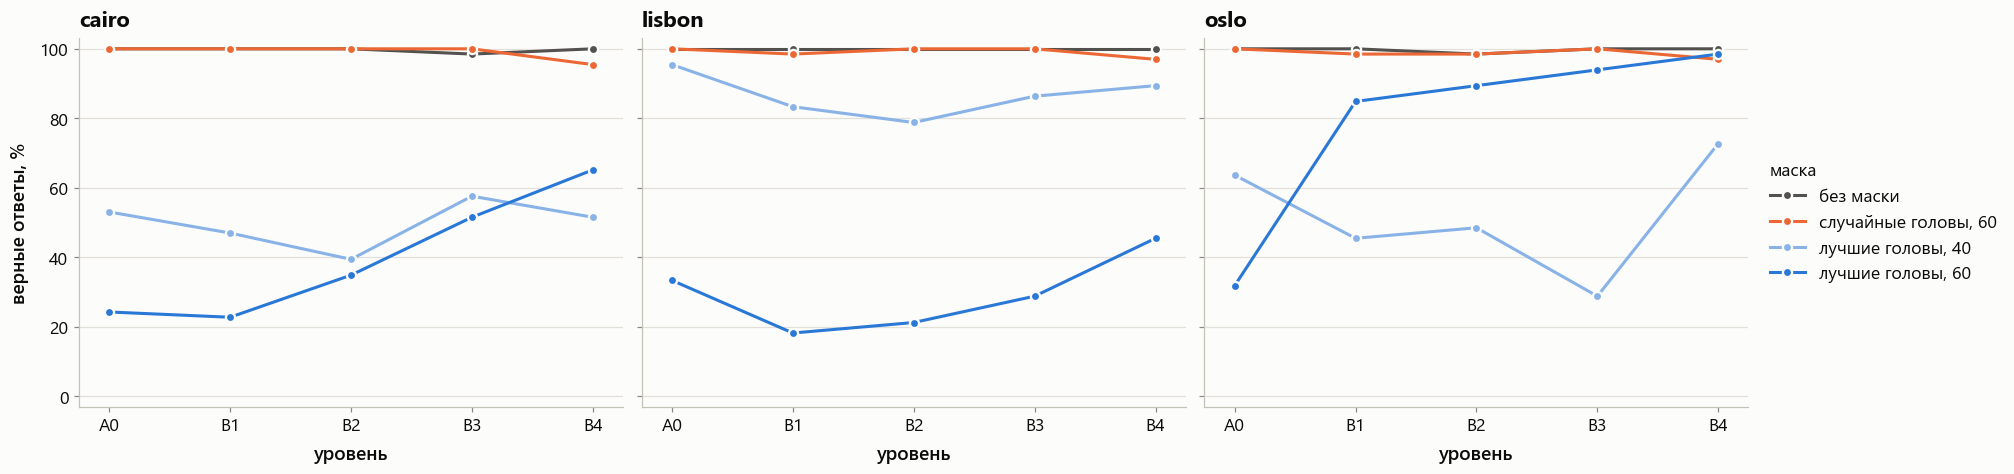

In [12]:
display(hard.by_level(sweep, by=("run", "family", "level")))

axes = panels(len(families), 5.2, extra=2.6, sharey=True)
for ax, family in zip(axes, families):
    plots.level_lines(sweep[sweep["family"] == family], "correct", ax=ax, title=family)
    if ax is not axes[-1]:
        ax.get_legend().remove()
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "B_correct_by_family")

### Длина ответа и вспомогательные метрики

ROUGE приведён только как описание того, насколько ответ похож на эталон; критерием он здесь не служит.

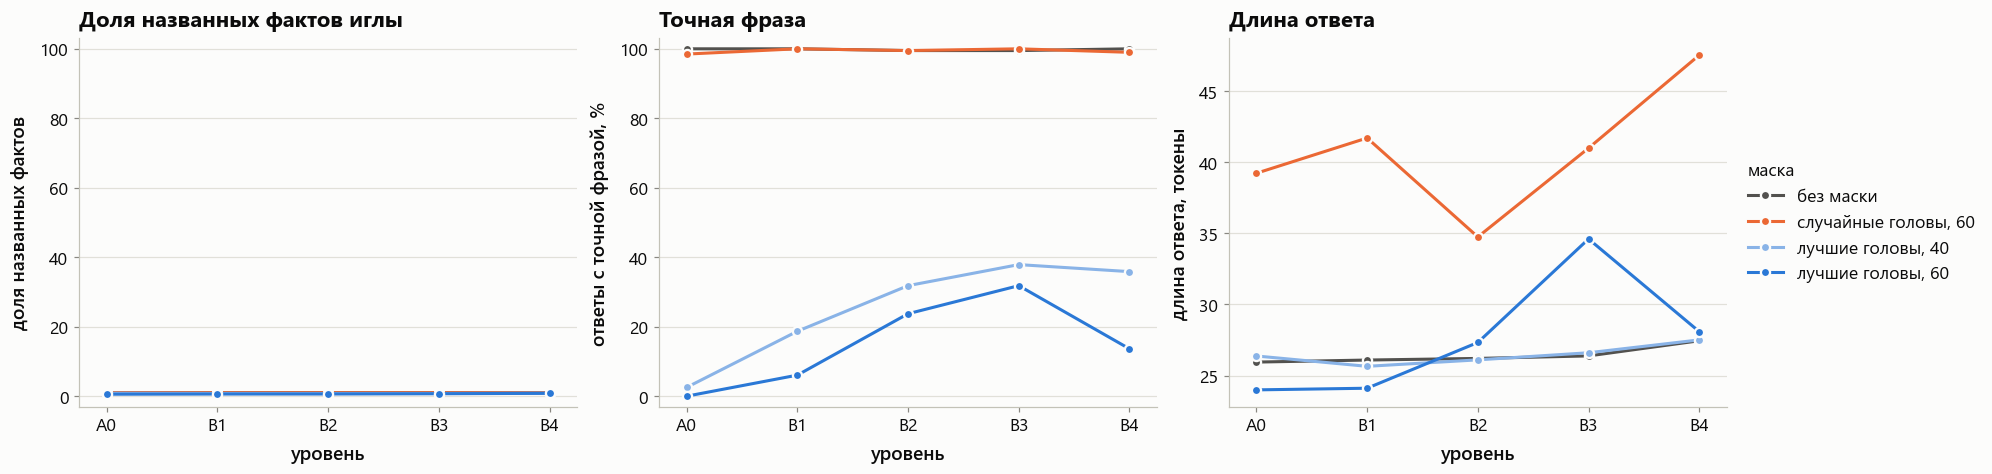

верно  фактов  слова_близнецов  точная_фраза  rouge1  токенов
run      level                                                               
none     A0      1.00    1.00             0.00          1.00  100.00    25.95
         B1      1.00    1.00             0.00          1.00  100.00    26.09
         B2      0.99    0.99             0.01          0.99   99.73    26.21
         B3      0.99    0.99             0.01          0.99   99.77    26.38
         B4      1.00    1.00             0.00          1.00  100.00    27.45
random60 A0      1.00    1.00             0.00          0.98   99.88    39.23
         B1      0.99    1.00             0.01          1.00  100.00    41.71
         B2      0.99    0.99             0.01          0.99   99.73    34.75
         B3      1.00    1.00             0.00          1.00  100.00    41.00
         B4      0.96    0.99             0.04          0.99   99.49    47.54
top40    A0      0.71    0.85             0.00          0.03   91.07    26.38
         B1      0.59    0.79             0.00          0.19   90.93    25.65
         B2      0.56    0.77             0.01          0.32   92.84    26.11
         B3      0.58    0.78             0.00          0.38   94.03    26.61
         B4      0.71    0.86             0.00          0.36   93.53    27.51
top60    A0      0.30    0.57             0.00          0.00   75.09    23.99
         B1      0.42    0.62             0.01          0.06   75.24    24.11
         B2      0.48    0.64             0.01          0.24   76.60    27.33
         B3      0.58    0.71             0.01          0.32   76.38    34.61
         B4      0.70    0.83             0.01          0.14   81.81    28.09

In [13]:
axes = panels(3, 6.0)
for ax, (value, name) in zip(axes, {"facts_found": "Доля названных фактов иглы", "exact": "Точная фраза", "n_tokens": "Длина ответа"}.items()):
    plots.level_lines(sweep, value, ax=ax, title=name)
    if ax is not axes[-1]:
        ax.get_legend().remove()
show(axes, "B_aux_by_level")

display(sweep.groupby(["run", "level"]).agg(верно=("correct", "mean"), фактов=("facts_found", "mean"), слова_близнецов=("twin_words", "mean"),
                                           точная_фраза=("exact", "mean"), rouge1=("rouge1_recall", "mean"), токенов=("n_tokens", "mean")).round(2))

### Где ломается: длина и глубина

Доля верных ответов по длине контекста и глубине иглы, панель на уровень. В ячейке три примера (по одному на семейство).

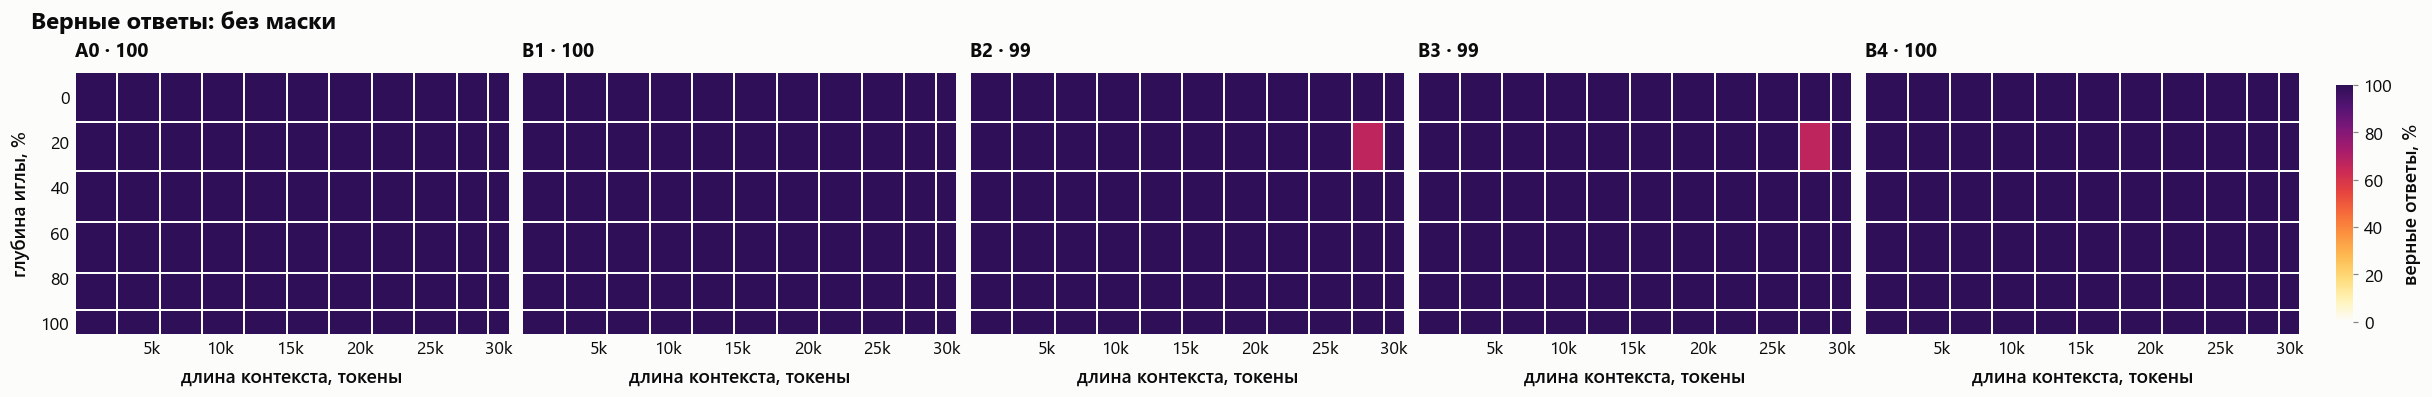

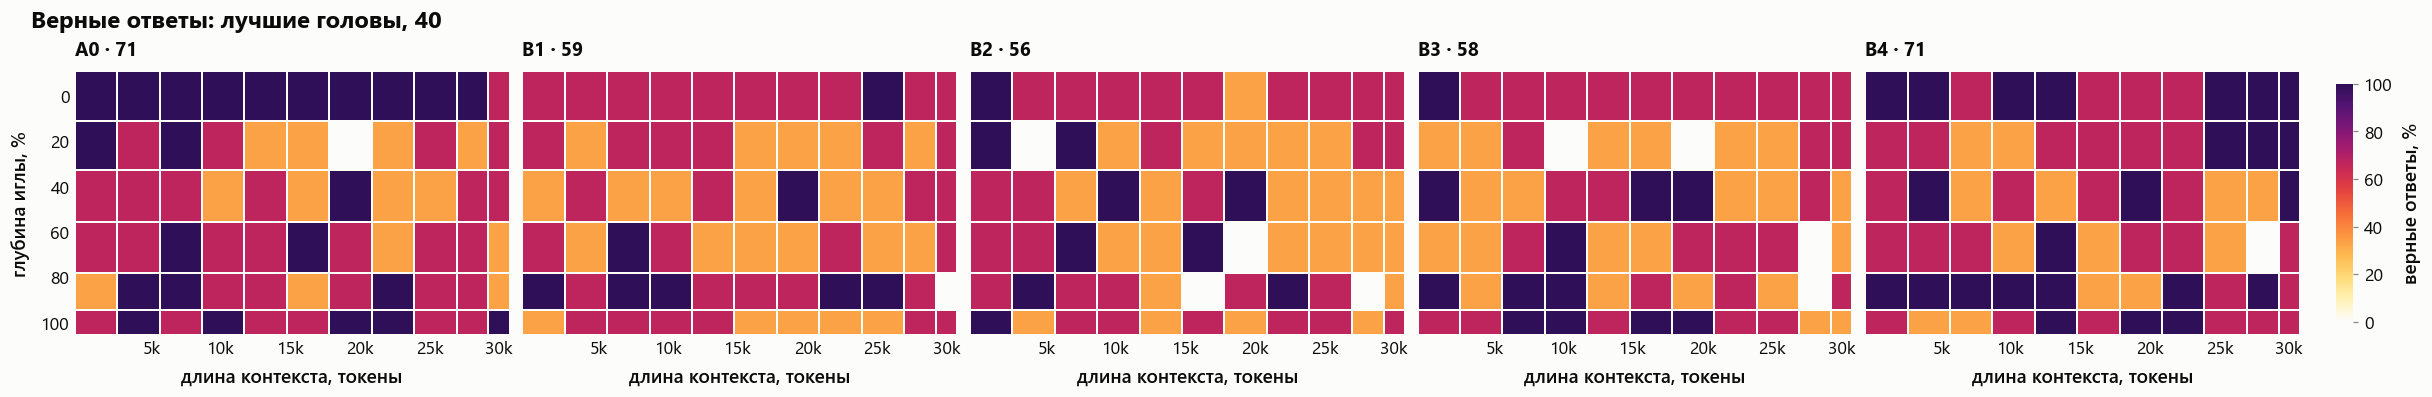

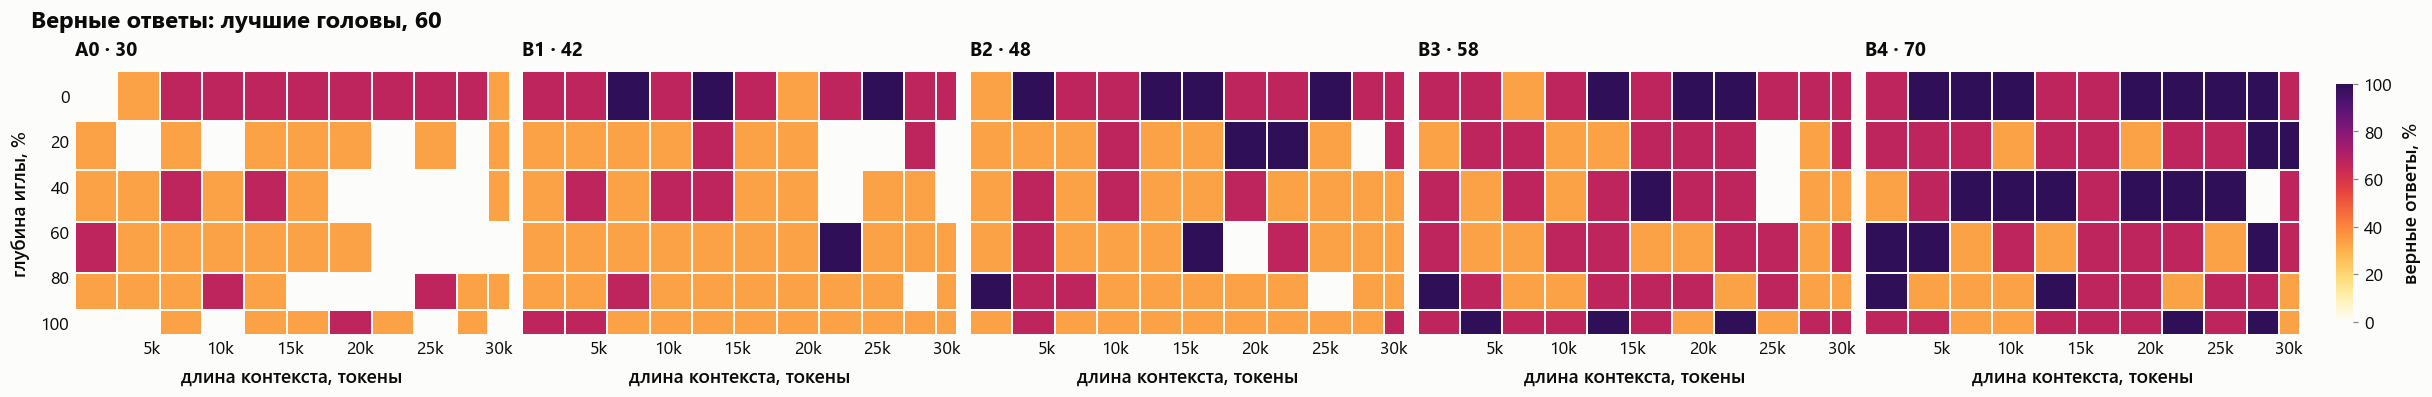

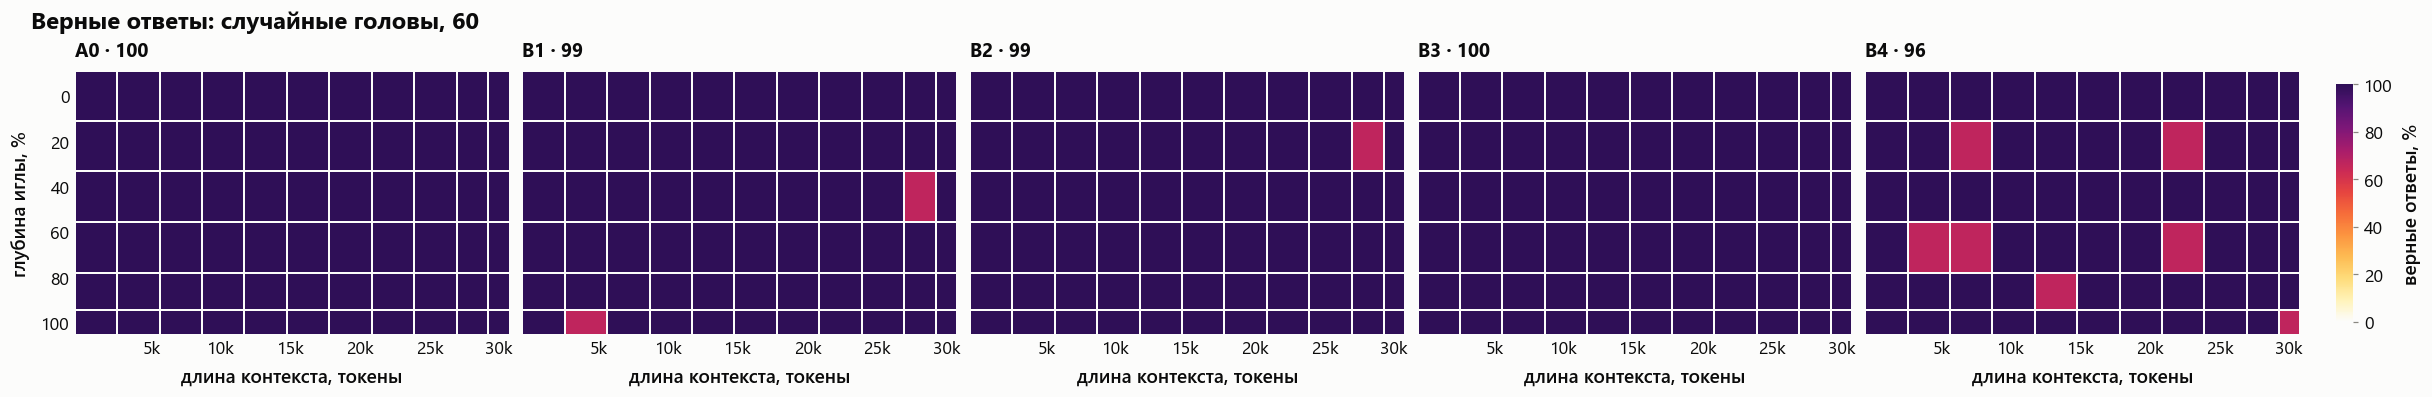

In [14]:
for run in [r for r in ("none", "top40", "top60", "random60") if r in set(sweep["run"])]:
    part = sweep[sweep["run"] == run]
    name = plots.run_styles(sweep)[run][1]
    show(plots.niah_grid(part.assign(run=part["level"]), {level: level for level in levels}, value="correct", columns=len(levels),
                         title=f"Верные ответы: {name}"), f"B_niah_{run}")

### Примеры ответов под маской

По два самых коротких ответа каждого класса на каждом уровне для выбранного прогона.

In [15]:
RUN = "top60"
part = sweep[sweep["run"] == RUN].sort_values("n_tokens").groupby(["level", "answer_class"]).head(2)
part.assign(класс=part["answer_class"].map(hard.CLASS_LABELS)).sort_values(["level", "answer_class"])[["family", "level", "класс", "reference", "response"]]

,family,level,класс,reference,response
729,oslo,A0,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted with reindeer.
785,oslo,A0,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted with reindeer.
750,oslo,A0,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a red roof and a white door.
762,oslo,A0,иное: ни одного факта,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a red roof and a white door.
747,oslo,A0,частично: не все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted white.
726,oslo,A0,частично: не все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted white.
3466,lisbon,B1,путаница: факты вставок,ring the brass bell at the entrance and sign the guest book with a green pen,Every visitor to the Lisbon Tram Museum is asked to pull the lever and stamp the entry card.
3747,oslo,B1,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof made of red slate and a door painted with reindeer.
3719,oslo,B1,верно: все факты,a roof of red slate and a door painted with a white reindeer,The oldest house in Oslo has a roof of red slate and a door painted with a reindeer.
3228,cairo,B1,смешано: все факты и чужие,cooked with smoked lemon peel and served in a bowl of black clay,The famous soups mentioned in the text are:\n\n1. **The famous soups of the Nour Cafe in Alexandria**: Cooked with dried figs and served in a cup of blue glass.\n2. **The famous soups of the Zahira Cafe in Cairo**: C...


## 2.3. Те же расчёты без семейства `oslo`

На оси A семейство `oslo` вело себя иначе, чем два других, и расчёты повторялись без него. Здесь то же сделано для сопоставимости: на оси B `oslo` тоже выделяется, но в другую сторону — под маской 60 лучших голов оно почти не страдает (раздел «По семействам» выше).

семейства: ['cairo', 'lisbon']; примеров без маски: 655
без маски: верные ответы, %


level,A0,B1,B2,B3,B4
family,,,,,
cairo,100.0,100.0,100.0,98.5,100.0
lisbon,100.0,100.0,100.0,100.0,100.0


верные ответы, %: без oslo


level,A0,B1,B2,B3,B4
run,,,,,
none,100.0,100.0,100.0,99.2,100.0
random60,100.0,99.2,100.0,100.0,96.2
top40,74.2,65.2,59.1,72.0,70.5
top60,28.8,20.5,28.0,40.2,55.3


для сравнения — все три семейства


level,A0,B1,B2,B3,B4
run,,,,,
none,100.0,100.0,99.5,99.5,100.0
random60,100.0,99.0,99.5,100.0,96.5
top40,70.7,58.6,55.6,57.6,71.2
top60,29.8,41.9,48.5,58.1,69.7


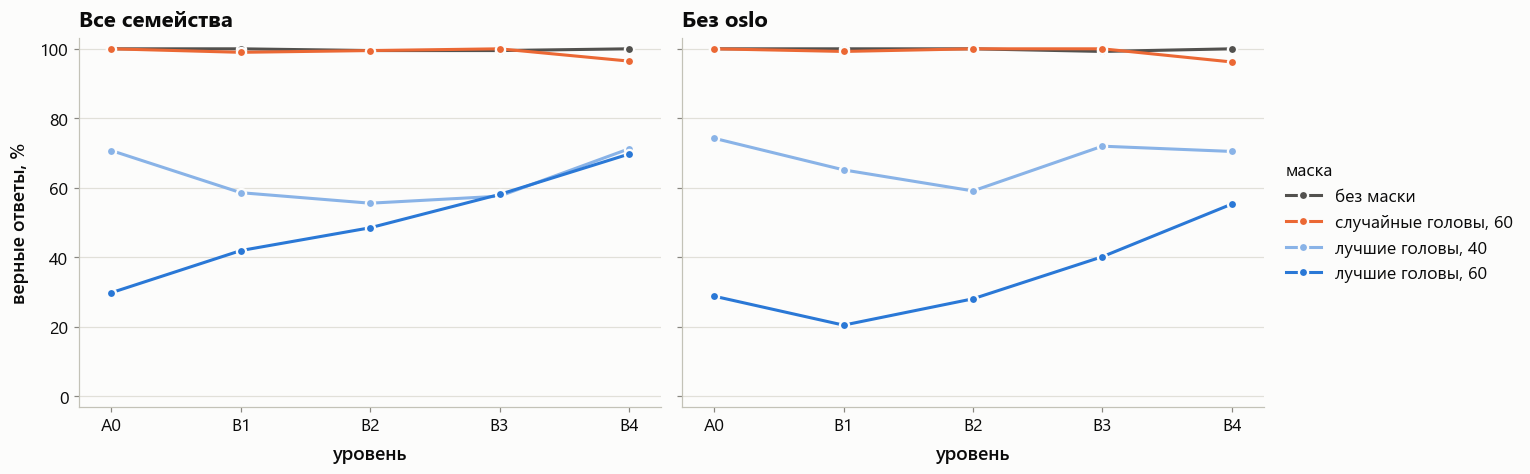

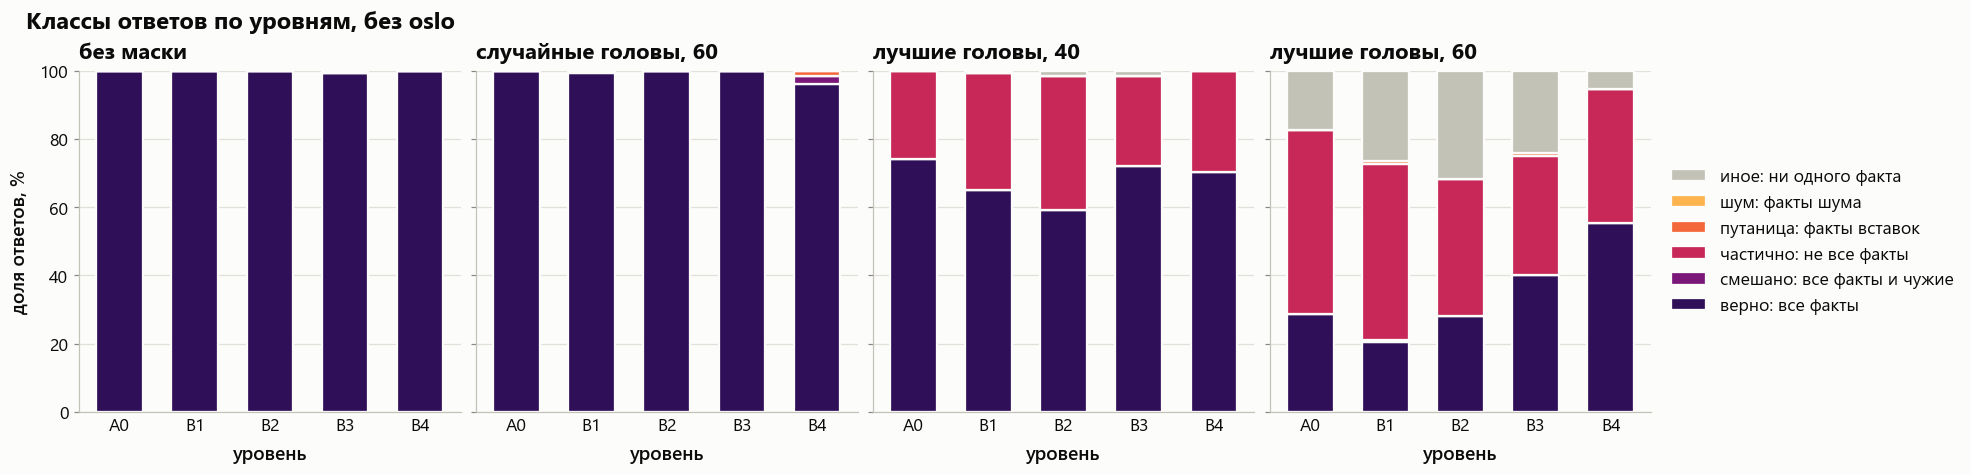

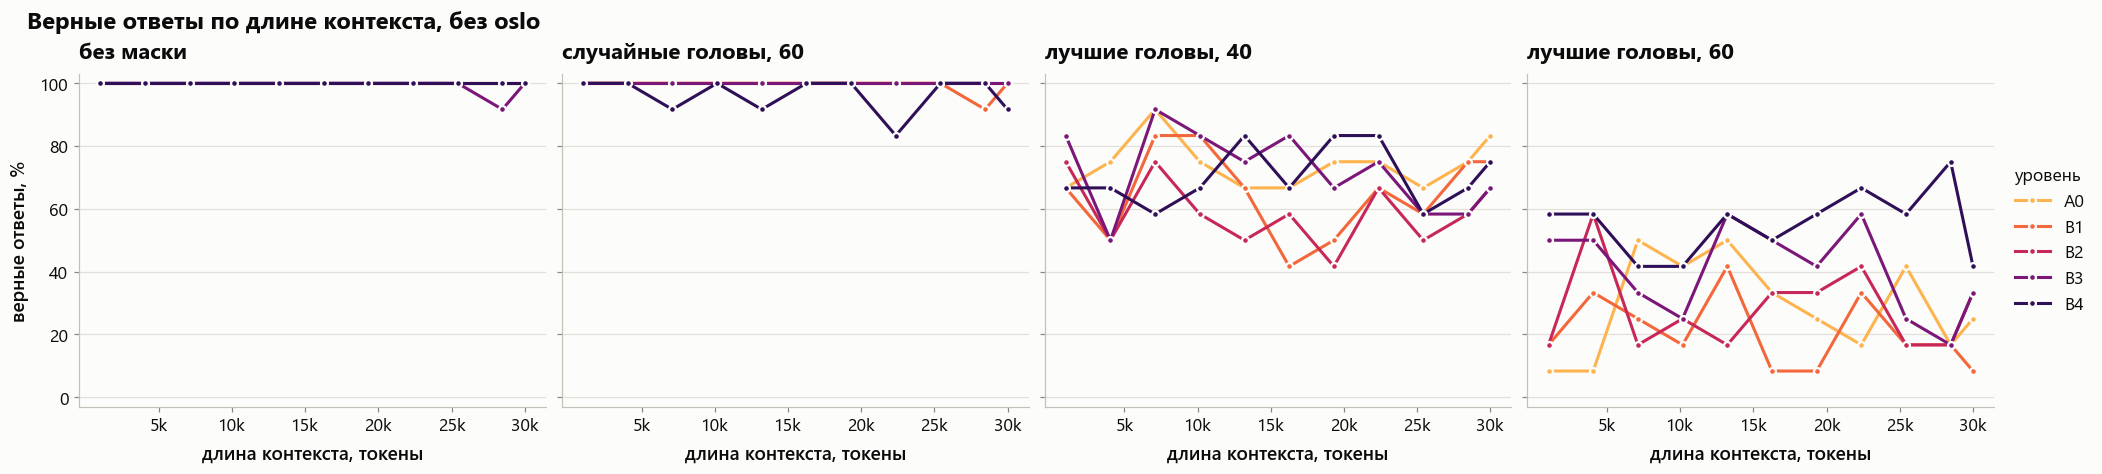

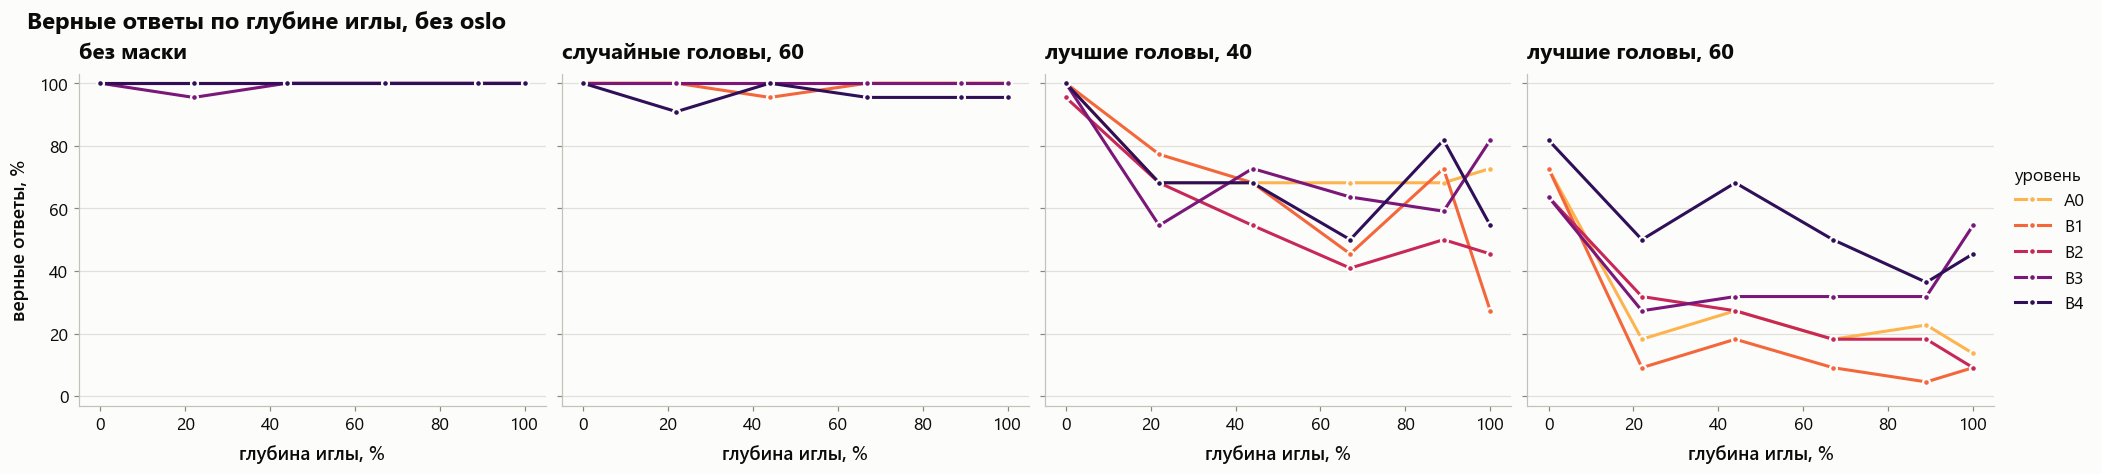

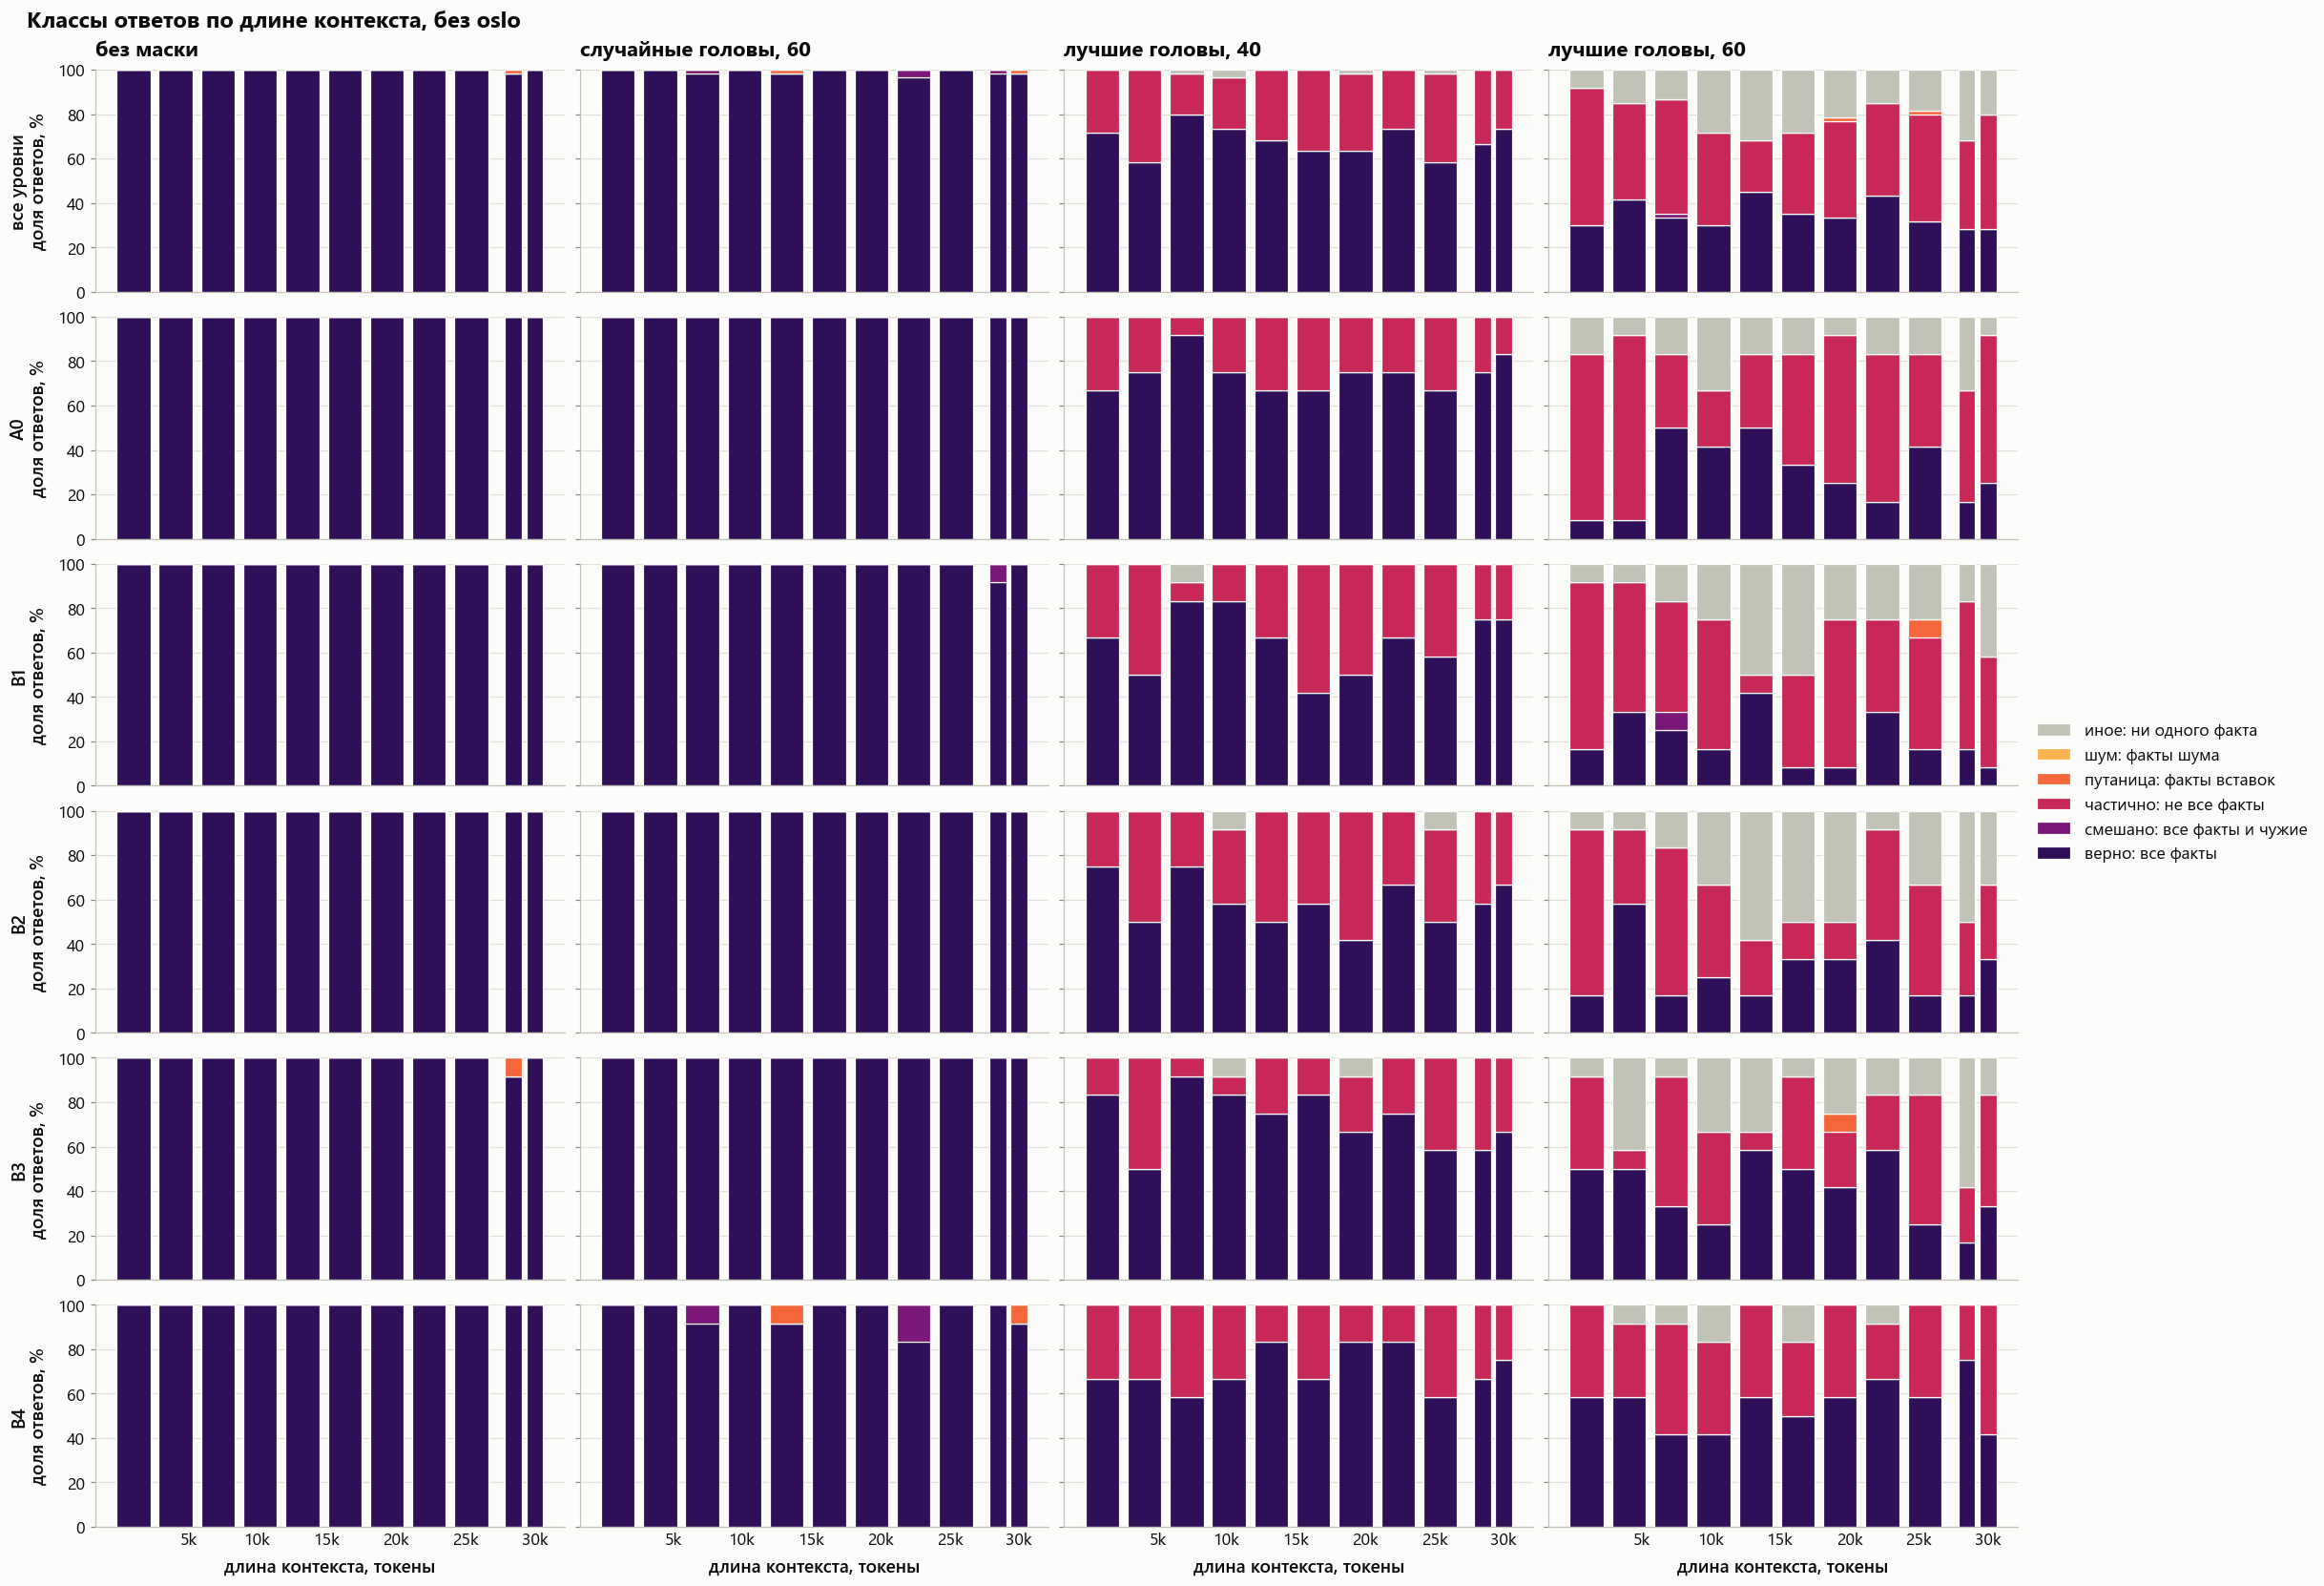

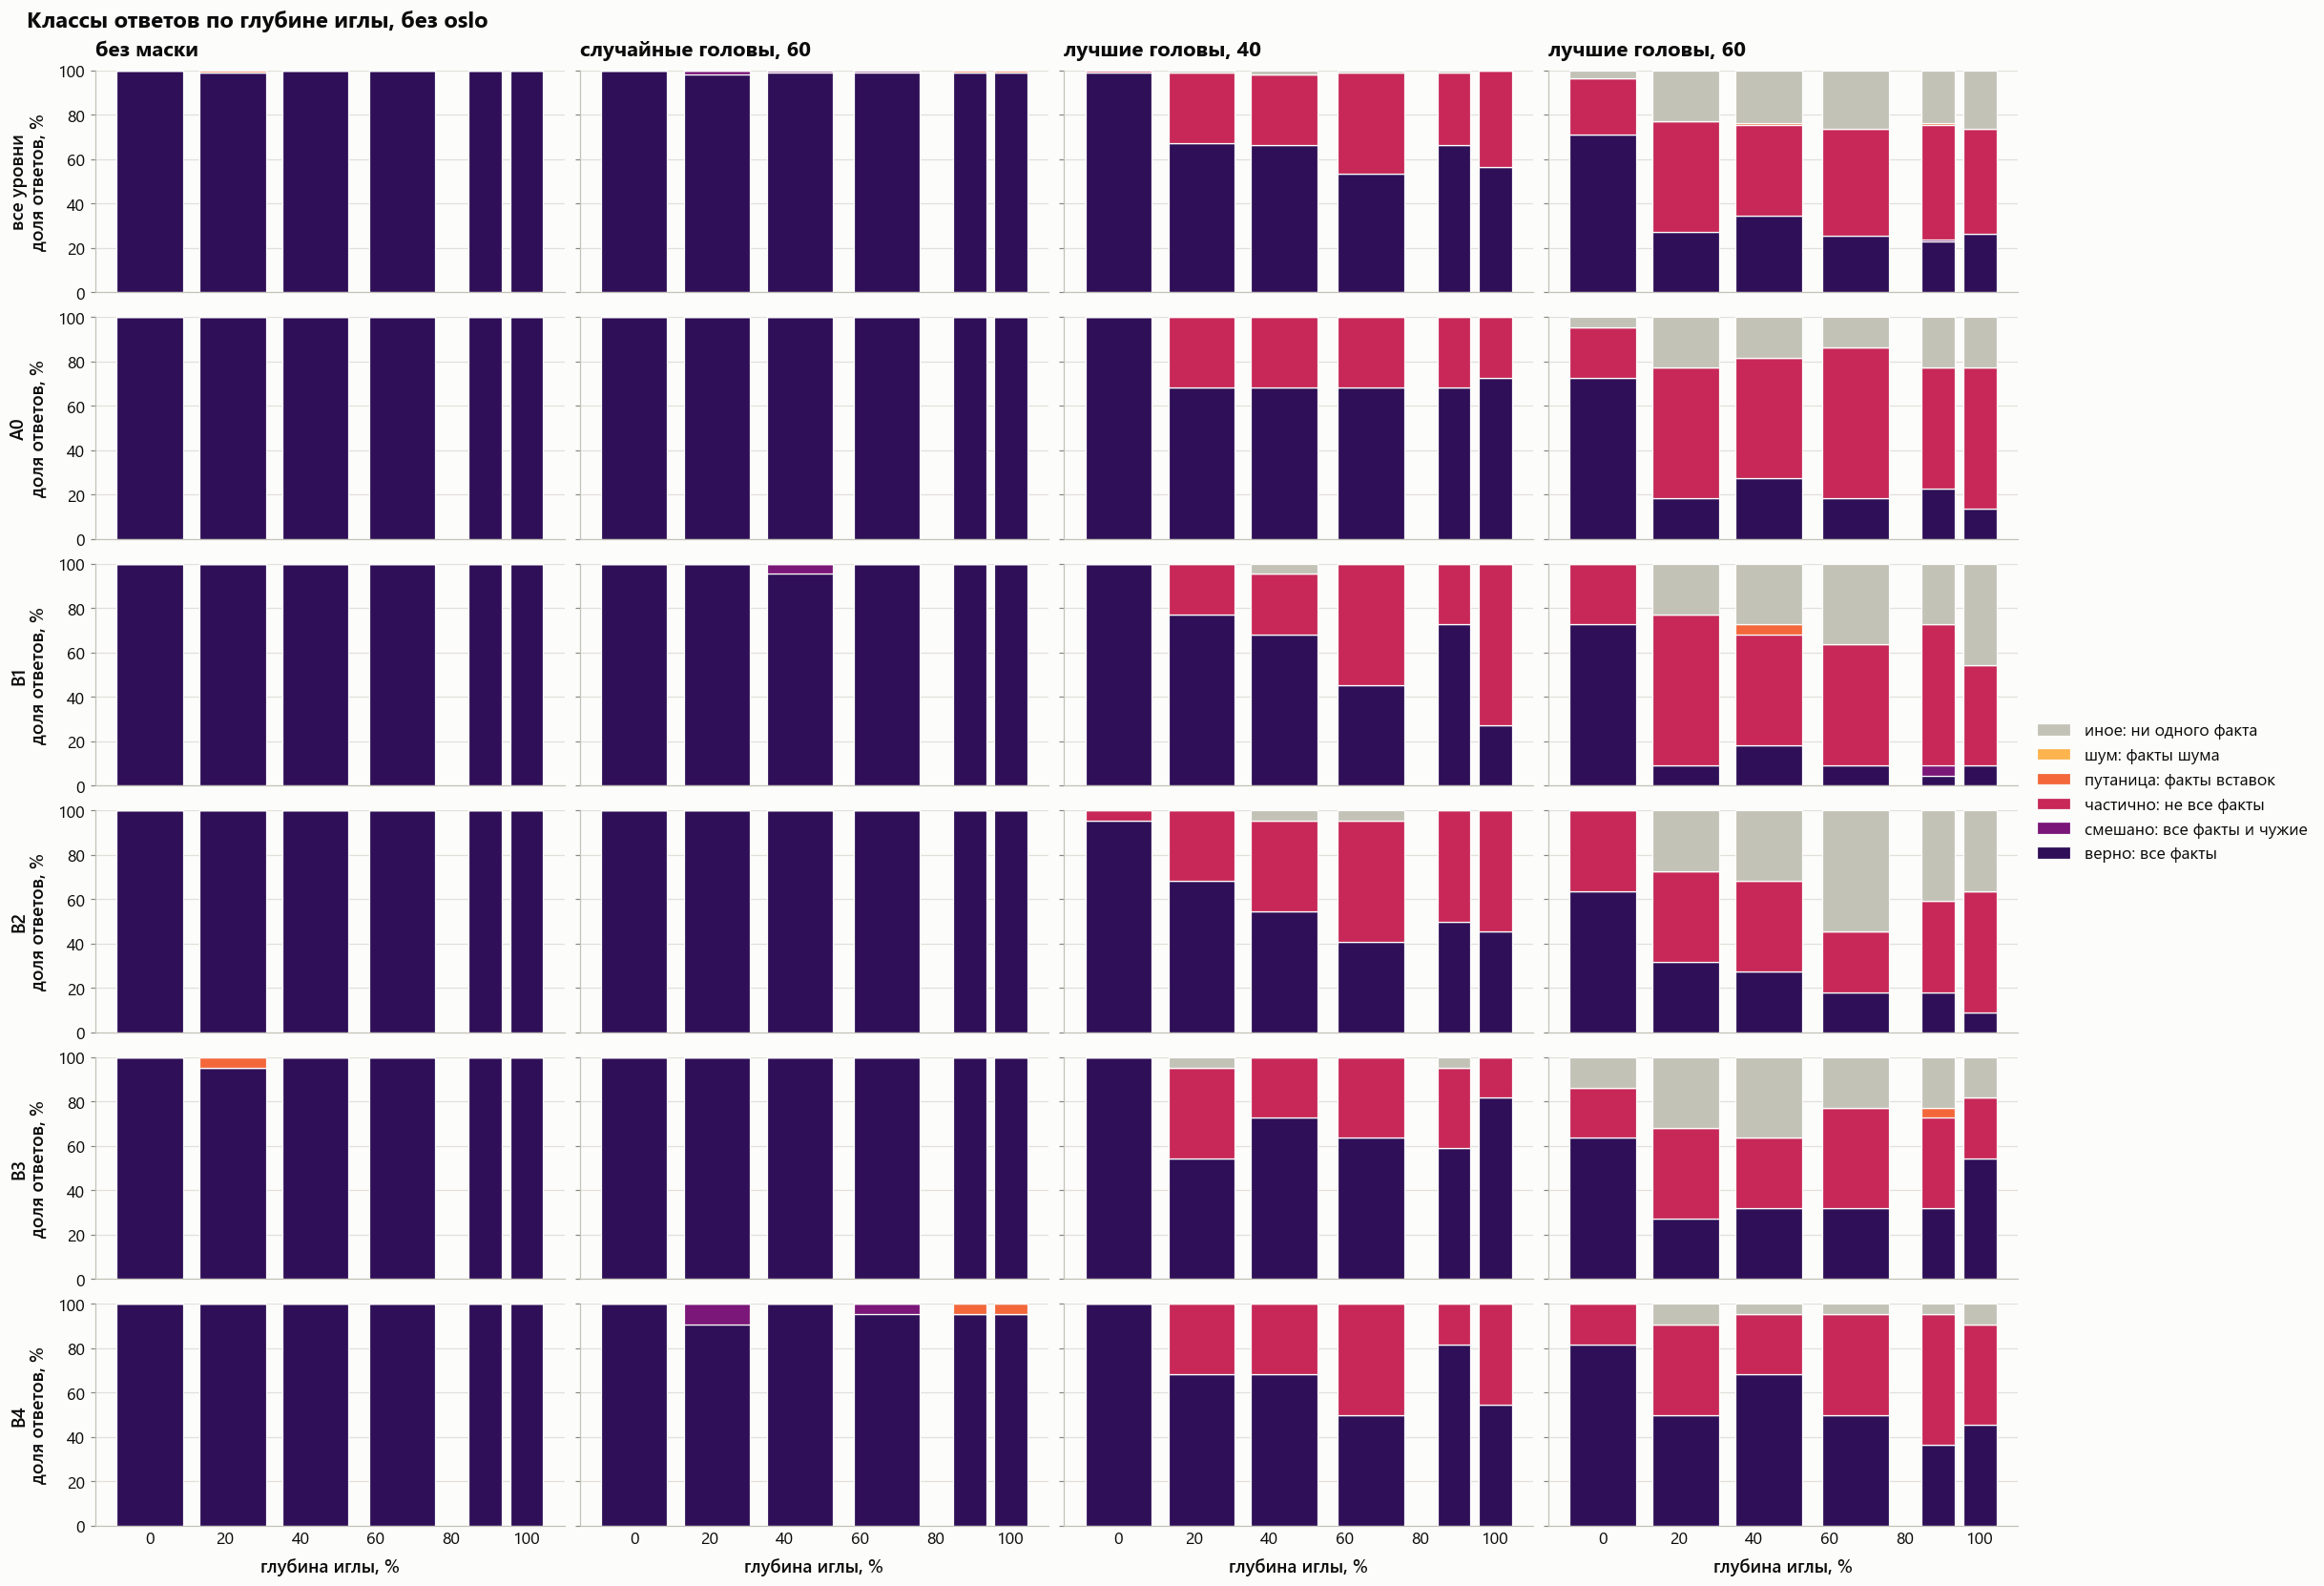

In [16]:
rest = sweep[~sweep["family"].isin(EXCLUDE)]
rest_none = rest[rest["run"] == "none"]
print(f"семейства: {sorted(rest['family'].unique())}; примеров без маски: {len(rest_none)}")

print("без маски: верные ответы, %")
display(hard.by_level(rest_none, by=("family", "level")))

print("верные ответы, %: без oslo")
display(hard.by_level(rest))
print("для сравнения — все три семейства")
display(hard.by_level(sweep))

axes = panels(2, 5.6, extra=2.6, sharey=True)
plots.level_lines(sweep, "correct", ax=axes[0], title="Все семейства")
plots.level_lines(rest, "correct", ax=axes[1], title="Без oslo")
axes[0].get_legend().remove()
axes[1].set_ylabel("")
show(axes, "B_rest_correct_by_level")

show(plots.class_panels(rest, hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по уровням, без oslo"), "B_rest_classes_by_run")

# те же верные ответы в разрезе длины контекста и глубины иглы: панель на прогон, линия на уровень
show(plots.level_gradation(rest, "context_length", title="Верные ответы по длине контекста, без oslo"), "B_rest_correct_by_length")
show(plots.level_gradation(rest, "depth_percent", title="Верные ответы по глубине иглы, без oslo"), "B_rest_correct_by_depth")

show(plots.class_gradation(rest, "context_length", hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по длине контекста, без oslo"), "B_rest_classes_by_length")
show(plots.class_gradation(rest, "depth_percent", hard.CLASSES, hard.CLASS_LABELS, title="Классы ответов по глубине иглы, без oslo"), "B_rest_classes_by_depth")

### На тех же примерах, без `oslo`

Доля примеров, верных без маски, которые остались верными под маской.

In [17]:
kept_rest = hard.paired(rest)
display(kept_rest)

print(f"разница с {BASE}, процентные пункты: без oslo")
display(kept_rest.loc[kept_rest.index != "n"].sub(kept_rest.loc[kept_rest.index != "n", BASE], axis=0).round(1))
print("та же разница по всем трём семействам")
display(kept.loc[kept.index != "n"].sub(base_kept, axis=0).round(1))

level,A0,B1,B2,B3,B4
n,132.0,127.0,132.0,131.0,132.0
random60,100.0,99.2,100.0,100.0,96.2
top40,74.2,63.8,59.1,71.8,70.5
top60,28.8,19.7,28.0,40.5,55.3


разница с A0, процентные пункты: без oslo


level,A0,B1,B2,B3,B4
random60,0.0,-0.8,0.0,0.0,-3.8
top40,0.0,-10.4,-15.1,-2.4,-3.7
top60,0.0,-9.1,-0.8,11.7,26.5


та же разница по всем трём семействам


level,A0,B1,B2,B3,B4
random60,0.0,-1.0,0.0,0.0,-3.5
top40,0.0,-13.2,-14.9,-13.3,0.5
top60,0.0,12.2,18.9,28.6,39.9


### Где ломается: длина и глубина, без `oslo`

В ячейке два примера (по одному на семейство).

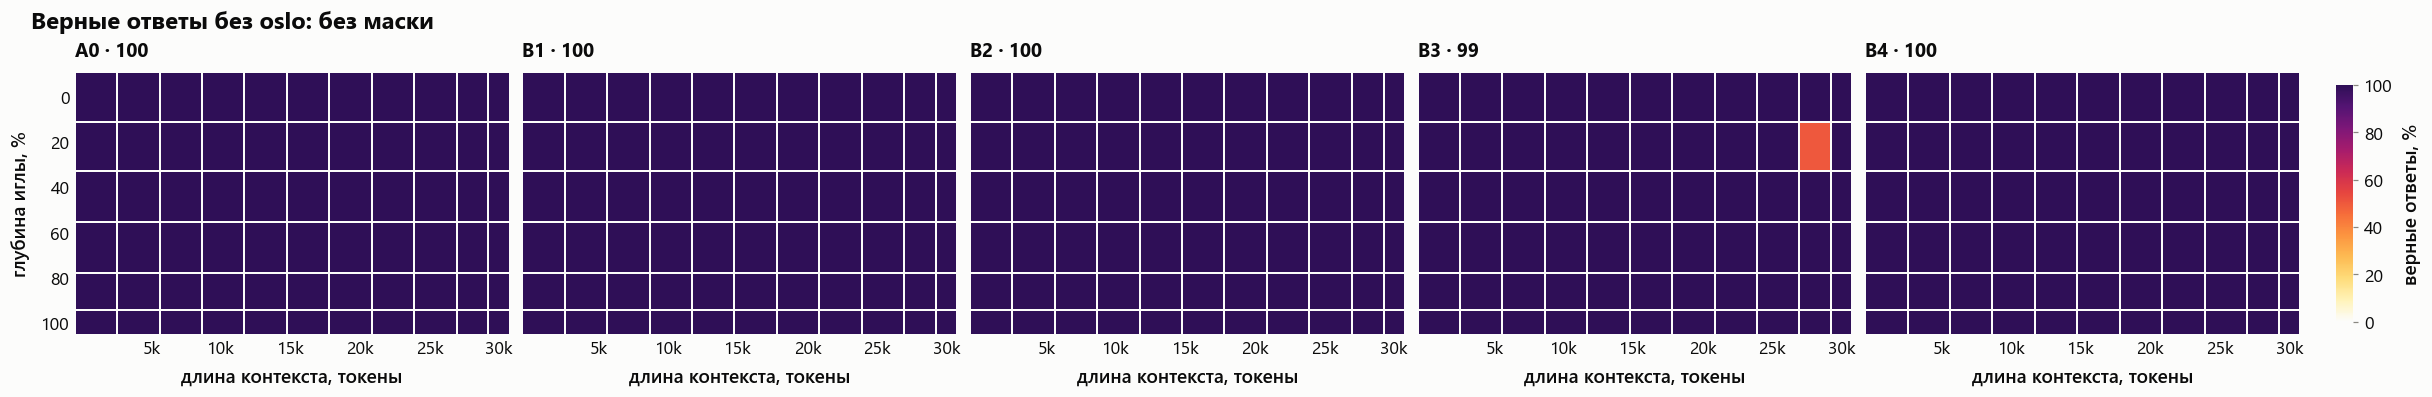

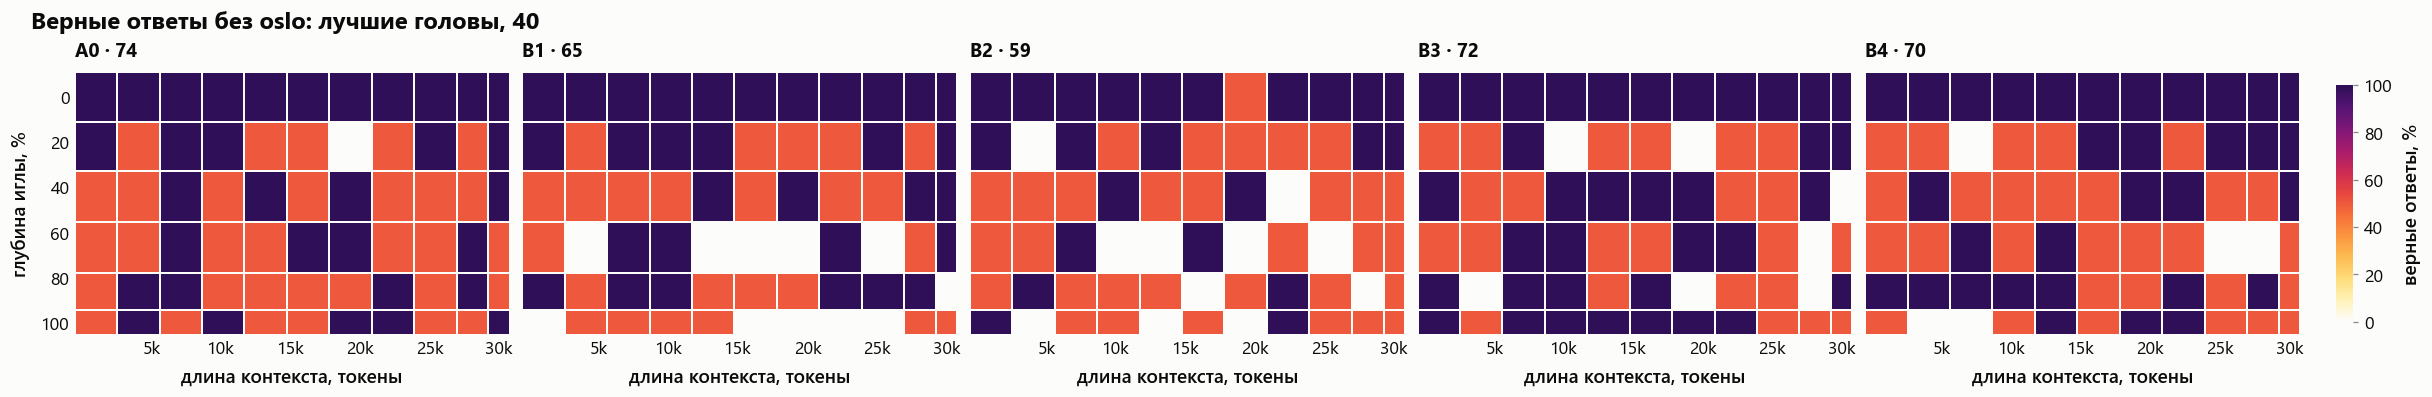

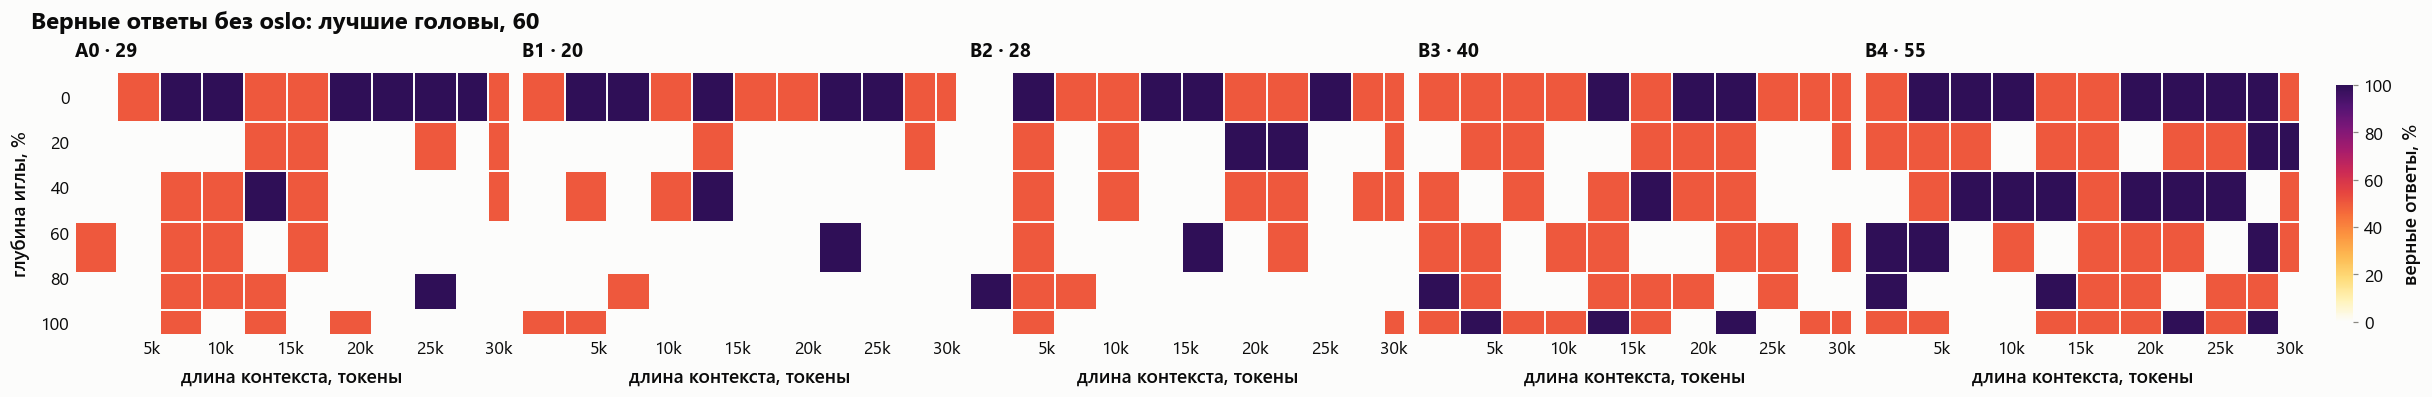

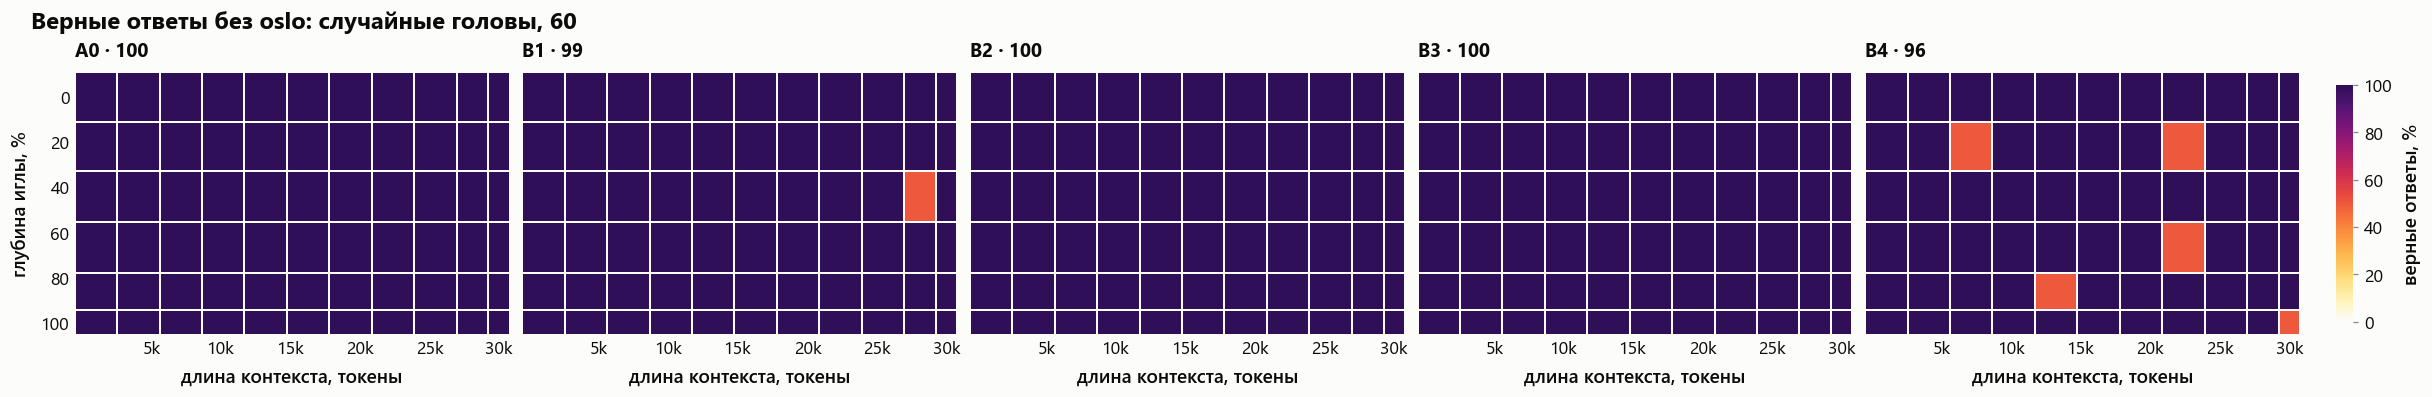

In [18]:
for run in [r for r in ("none", "top40", "top60", "random60") if r in set(rest["run"])]:
    part = rest[rest["run"] == run]
    name = plots.run_styles(rest)[run][1]
    show(plots.niah_grid(part.assign(run=part["level"]), {level: level for level in levels}, value="correct", columns=len(levels),
                         title=f"Верные ответы без oslo: {name}"), f"B_rest_niah_{run}")

## 2.4. Формулировки ответов: перефраз, замены, формы слов

Класс по фактам говорит, названы ли ключевые факты. Здесь тот же ответ разбирается подробнее: эталон разбит на части, и для каждой части смотрим, как она записана. Это тот же разбор, что в ноутбуках по задаче статьи и по оси A, с теми же списками формулировок: игла и эталон те же.

| Уровень формулировки | Что это | Пример |
|---|---|---|
| дословно | формулировка эталона | `cooked with` |
| другая форма слова | те же слова в другой форме, с другим артиклем или в другом порядке | `cooking it with`; `a brass bell`; `black clay bowl` |
| синоним, смысл сохранён | другие слова с тем же смыслом | `prepared using`; `when they arrive` вместо `at the entrance` |
| потеряна деталь | часть названа, но без существенной детали | `ring a bell` без `brass`; `smoked lemon` без `peel`; `red roof` без `slate` |
| нет | части в ответе нет | — |

Часть считается сохранённой на первых трёх уровнях. Списки формулировок лежат в `vizual/paraphrase.py` (`FACTS`); они собраны вручную по ответам прогонов оси A, и отнесение формулировки к уровню — моё решение.

| Структура ответа | Условие |
|---|---|
| точная фраза | эталон стоит в ответе дословно и подряд |
| все части дословно, другой порядок или вставка | все части дословно, но фраза не совпадает |
| все части, есть форма слова или синоним | все части сохранены, хотя бы одна не дословно — перефразированный полный ответ |
| не все части, остальные дословно | часть пропала, оставшиеся дословно — обрезанный ответ |
| не все части, есть форма, синоним или потеря детали | часть пропала или потеряла деталь |
| ни одной части | ответ не из иглы — в том числе списанный с близнеца |

Этот разбор смотрит только на части **иглы**. Списан ли ответ с близнеца, он не различает — это делает класс по фактам (раздел 2.2).

In [19]:
worded = paraphrase.annotate(sweep)
worded_none = worded[worded["run"] == "none"]
fact_names = {family: list(paraphrase.FACTS[worded.loc[worded["family"] == family, "reference"].iloc[0]]) for family in families}

# что именно написано вместо формулировки эталона: по всем прогонам
pd.set_option("display.max_rows", 200)
paraphrase.wordings(worded, top=5).set_index(["эталон", "факт", "уровень"])

написано  \
эталон                                                                       факт                  уровень                                                      
ring the brass bell at the entrance and sign the guest book with a green pen ring the brass bell   другая форма слова                       ring a brass bell   
                                                                                                   другая форма слова                  ringing the brass bell   
                                                                                                   другая форма слова                    ringing a brass bell   
                                                                                                   другая форма слова                    ringe the brass bell   
                                                                                                   другая форма слова                    rings the brass bell   
                                                                                                   потеряна деталь                              ring the bell   
                                                                                                   потеряна деталь                                ring a bell   
                                                                                                   потеряна деталь                             rings the bell   
                                                                             sign the guest book   другая форма слова                       sign a guest book   
                                                                                                   другая форма слова                        sign a guestbook   
                                                                                                   другая форма слова                  signing the guest book   
                                                                                                   другая форма слова                      sign the guestbook   
                                                                                                   другая форма слова                    signs the guest book   
                                                                                                   синоним, смысл сохранён    sign their name in a guest book   
                                                                                                   синоним, смысл сохранён     sign their name in a guestbook   
                                                                                                   синоним, смысл сохранён  sign their name in the guest book   
                                                                                                   потеряна деталь                                 guest book   
                                                                                                   потеряна деталь                                  guestbook   
                                                                             with a green pen      синоним, смысл сохранён                     in a green pen   
                                                                                                   потеряна деталь                                  green pen   
cooked with smoked lemon peel and served in a bowl of black clay             smoked lemon peel     потеряна деталь                               smoked lemon   
                                                                             served in             потеряна деталь                                     served   
                                                                                                   потеряна деталь                                    serving   
                                                                                                   потеряна деталь          

### Без маски: как модель формулирует ответ на каждом уровне

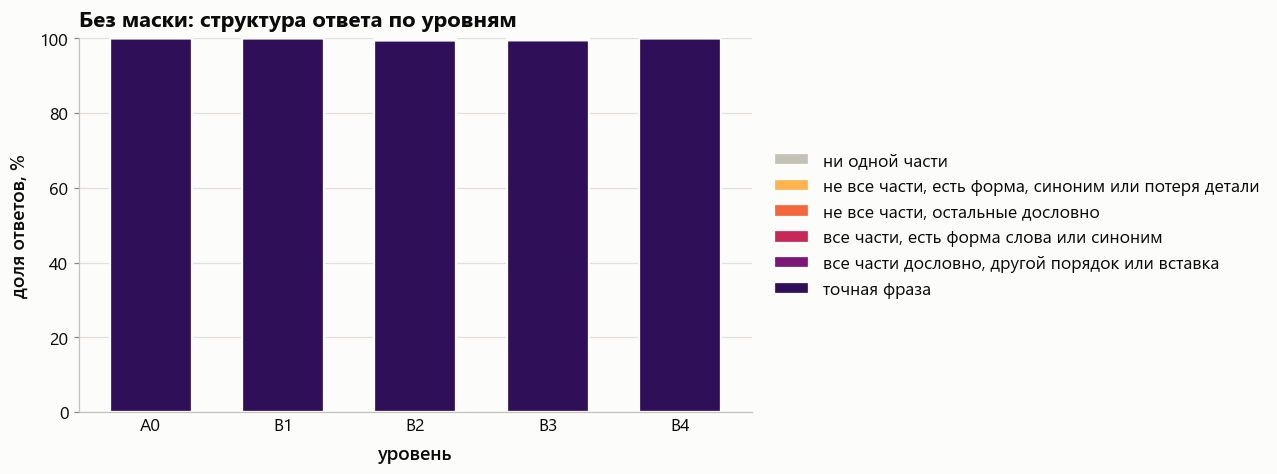

без маски: доля ответов каждой структуры, %


structure     точная фраза  не все части, остальные дословно  ни одной части
family level                                                                
cairo  A0            100.0                               0.0             0.0
       B1            100.0                               0.0             0.0
       B2            100.0                               0.0             0.0
       B3             98.5                               1.5             0.0
       B4            100.0                               0.0             0.0
lisbon A0            100.0                               0.0             0.0
       B1            100.0                               0.0             0.0
       B2            100.0                               0.0             0.0
       B3            100.0                               0.0             0.0
       B4            100.0                               0.0             0.0
oslo   A0            100.0                               0.0             0.0
       B1            100.0                               0.0             0.0
       B2             98.5                               0.0             1.5
       B3            100.0                               0.0             0.0
       B4            100.0                               0.0             0.0

In [20]:
ax = plt.subplots(figsize=style.size(11.5, 4.2))[1]
show(plots.stacked(worded_none, "level", "structure", paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, xlabel="уровень", ax=ax,
                   title="Без маски: структура ответа по уровням"), "B_structure_none")

print("без маски: доля ответов каждой структуры, %")
display((pd.crosstab([worded_none["family"], worded_none["level"]], worded_none["structure"], normalize="index") * 100).reindex(
    columns=[k for k in paraphrase.STRUCTURES if k in set(worded_none["structure"])]).rename(columns=paraphrase.STRUCTURE_LABELS).round(1))

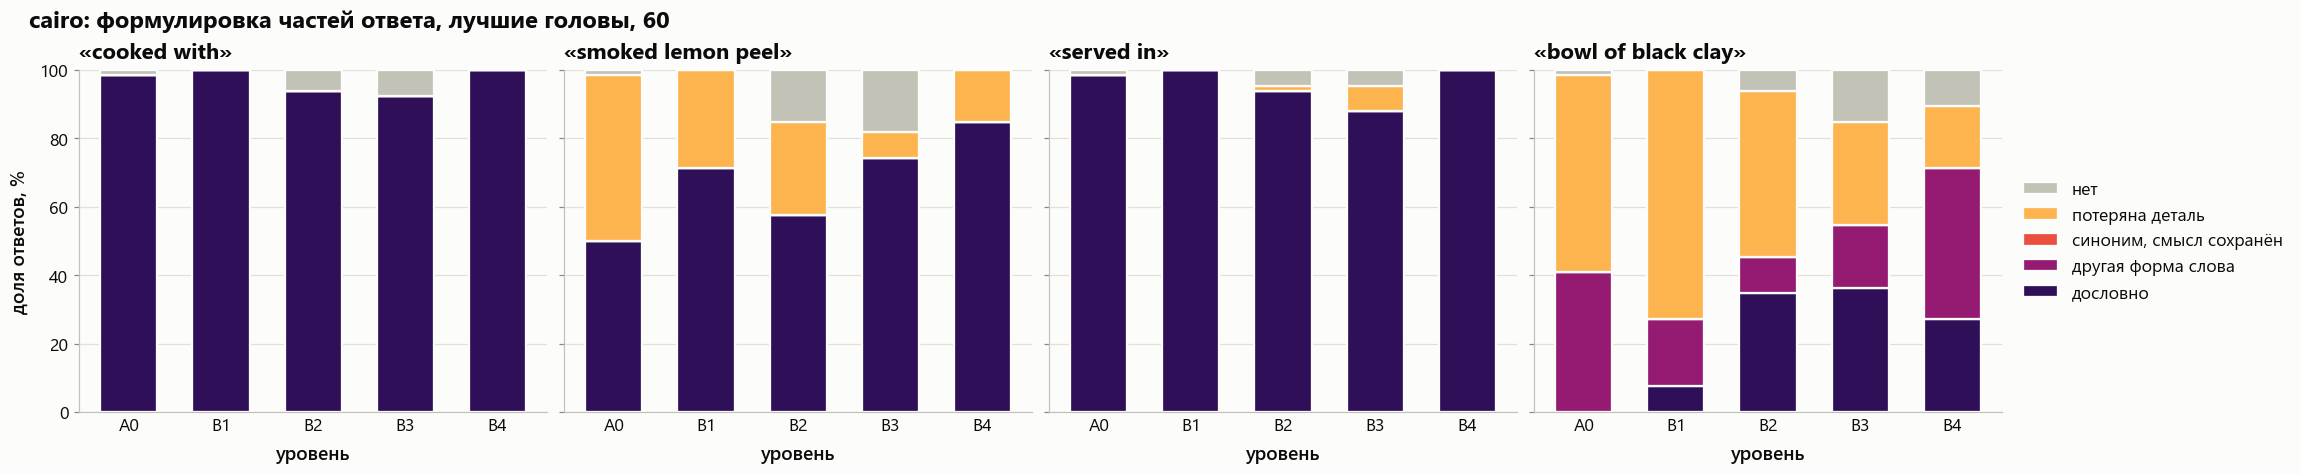

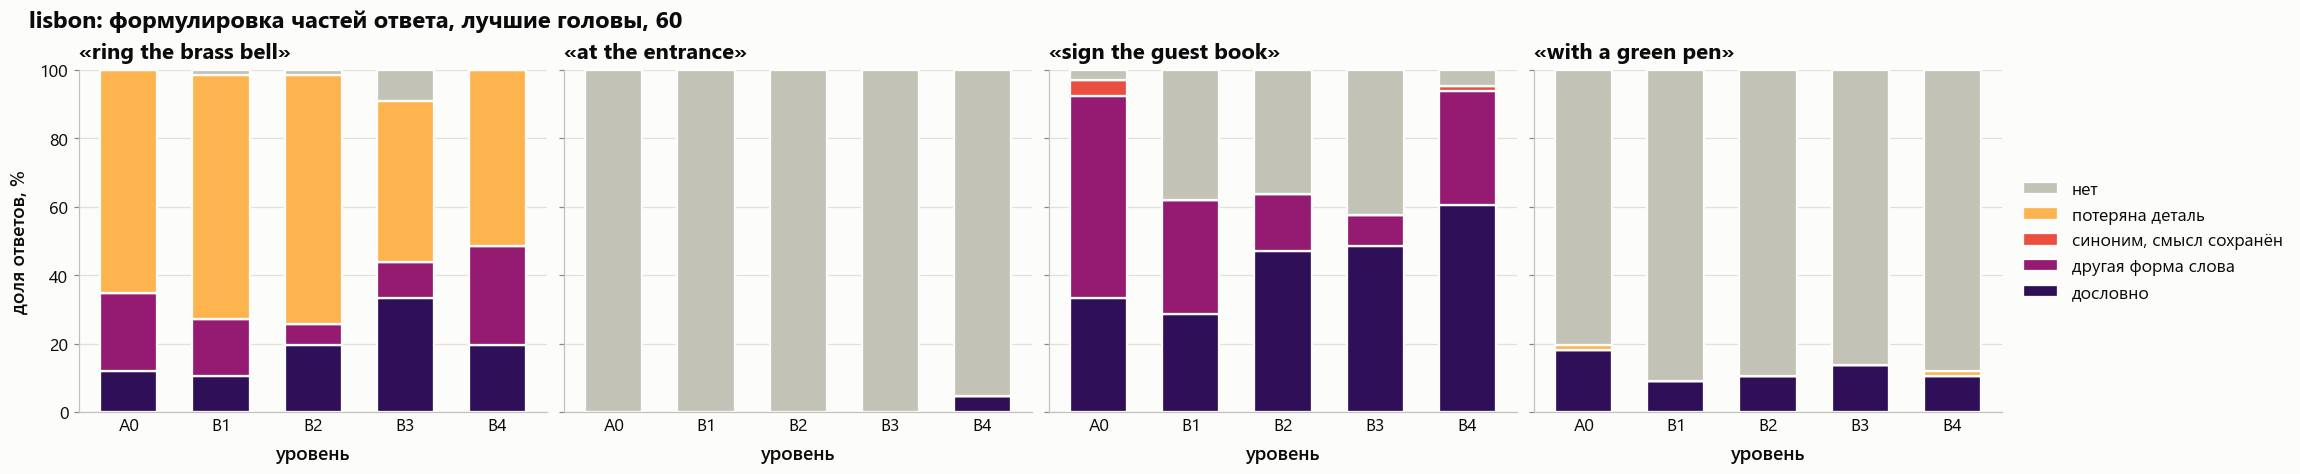

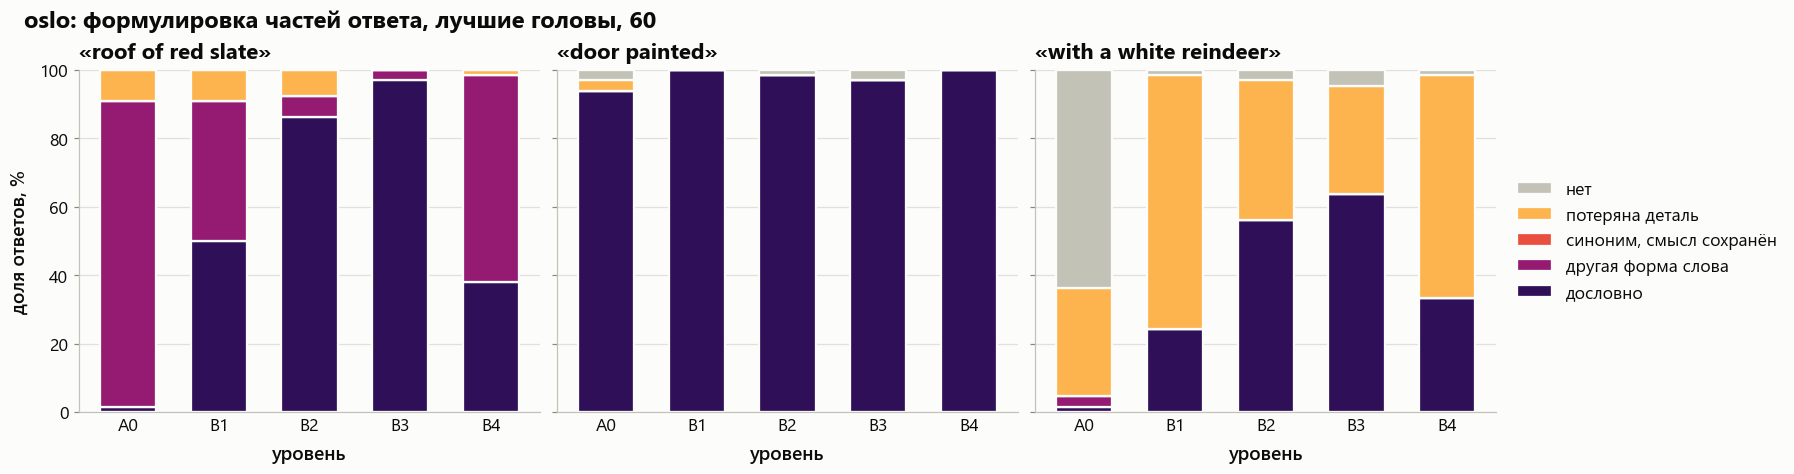

In [21]:
# как записана каждая часть эталона под маской 60 лучших голов: панель на часть, ряд на семейство
WORDING_RUN = "top60"
for family in families:
    part = worded[(worded["run"] == WORDING_RUN) & (worded["family"] == family)]
    names = fact_names[family]
    axes = panels(len(names), 4.6, extra=2.4, sharey=True)
    for ax, fact in zip(axes, names):
        plots.stacked(part, "level", fact, paraphrase.LEVELS, paraphrase.LEVEL_LABELS, xlabel="уровень", legend=ax is axes[-1], ax=ax, title=f"«{fact}»")
        if ax is not axes[0]:
            ax.set_ylabel("")
    axes[0].figure.suptitle(f"{family}: формулировка частей ответа, {plots.run_styles(sweep)[WORDING_RUN][1]}", x=0.01, ha="left", fontweight="bold")
    show(axes, f"B_fact_wordings_{family}")

### Как класс по фактам оценивает каждую структуру

По всем прогонам оси. `верно` — доля ответов класса «верно» по фактам; `частей` — сколько частей эталона сохранено (у `oslo` частей три, у остальных четыре).

In [22]:
by_structure = worded.groupby("structure").agg(ответов=("id", "size"), частей=("kept_facts", "mean"), верно=("correct", "mean"), слова_близнецов=("twin_words", "mean"),
                                               точная_фраза=("exact", "mean"), rouge1=("rouge1_recall", "mean")).reindex(paraphrase.STRUCTURES)
by_structure[["верно", "слова_близнецов", "точная_фраза"]] *= 100
display(by_structure.round(1).rename(index=paraphrase.STRUCTURE_LABELS))

print("структура против класса по фактам, число ответов")
display(pd.crosstab(worded["structure"], worded["answer_class"]).reindex(paraphrase.STRUCTURES).reindex(
    columns=[c for c in hard.CLASSES if c in set(worded["answer_class"])]).rename(index=paraphrase.STRUCTURE_LABELS, columns=hard.CLASS_LABELS))

,ответов,частей,верно,слова_близнецов,точная_фраза,rouge1
structure,,,,,,
точная фраза,2367,3.6,99.7,0.3,100.0,100.0
"все части дословно, другой порядок или вставка",6,4.0,100.0,0.0,0.0,97.9
"все части, есть форма слова или синоним",347,3.5,66.3,0.0,0.0,99.3
"не все части, остальные дословно",188,2.6,84.0,0.5,0.0,78.0
"не все части, есть форма, синоним или потеря детали",1034,2.0,31.1,0.2,0.0,75.6
ни одной части,13,0.0,0.0,53.8,0.0,34.8


структура против класса по фактам, число ответов


answer_class,верно: все факты,смешано: все факты и чужие,частично: не все факты,путаница: факты вставок,иное: ни одного факта
structure,,,,,
точная фраза,2359,8,0,0,0
"все части дословно, другой порядок или вставка",6,0,0,0,0
"все части, есть форма слова или синоним",230,0,117,0,0
"не все части, остальные дословно",158,0,26,1,3
"не все части, есть форма, синоним или потеря детали",322,0,567,1,144
ни одной части,0,0,0,6,7


### Под масками

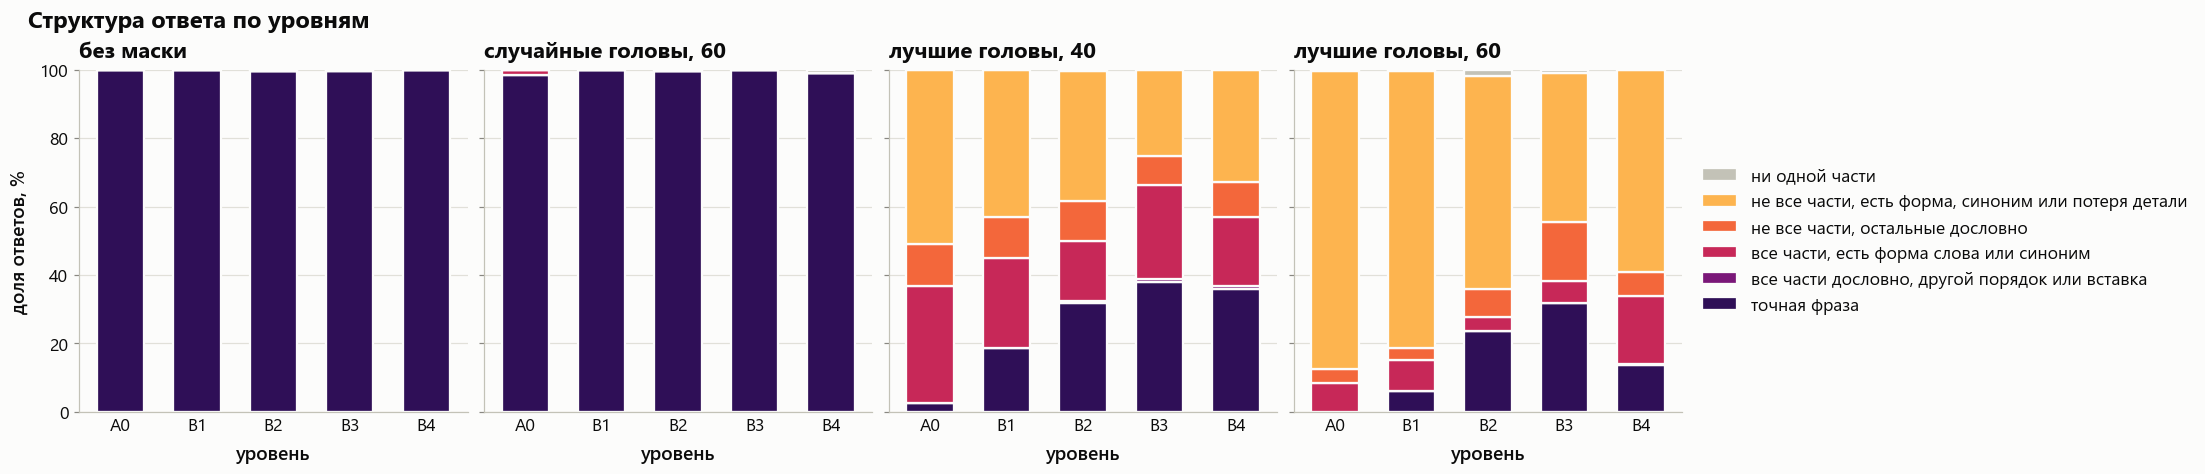

ответы со всеми частями эталона (дословно, формой слова или синонимом), %


level,A0,B1,B2,B3,B4
run,,,,,
none,100.0,100.0,99.5,99.5,100.0
random60,100.0,100.0,99.5,100.0,99.0
top40,36.9,44.9,50.0,66.2,57.1
top60,8.6,15.2,27.8,38.4,33.8


из них перефразированные (не точная фраза), %


level,A0,B1,B2,B3,B4
run,,,,,
none,0.0,0.0,0.0,0.0,0.0
random60,1.5,0.0,0.0,0.0,0.0
top40,93.2,58.4,36.4,42.7,37.2
top60,100.0,60.0,14.5,17.1,59.7


In [23]:
show(plots.class_panels(worded, paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, column="structure", title="Структура ответа по уровням"), "B_structure_by_run")

full = worded["structure"].isin(["exact", "reordered", "reworded"])
print("ответы со всеми частями эталона (дословно, формой слова или синонимом), %")
display(hard.by_level(worded.assign(full=full), "full"))
print("из них перефразированные (не точная фраза), %")
display(hard.by_level(worded[full].assign(reworded=lambda d: d["structure"] != "exact"), "reworded"))

In [24]:
# примеры: по два самых коротких ответа каждой структуры на уровнях с близнецами
examples = worded[(~worded["exact"]) & (worded["level"] != BASE)].sort_values("n_tokens").groupby("structure").head(2)
examples.assign(структура=examples["structure"].map(paraphrase.STRUCTURE_LABELS)).set_index("структура").loc[
    [paraphrase.STRUCTURE_LABELS[k] for k in paraphrase.STRUCTURES if k in set(examples["structure"])],
    ["run", "family", "level", "answer_class", "response"]]

,run,family,level,answer_class,response
структура,,,,,
"все части дословно, другой порядок или вставка",top40,cairo,B3,correct,The famous soup of the Zahira Cafe in Cairo is cooked with smoked lemon peel and is served in a bowl of black clay.
"все части дословно, другой порядок или вставка",top40,cairo,B3,correct,The famous soup of the Zahira Cafe in Cairo is cooked with smoked lemon peel and is served in a bowl of black clay.
"все части, есть форма слова или синоним",top40,oslo,B3,partial,The oldest house in Oslo has a roof of red slates and a door painted with a white reindeer.
"все части, есть форма слова или синоним",top40,oslo,B3,partial,The oldest house in Oslo has a roof of red slates and a door painted with a white reindeer.
"не все части, остальные дословно",top60,lisbon,B3,correct,ring the brass bell and sign the guest book
"не все части, остальные дословно",top60,oslo,B3,partial,The oldest house in Oslo has a roof of red slate.
"не все части, есть форма, синоним или потеря детали",top40,oslo,B3,other,The oldest house in Oslo has a roof of red slates.
"не все части, есть форма, синоним или потеря детали",top60,lisbon,B3,other,Every visitor to the Lisbon Tram Museum is asked to ring the bell.
ни одной части,top60,lisbon,B2,other,Every visitor to the Lisbon Tram Museum is asked to wind the clock.


## 2.5. Формулировки ответов без семейства `oslo`

Тот же разбор, что в разделе 2.4, на семействах `cairo` и `lisbon`.

семейства: ['cairo', 'lisbon']; примеров без маски: 655


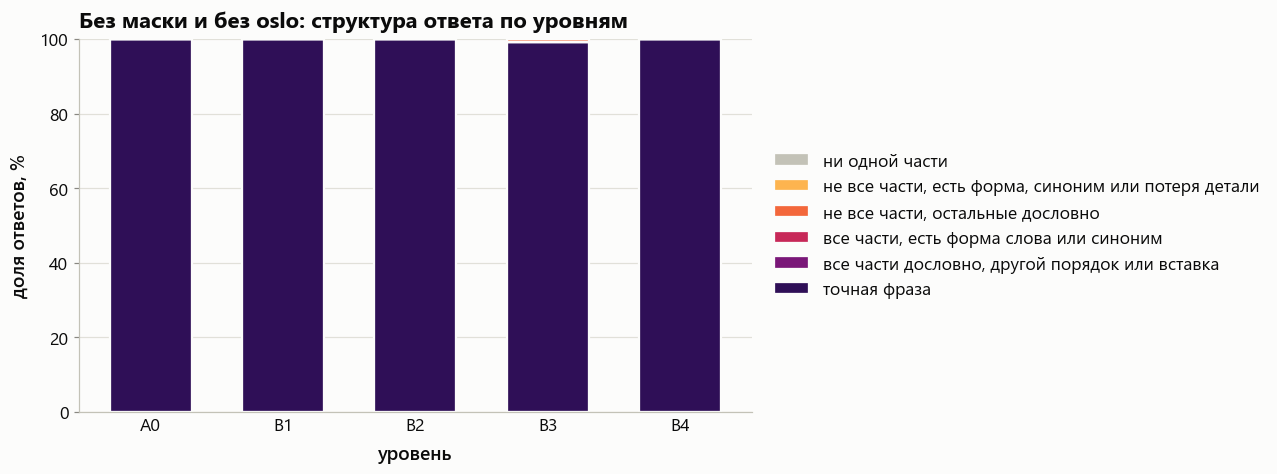

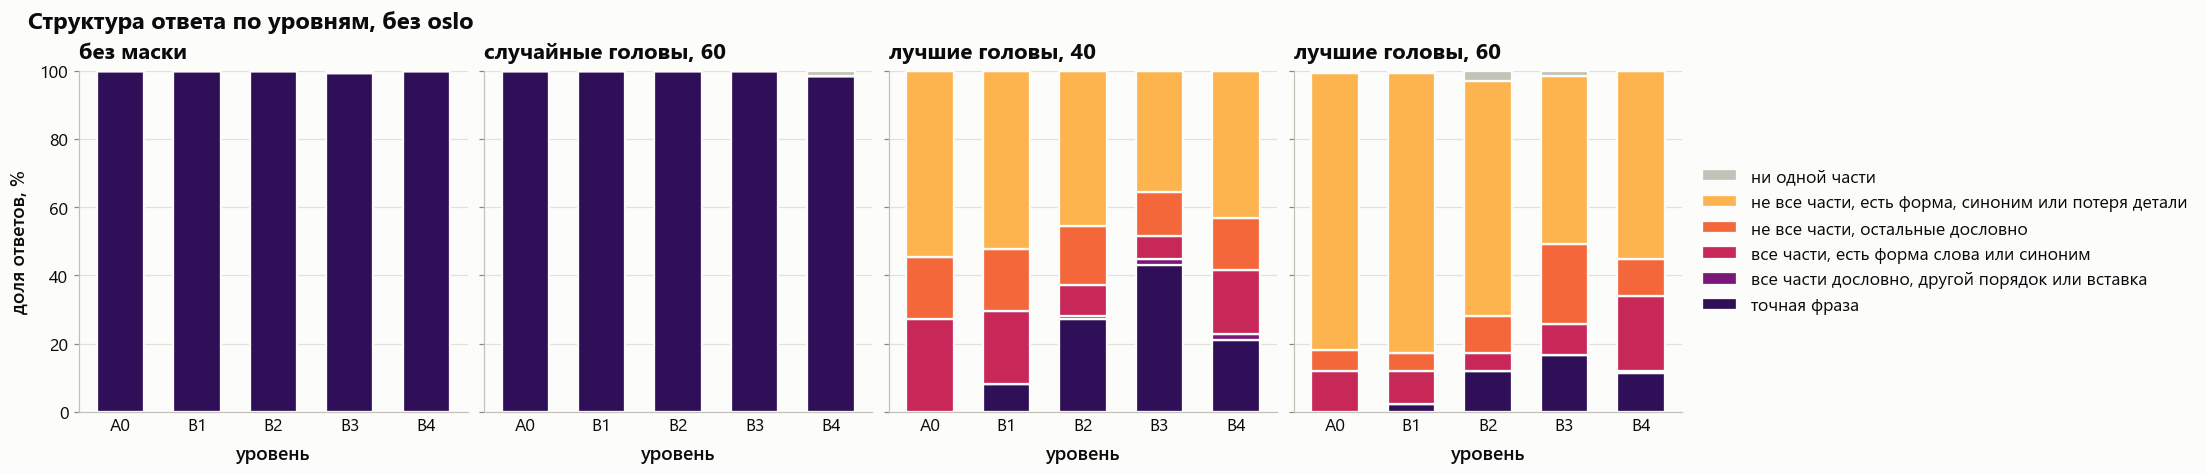

ответы со всеми частями эталона (дословно, формой слова или синонимом), %: без oslo


level,A0,B1,B2,B3,B4
run,,,,,
none,100.0,100.0,100.0,99.2,100.0
random60,100.0,100.0,100.0,100.0,98.5
top40,27.3,29.5,37.1,51.5,41.7
top60,12.1,12.1,17.4,25.8,34.1


то же по всем трём семействам


level,A0,B1,B2,B3,B4
run,,,,,
none,100.0,100.0,99.5,99.5,100.0
random60,100.0,100.0,99.5,100.0,99.0
top40,36.9,44.9,50.0,66.2,57.1
top60,8.6,15.2,27.8,38.4,33.8


структура против класса по фактам, число ответов: без oslo


answer_class,верно: все факты,смешано: все факты и чужие,частично: не все факты,путаница: факты вставок,иное: ни одного факта
structure,,,,,
точная фраза,1495,5,0,0,0
"все части дословно, другой порядок или вставка",6,0,0,0,0
"все части, есть форма слова или синоним",187,0,0,0,0
"не все части, остальные дословно",158,0,21,1,3
"не все части, есть форма, синоним или потеря детали",140,0,474,1,134
ни одной части,0,0,0,3,7


In [25]:
worded_rest = worded[~worded["family"].isin(EXCLUDE)]
worded_rest_none = worded_rest[worded_rest["run"] == "none"]
print(f"семейства: {sorted(worded_rest['family'].unique())}; примеров без маски: {len(worded_rest_none)}")

ax = plt.subplots(figsize=style.size(11.5, 4.2))[1]
show(plots.stacked(worded_rest_none, "level", "structure", paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, xlabel="уровень", ax=ax,
                   title="Без маски и без oslo: структура ответа по уровням"), "B_rest_structure_none")

show(plots.class_panels(worded_rest, paraphrase.STRUCTURES, paraphrase.STRUCTURE_LABELS, column="structure", title="Структура ответа по уровням, без oslo"), "B_rest_structure_by_run")

full_rest = worded_rest["structure"].isin(["exact", "reordered", "reworded"])
print("ответы со всеми частями эталона (дословно, формой слова или синонимом), %: без oslo")
display(hard.by_level(worded_rest.assign(full=full_rest), "full"))
print("то же по всем трём семействам")
display(hard.by_level(worded.assign(full=full), "full"))

print("структура против класса по фактам, число ответов: без oslo")
display(pd.crosstab(worded_rest["structure"], worded_rest["answer_class"]).reindex(paraphrase.STRUCTURES).reindex(
    columns=[c for c in hard.CLASSES if c in set(worded_rest["answer_class"])]).rename(index=paraphrase.STRUCTURE_LABELS, columns=hard.CLASS_LABELS))

# 3. Метрики голов

Только прогон без маски. Скоры считаются по верно отвеченным примерам.

| Метрика | Годится? | Почему |
|---|---|---|
| `copy_recall`, `copy_count` — скор копирования из статьи | да | игла и вопрос не менялись, ответ списывается из иглы; близнецы в этот скор не входят — засчитывается только токен внутри ответа иглы |
| частота активации | да | доля примеров, где голова скопировала хотя бы один токен иглы |
| `needle_mass`, `needle_attention_mass` — масса внимания на ответе в игле | да | куда голова смотрит, независимо от формулировки ответа |
| `needle_sentence_mass` — масса на всей игле | да, основная для сравнения с близнецами | игла и близнец — целые предложения одного шаблона, поэтому сравнивать нужно предложение с предложением |
| `competing_max_mass` — масса на самом сильном близнеце | да | один близнец против одной иглы: сравнимо между уровнями с одним и с тремя близнецами |
| `competing_mass` — масса на всех близнецах вместе | да, с оговоркой | на B2 и B3 это сумма по трём вставкам, на B1 и B4 — по одной; между ними напрямую не сравнивается |
| `copy_sentence` и `copy_competing` — копирование из иглы и из близнецов | да | оба делятся на длину ответа иглы, поэтому сравнимы друг с другом и с `copy_count` |
| `supporting_mass` | нет | это внимание на вставки с частью ответа, на оси B таких нет: значения равны нулю |

На уровне A0 вставок нет, поэтому метрики близнецов там равны нулю по построению.

In [26]:
heads = data.Heads(NONE, samples=none, ok="correct")      # в скор входят верные ответы; примеры A0 берутся из прогона оси A
detect = data.Heads(DETECT)                               # детекция на простой задаче (условие — успех по ROUGE-1, как в статье)
reference = detect.score(METRIC)                          # скор детекции, [слой, голова]
order = np.argsort(-reference.ravel(), kind="stable")     # головы от лучшей к худшей по детекции
place = {int(i): rank + 1 for rank, i in enumerate(order)}
total_heads = reference.size

common = hard.common_cells(heads.samples)                 # места иглы, отвеченные верно на всех уровнях
print(f"примеров с метриками голов: {len(heads.samples)}; на местах, верных на всех уровнях: {common.sum()} ({common.sum() // len(levels)} на уровень)")

scores = hard.level_scores(heads, METRIC, where=common)                                              # {уровень: [слой, голова]}
rankings = {level: heads.ranking(METRIC, hard.level_mask(heads, level, common)) for level in levels}   # рейтинг голов самого уровня

примеров с метриками голов: 985; на местах, верных на всех уровнях: 955 (191 на уровень)


## 3.1. Те же графики, что на исходной задаче

Каждый график из ноутбука по задаче статьи, построенный отдельно для каждого уровня. Здесь рейтинг считается заново на самом уровне — чтобы увидеть, как выглядела бы детекция, проведённая на тексте с близнецами.

### Распределение голов по скору (рис. 3 статьи)

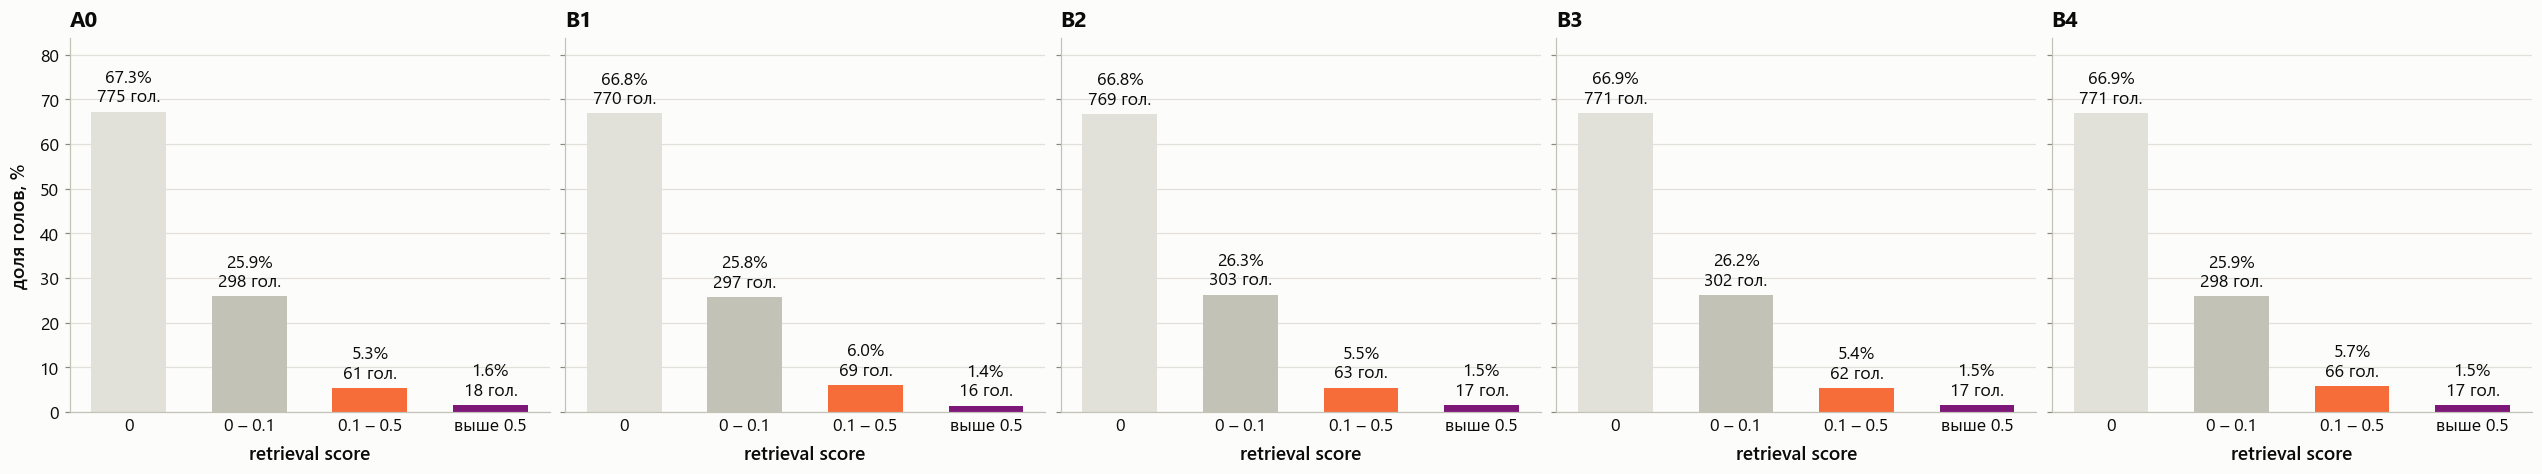

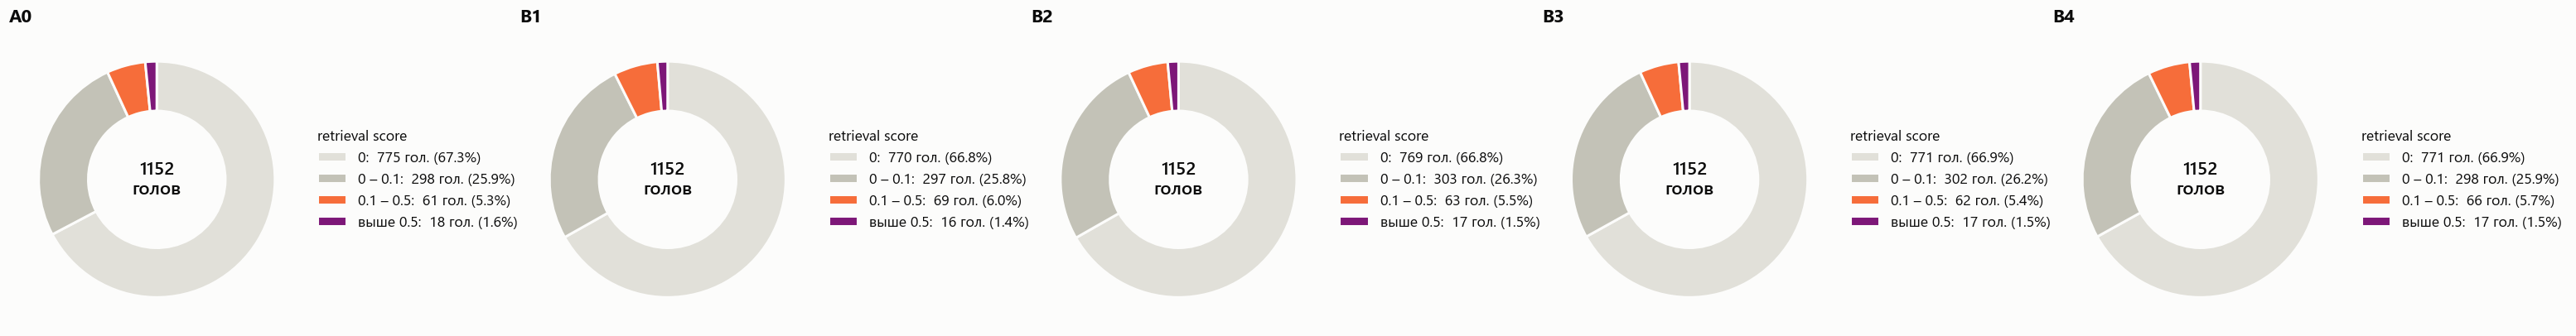

доля голов, %


,ровно 0,0 – 0.1,0.1 – 0.5,выше 0.5,голов выше 0.1
детекция,57.9,36.7,4.2,1.2,62.0
A0,67.3,25.9,5.3,1.6,79.0
B1,66.8,25.8,6.0,1.4,85.0
B2,66.8,26.3,5.5,1.5,80.0
B3,66.9,26.2,5.4,1.5,79.0
B4,66.9,25.9,5.7,1.5,83.0


In [27]:
axes = panels(len(levels), 4.6, sharey=True)
for ax, level in zip(axes, levels):
    plots.score_distribution(scores[level], ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "B_score_distribution")

axes = panels(len(levels), 5.6, 3.6)
for ax, level in zip(axes, levels):
    plots.score_pie(scores[level], ax=ax, title=level)
show(axes, "B_score_pie")

share = lambda s: {"ровно 0": (s == 0).mean() * 100, "0 – 0.1": ((s > 0) & (s <= 0.1)).mean() * 100, "0.1 – 0.5": ((s > 0.1) & (s <= 0.5)).mean() * 100,
                   "выше 0.5": (s > 0.5).mean() * 100, f"голов выше {THRESHOLD}": float((s > THRESHOLD).sum())}
print("доля голов, %")
display(pd.DataFrame({"детекция": share(reference), **{level: share(scores[level]) for level in levels}}).T.round(1))

### Скор и частота активации (рис. 4 статьи)

Головы упорядочены по скору самого уровня. Частота активации — доля примеров уровня, в которых голова скопировала хотя бы один токен иглы.

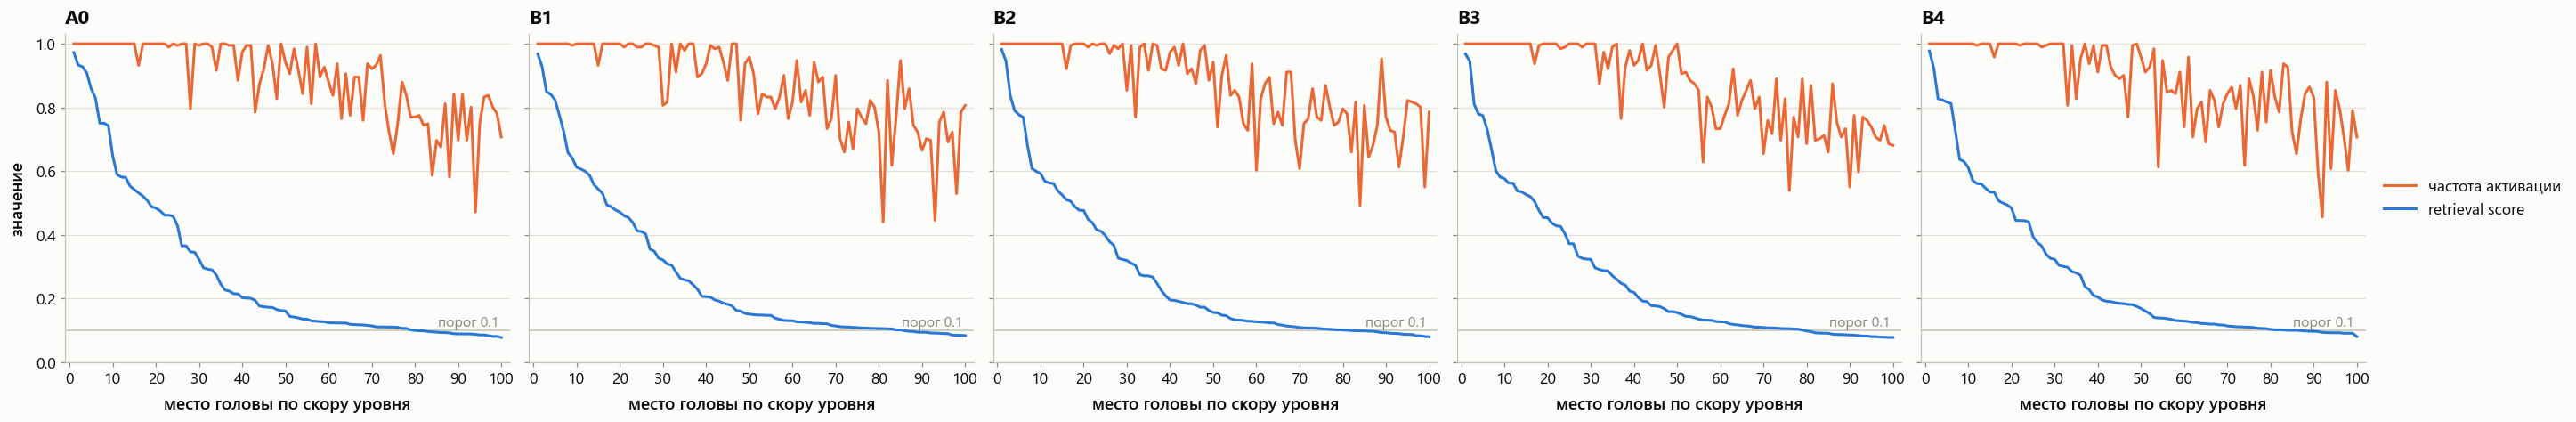

голов, активных во всех примерах уровня: {'A0': 31, 'B1': 28, 'B2': 25, 'B3': 29, 'B4': 29}


In [28]:
axes = panels(len(levels), 4.8, extra=2.2, sharey=True)
for ax, level in zip(axes, levels):
    plots.score_vs_frequency(rankings[level], top=100, threshold=THRESHOLD, ax=ax, title=level)
    ax.set_xlabel("место головы по скору уровня")
    if ax is not axes[-1]:
        ax.get_legend().remove()
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "B_score_vs_frequency")

print("голов, активных во всех примерах уровня:", {level: int((rankings[level]["frequency"] == 1).sum()) for level in levels})

### Скор каждой головы (рис. 5 статьи)

Одна шкала цвета на всех панелях.

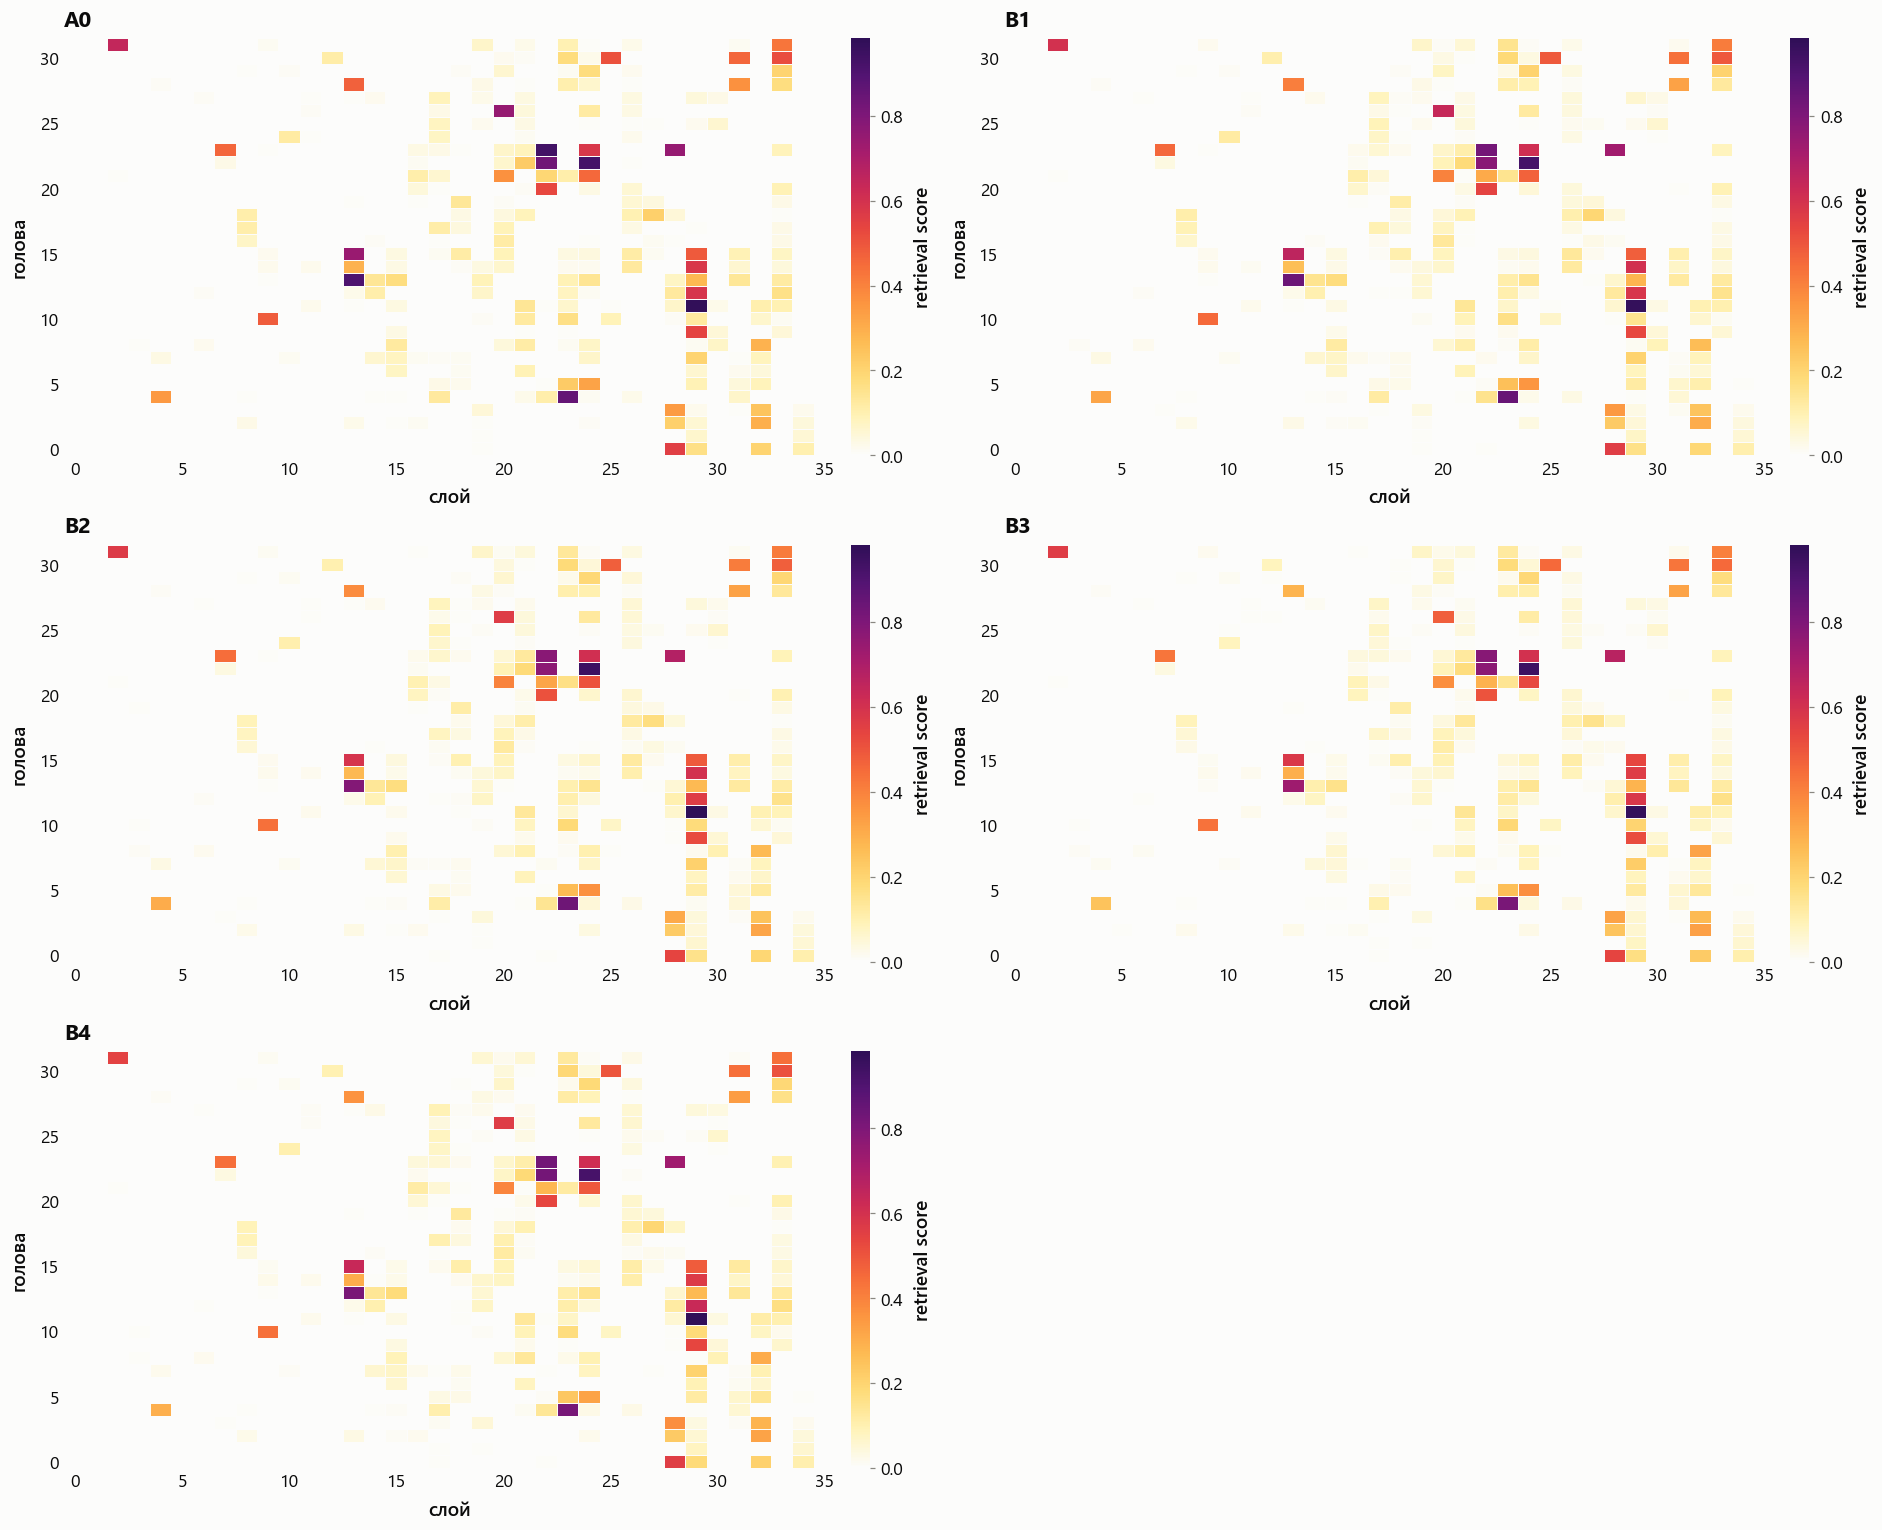

In [29]:
vmax = max(float(s.max()) for s in scores.values())
rows = -(-len(levels) // 2)
fig, axes = plt.subplots(rows, 2, figsize=style.size(17, 4.6 * rows))
for ax, level in zip(axes.ravel(), levels):
    plots.head_heatmap(scores[level], heads.layers, vmax=vmax, ax=ax, title=level)
for ax in axes.ravel()[len(levels):]:
    ax.set_visible(False)
show(axes, "B_head_heatmap")

### 20 лучших голов уровня

Рейтинг самого уровня. Сравнение с рейтингом детекции — в разделе 3.2.

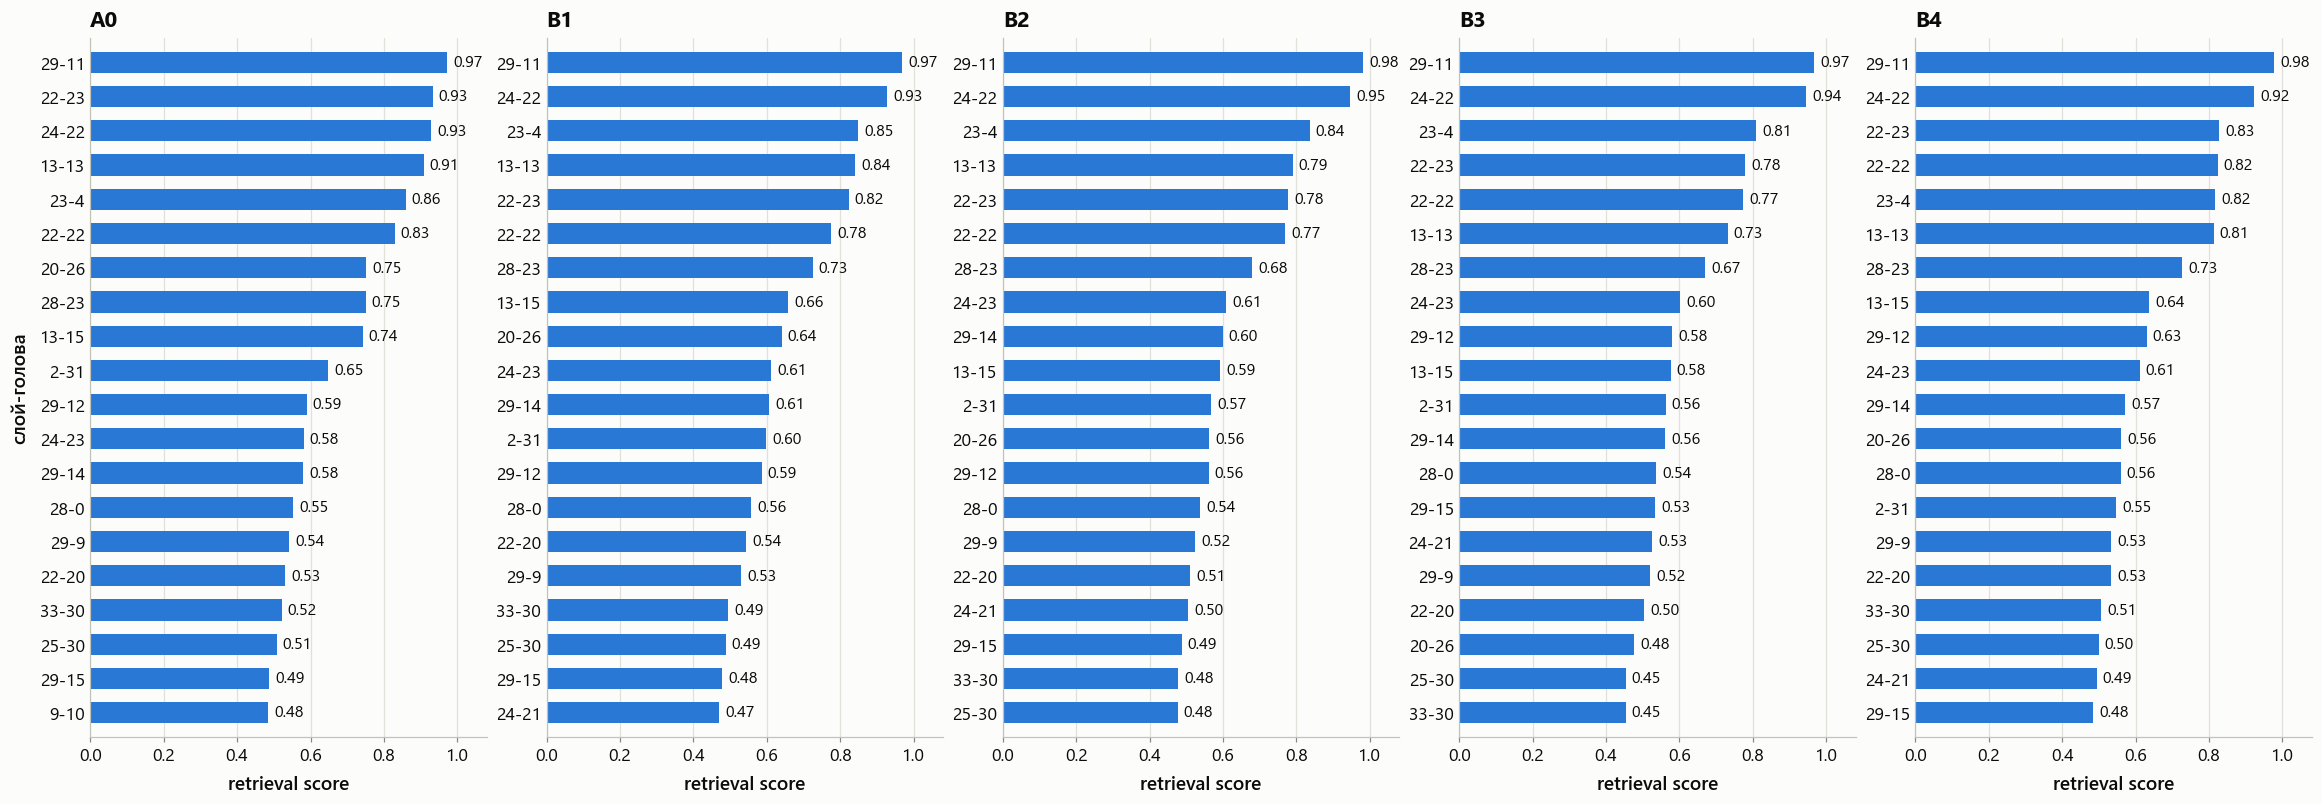

In [30]:
axes = panels(len(levels), 4.2, 7.2)
for ax, level in zip(axes, levels):
    plots.top_heads(rankings[level], k=20, threshold=THRESHOLD, ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "B_top_heads")

## 3.2. Сохраняется ли рейтинг детекции

Порядок голов на каждом уровне против порядка детекции на простой задаче: корреляция Спирмена по всем головам и число общих голов среди 20, 40 и 60 лучших. Строка A0 — это перенос на другие иглы без усложнения; остальные уровни сравниваются с ней.

In [31]:
display(hard.ranking_table(scores, reference))

print(f"то же против {BASE} (та же игла и вопрос, добавлены только близнецы)")
display(hard.ranking_table({level: scores[level] for level in twin_levels}, scores[BASE]))

,спирмен,top20,top40,top60
условие,,,,
A0,0.845,18/20,36/40,47/60
B1,0.846,17/20,35/40,46/60
B2,0.845,17/20,35/40,47/60
B3,0.833,17/20,35/40,46/60
B4,0.839,17/20,35/40,48/60


то же против A0 (та же игла и вопрос, добавлены только близнецы)


,спирмен,top20,top40,top60
условие,,,,
B1,0.954,19/20,37/40,54/60
B2,0.952,19/20,37/40,53/60
B3,0.955,19/20,37/40,53/60
B4,0.947,19/20,37/40,55/60


### Корреляция скоров: исходные головы и наша задача

Точка — голова: по горизонтали её скор в детекции на простой задаче, по вертикали — на уровне. На диагонали скор сохранён. Выделены головы, которые детекция относит к retrieval-головам (скор выше порога).

r — корреляция Пирсона (совпадают ли сами значения), ρ — Спирмена (совпадает ли порядок). По всем головам корреляцию во многом задают сотни голов со скором около нуля, поэтому отдельно посчитано по исходным retrieval-головам.

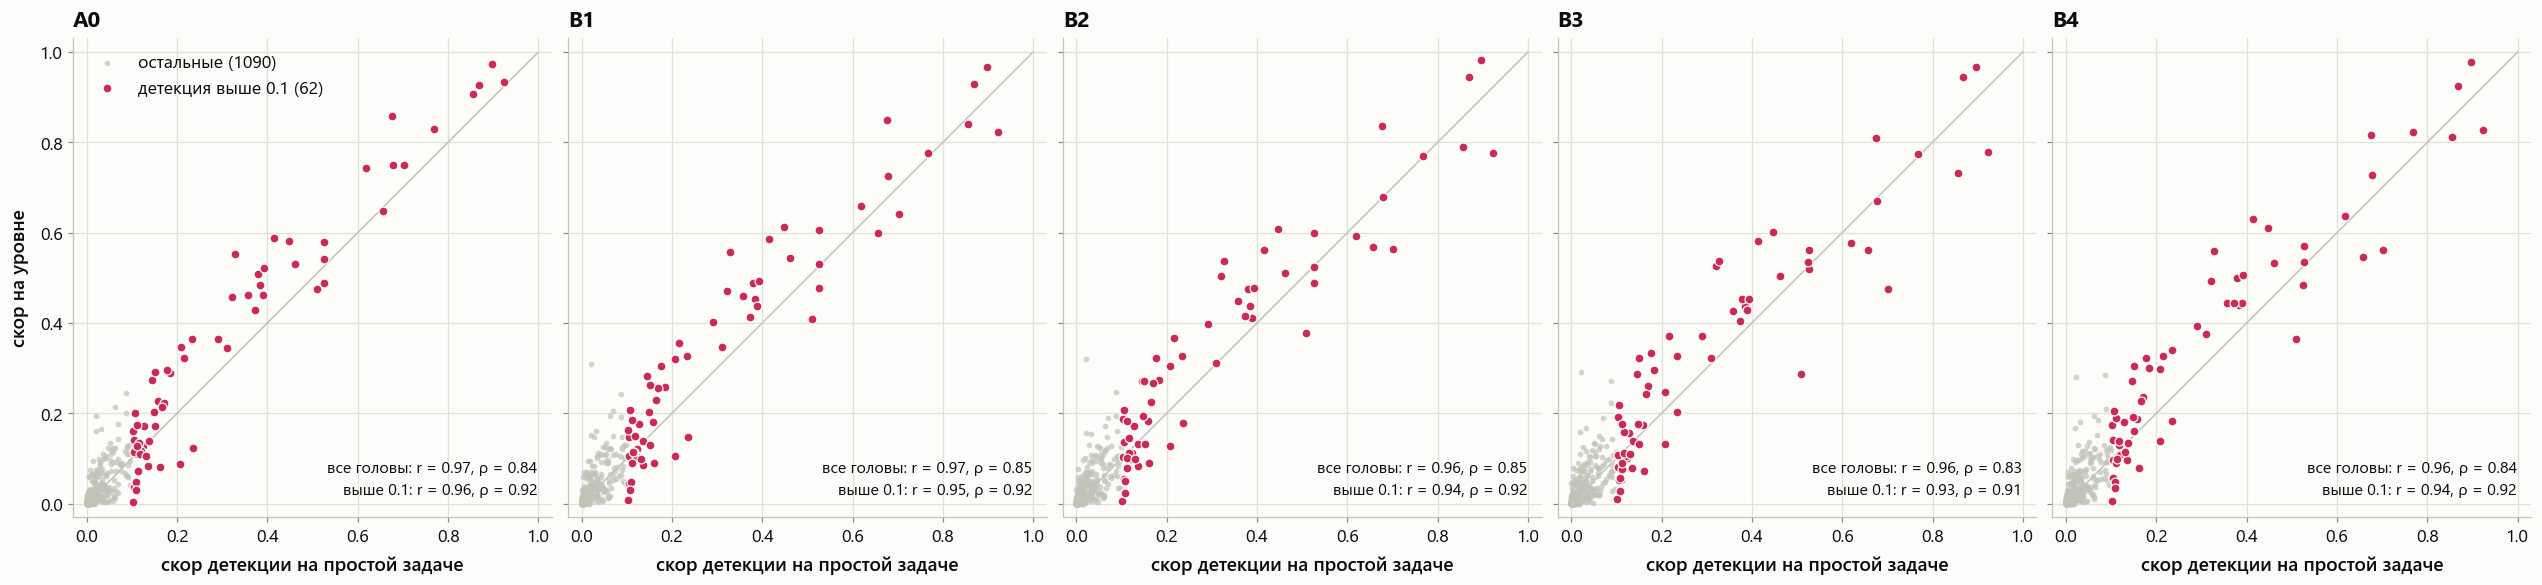

условие               A0                   B1                   B2         \
                   голов пирсон спирмен голов пирсон спирмен голов пирсон   
головы                                                                      
20 лучших детекции    20  0.941   0.904    20  0.888   0.853    20  0.855   
40 лучших детекции    40  0.951   0.946    40  0.934   0.935    40  0.919   
60 лучших детекции    60  0.962   0.919    60  0.951   0.921    60  0.941   
все головы          1152  0.974   0.845  1152  0.967   0.846  1152  0.962   
детекция выше 0.1     62  0.962   0.915    62  0.951   0.915    62  0.941   

условие                       B3                   B4                 
                   спирмен голов пирсон спирмен голов пирсон спирмен  
головы                                                                
20 лучших детекции   0.826    20  0.803   0.758    20  0.844   0.817  
40 лучших детекции   0.924    40  0.894   0.883    40  0.920   0.919  
60 лучших детекции   0.925    60  0.926   0.920    60  0.942   0.927  
все головы           0.845  1152  0.956   0.833  1152  0.963   0.839  
детекция выше 0.1    0.917    62  0.926   0.913    62  0.942   0.923

In [32]:
axes = panels(len(levels), 4.6, 4.9, sharey=True)
for ax, level in zip(axes, levels):
    plots.score_scatter(reference, scores[level], threshold=THRESHOLD, ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
        ax.get_legend().remove()
show(axes, "B_score_scatter")

display(hard.correlation_table(scores, reference, order, threshold=THRESHOLD).unstack("условие").swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False))

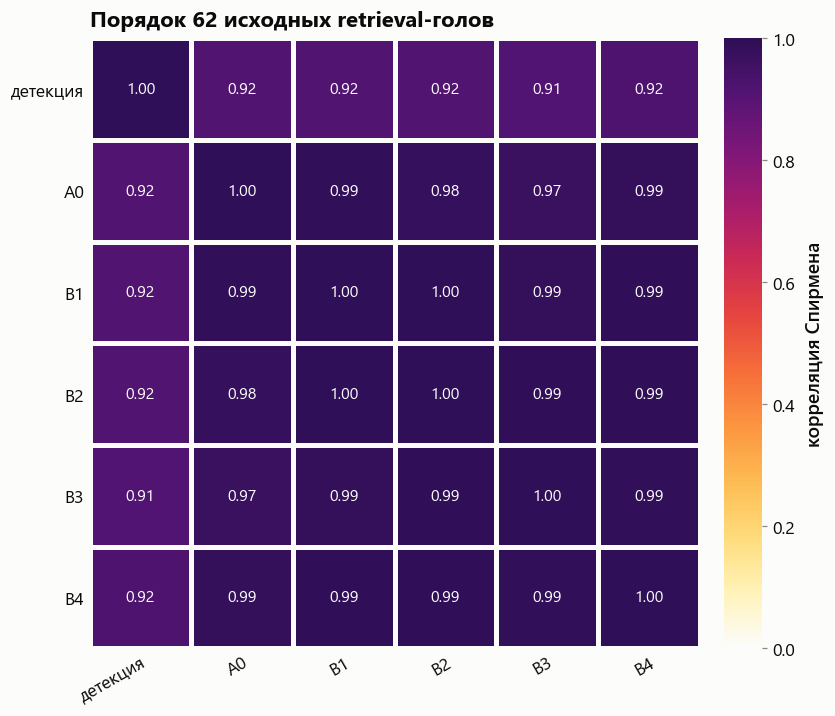

In [33]:
# между всеми условиями сразу: корреляция Спирмена по головам детекции выше порога
found = reference.ravel() > THRESHOLD
show(plots.correlation({"детекция": reference.ravel()[found], **{level: scores[level].ravel()[found] for level in levels}},
                       title=f"Порядок {int(found.sum())} исходных retrieval-голов"), "B_score_correlation")

## 3.3. Значения голов детекции по уровням

Головы стоят в порядке детекции и не переупорядочиваются. Если роль сохраняется, линии уровней идут вместе.

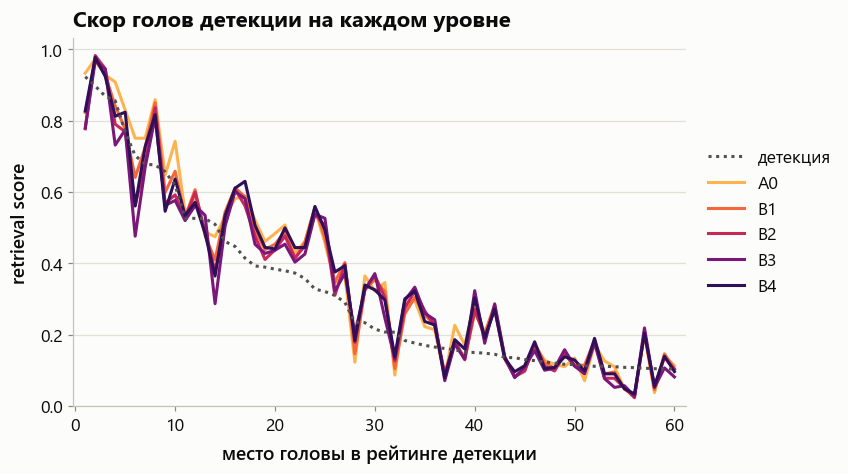

средний скор голов, которые отключаются масками


,детекция,A0,B1,B2,B3,B4
20 лучших,0.6109,0.6786,0.6480,0.6248,0.6100,0.6385
40 лучших,0.4248,0.4931,0.4765,0.4663,0.4588,0.4770
60 лучших,0.3229,0.3706,0.3600,0.3514,0.3453,0.3600


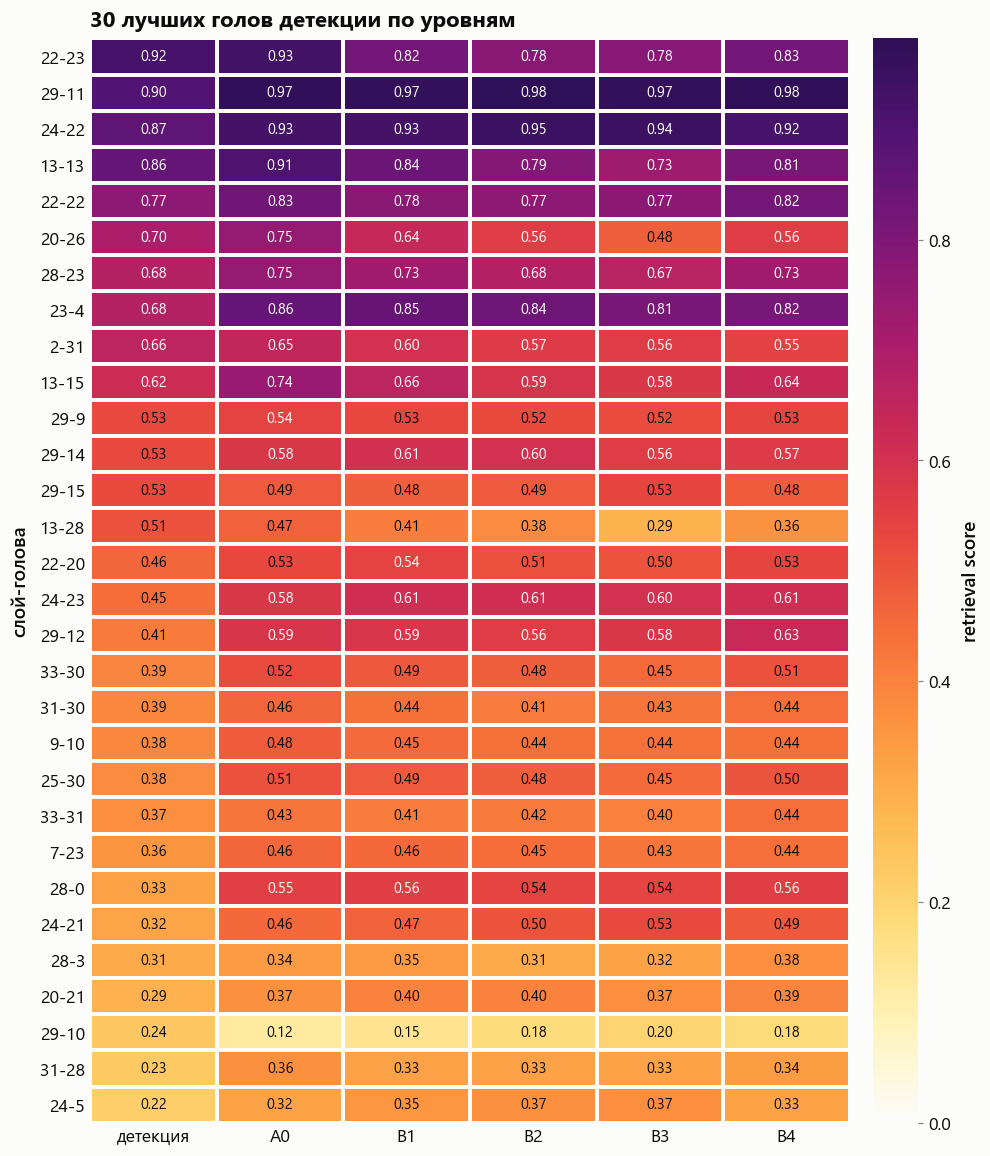

In [34]:
show(plots.rank_profile(scores, order, top=60, reference=reference, title="Скор голов детекции на каждом уровне"), "B_rank_profile")

print("средний скор голов, которые отключаются масками")
display(hard.top_means({"детекция": reference, **scores}, order))

top = 30
table = pd.DataFrame({"детекция": reference.ravel()[order[:top]], **{level: scores[level].ravel()[order[:top]] for level in levels}},
                     index=[heads.name(i) for i in order[:top]])
show(plots.head_table(table, title=f"{top} лучших голов детекции по уровням"), "B_head_table")

## 3.4. Контроль: дословные ответы

Скор копирования зависит от того, насколько дословно модель отвечает. Тот же расчёт повторён только на ответах с точной фразой: там число скопированных токенов одинаково на всех уровнях.

ответов с точной фразой: {'A0': 198, 'B1': 193, 'B2': 197, 'B3': 197, 'B4': 198}


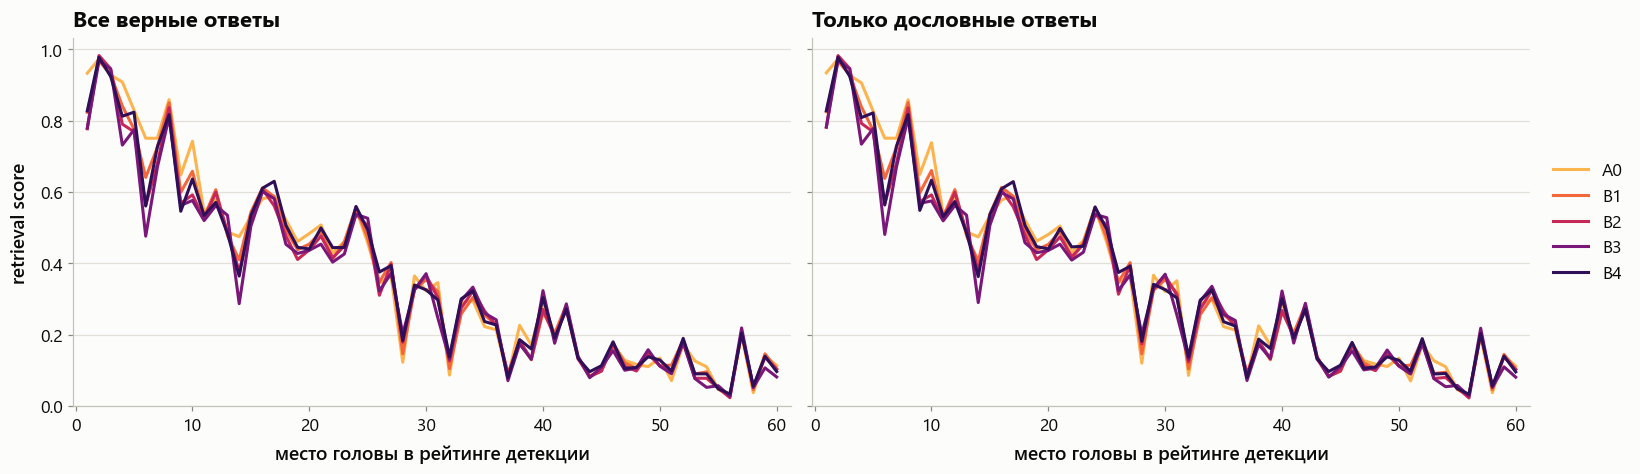

средний скор лучших голов детекции: все верные ответы


,A0,B1,B2,B3,B4
20 лучших,0.6786,0.6480,0.6248,0.6100,0.6385
40 лучших,0.4931,0.4765,0.4663,0.4588,0.4770
60 лучших,0.3706,0.3600,0.3514,0.3453,0.3600


только дословные ответы


,A0,B1,B2,B3,B4
20 лучших,0.6780,0.6472,0.6256,0.6113,0.6385
40 лучших,0.4928,0.4759,0.4668,0.4597,0.4771
60 лучших,0.3703,0.3595,0.3517,0.3460,0.3600


In [35]:
exact = heads.samples["exact"].to_numpy()
print("ответов с точной фразой:", {level: int((exact & heads.samples["correct"] & (heads.samples["level"] == level)).sum()) for level in levels})
exact_scores = hard.level_scores(heads, METRIC, where=exact)

axes = panels(2, 6.6, extra=1.6, sharey=True)
plots.rank_profile(scores, order, top=60, legend=False, ax=axes[0], title="Все верные ответы")
plots.rank_profile(exact_scores, order, top=60, ax=axes[1], title="Только дословные ответы")
axes[1].set_ylabel("")
show(axes, "B_exact_control")

print("средний скор лучших голов детекции: все верные ответы")
display(hard.top_means(scores, order))
print("только дословные ответы")
display(hard.top_means(exact_scores, order))

## 3.5. Куда головы смотрят: масса внимания на игле

Головы стоят в порядке детекции (по копированию).

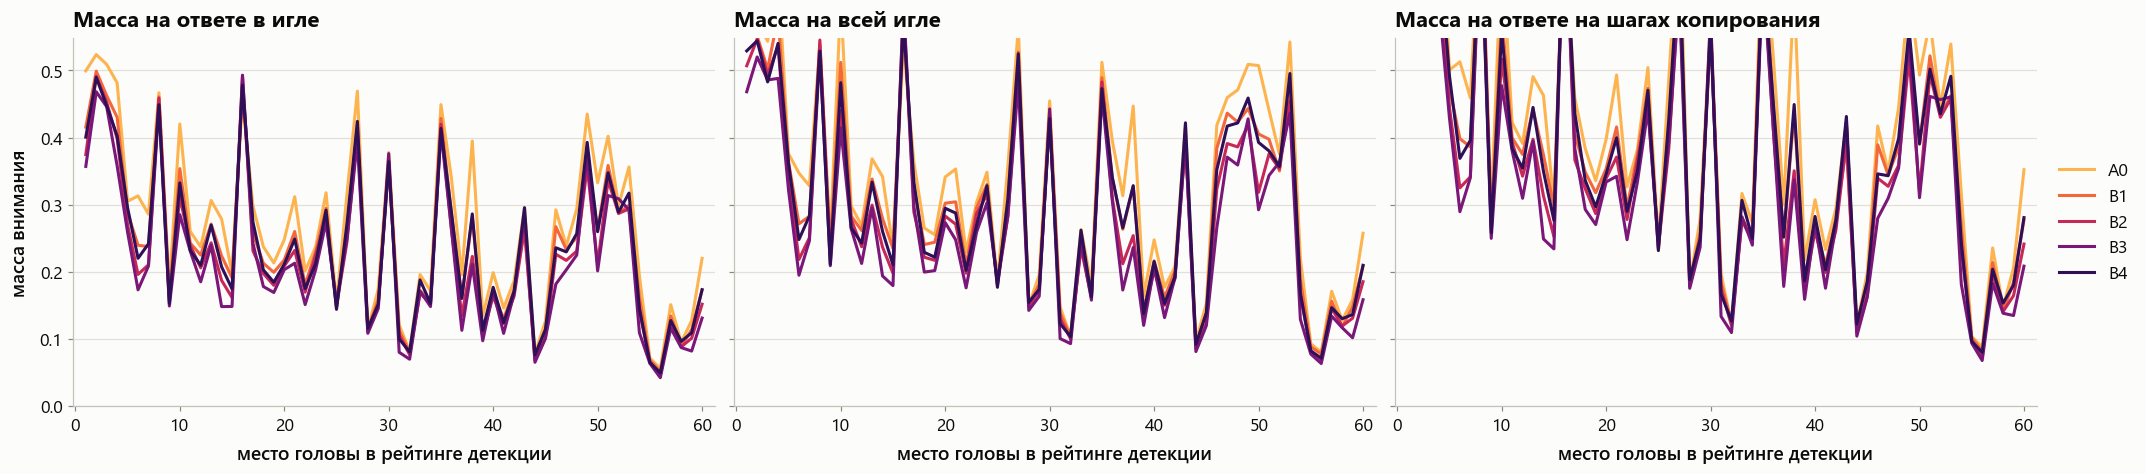

Масса на ответе в игле (needle_mass): среднее у лучших голов детекции


,A0,B1,B2,B3,B4
20 лучших,0.3358,0.3033,0.2834,0.2696,0.2939
40 лучших,0.2919,0.2616,0.2454,0.2349,0.2559
60 лучших,0.2679,0.2390,0.2235,0.2143,0.2352


Масса на всей игле (needle_sentence_mass): среднее у лучших голов детекции


,A0,B1,B2,B3,B4
20 лучших,0.4073,0.3747,0.3481,0.3299,0.3589
40 лучших,0.3516,0.3211,0.2993,0.2847,0.3111
60 лучших,0.3325,0.3023,0.2806,0.2658,0.2944


Масса на ответе на шагах копирования (needle_attention_mass): среднее у лучших голов детекции


,A0,B1,B2,B3,B4
20 лучших,0.5450,0.4971,0.4637,0.4424,0.4858
40 лучших,0.4677,0.4235,0.3968,0.3811,0.4175
60 лучших,0.4219,0.3807,0.3566,0.3428,0.3771


In [36]:
mass_metrics = {"needle_mass": "Масса на ответе в игле", "needle_sentence_mass": "Масса на всей игле", "needle_attention_mass": "Масса на ответе на шагах копирования"}
masses = {metric: hard.level_scores(heads, metric, where=common) for metric in mass_metrics}

axes = panels(3, 6.0, extra=1.4, sharey=True)
for ax, (metric, name) in zip(axes, mass_metrics.items()):
    plots.rank_profile(masses[metric], order, top=60, ylabel="масса внимания", legend=ax is axes[-1], ax=ax, title=name)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "B_mass_profile")

for metric, name in mass_metrics.items():
    print(f"{name} ({metric}): среднее у лучших голов детекции")
    display(hard.top_means(masses[metric], order))

## 3.6. Игла против близнецов

Главный раздел оси: смотрят ли retrieval-головы на близнецов и копируют ли из них. Все значения — на тех же верно отвеченных примерах, то есть модель в итоге ответила правильно.

### Масса внимания: игла и самый сильный близнец

`needle_sentence_mass` — доля внимания головы на предложении иглы; `competing_max_mass` — на том близнеце, который на данном шаге получает больше всего. Это сравнение «одно предложение против одного предложения», оно одинаково осмысленно при одном близнеце и при трёх.

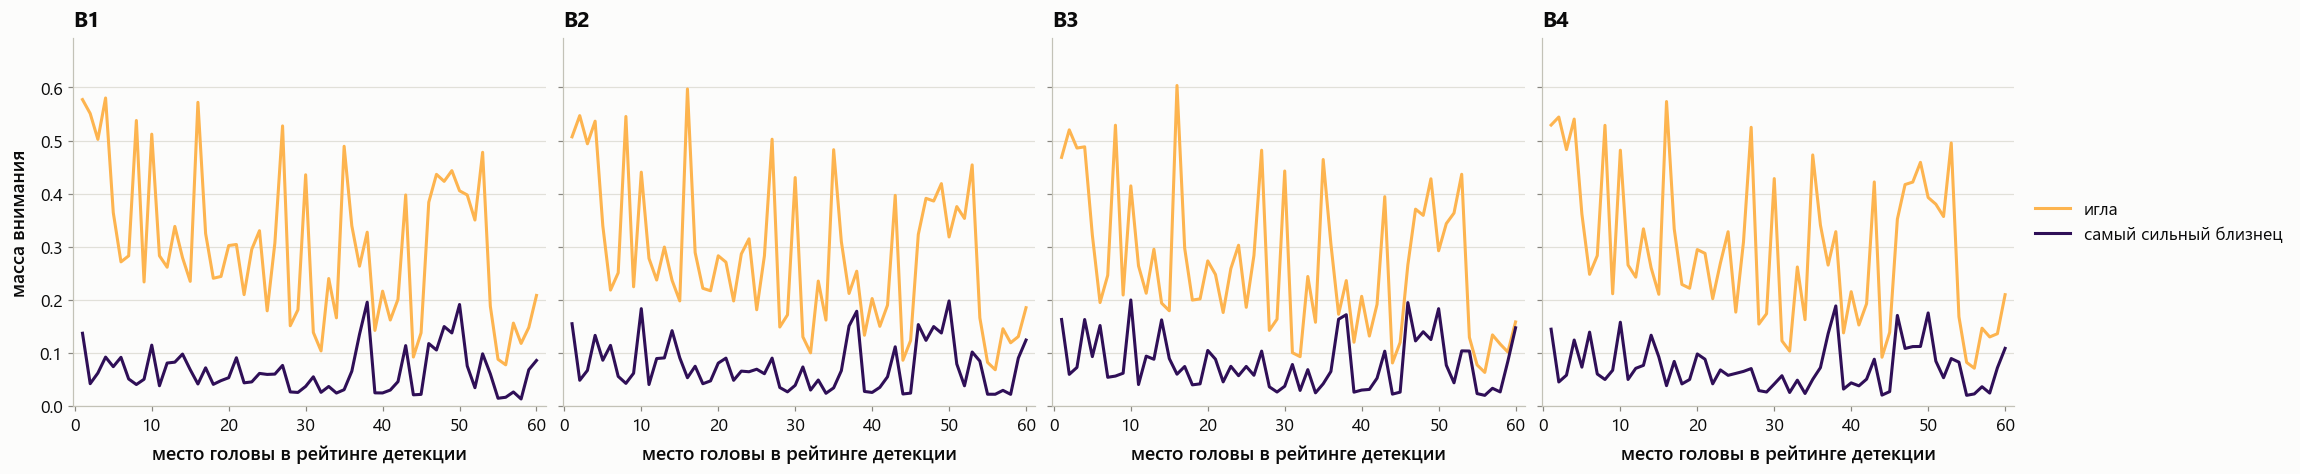

масса на всей игле: среднее у лучших голов детекции


,A0,B1,B2,B3,B4
20 лучших,0.4073,0.3747,0.3481,0.3299,0.3589
40 лучших,0.3516,0.3211,0.2993,0.2847,0.3111
60 лучших,0.3325,0.3023,0.2806,0.2658,0.2944


масса на самом сильном близнеце


,B1,B2,B3,B4
20 лучших,0.0691,0.0851,0.0936,0.0829
40 лучших,0.0632,0.0739,0.0794,0.0722
60 лучших,0.0660,0.0764,0.0807,0.0731


масса на всех близнецах вместе (на B2 и B3 их три)


,B1,B2,B3,B4
20 лучших,0.0691,0.1253,0.1439,0.0829
40 лучших,0.0632,0.1118,0.1257,0.0722
60 лучших,0.0660,0.1152,0.1285,0.0731


In [37]:
needle = masses["needle_sentence_mass"]
rival = hard.level_scores(heads, "competing_max_mass", where=common)
rivals_all = hard.level_scores(heads, "competing_mass", where=common)

top_mass = max(float(needle[level].ravel()[order[:60]].max()) for level in levels)
axes = panels(len(twin_levels), 4.8, extra=1.6, sharey=True)
for ax, level in zip(axes, twin_levels):
    plots.rank_profile({"игла": needle[level], "самый сильный близнец": rival[level]}, order, top=60, ylabel="масса внимания",
                       legend=ax is axes[-1], ax=ax, title=level)
    ax.set_ylim(0, top_mass * 1.05)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "B_needle_vs_twin")

print("масса на всей игле: среднее у лучших голов детекции")
display(hard.top_means(needle, order))
print("масса на самом сильном близнеце")
display(hard.top_means({level: rival[level] for level in twin_levels}, order))
print("масса на всех близнецах вместе (на B2 и B3 их три)")
display(hard.top_means({level: rivals_all[level] for level in twin_levels}, order))

### Избирательность

Какая доля внимания, отданного игле или её самому сильному близнецу, приходится на иглу: `игла / (игла + близнец)`. 1 — голова смотрит только на иглу, 0.5 — поровну, 0 — только на близнеца.

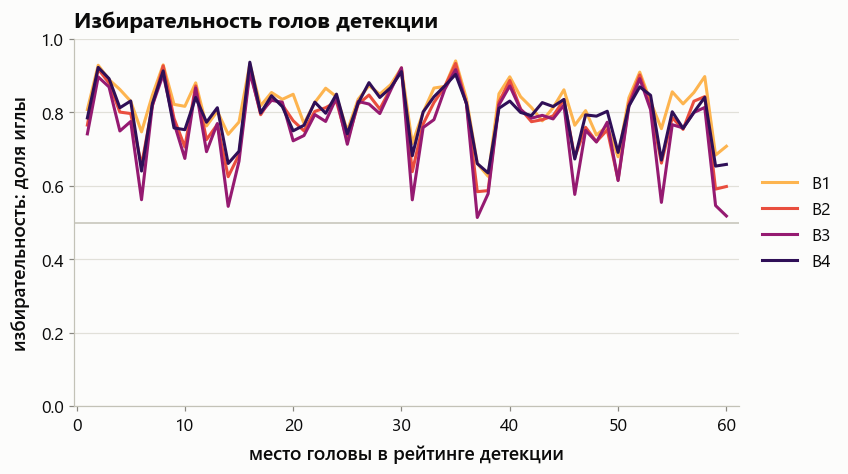

средняя избирательность лучших голов детекции


,B1,B2,B3,B4
20 лучших,0.8368,0.7940,0.7699,0.8032
40 лучших,0.8304,0.7952,0.7746,0.8060
60 лучших,0.8206,0.7823,0.7614,0.7964


для сравнения — остальные головы, которые смотрят на иглу или близнеца (сумма массы выше 0.05): число и средняя избирательность


,B1,B2,B3,B4
голов,275.000,290.000,275.000,283.000
избирательность,0.747,0.677,0.664,0.716


In [38]:
select = {level: hard.selectivity(needle[level], rival[level]) for level in twin_levels}
ax = plots.rank_profile(select, order, top=60, ylabel="избирательность: доля иглы", title="Избирательность голов детекции")
ax.set_ylim(0, 1.0)
ax.axhline(0.5, color=style.THEME.axis, linewidth=1, zorder=1)
show(ax, "B_selectivity")

print("средняя избирательность лучших голов детекции")
display(hard.top_means(select, order))

rest_heads = order[60:]
looking = {level: (needle[level].ravel()[rest_heads] + rival[level].ravel()[rest_heads]) > 0.05 for level in twin_levels}
print("для сравнения — остальные головы, которые смотрят на иглу или близнеца (сумма массы выше 0.05): число и средняя избирательность")
display(pd.DataFrame({level: {"голов": int(looking[level].sum()), "избирательность": float(select[level].ravel()[rest_heads][looking[level]].mean())} for level in twin_levels}).round(3))

### Игла и близнец по головам

Точка — голова: по горизонтали масса на игле, по вертикали — на самом сильном близнеце. Выделены 60 лучших голов детекции. Чем ниже точка под диагональю, тем избирательнее голова.

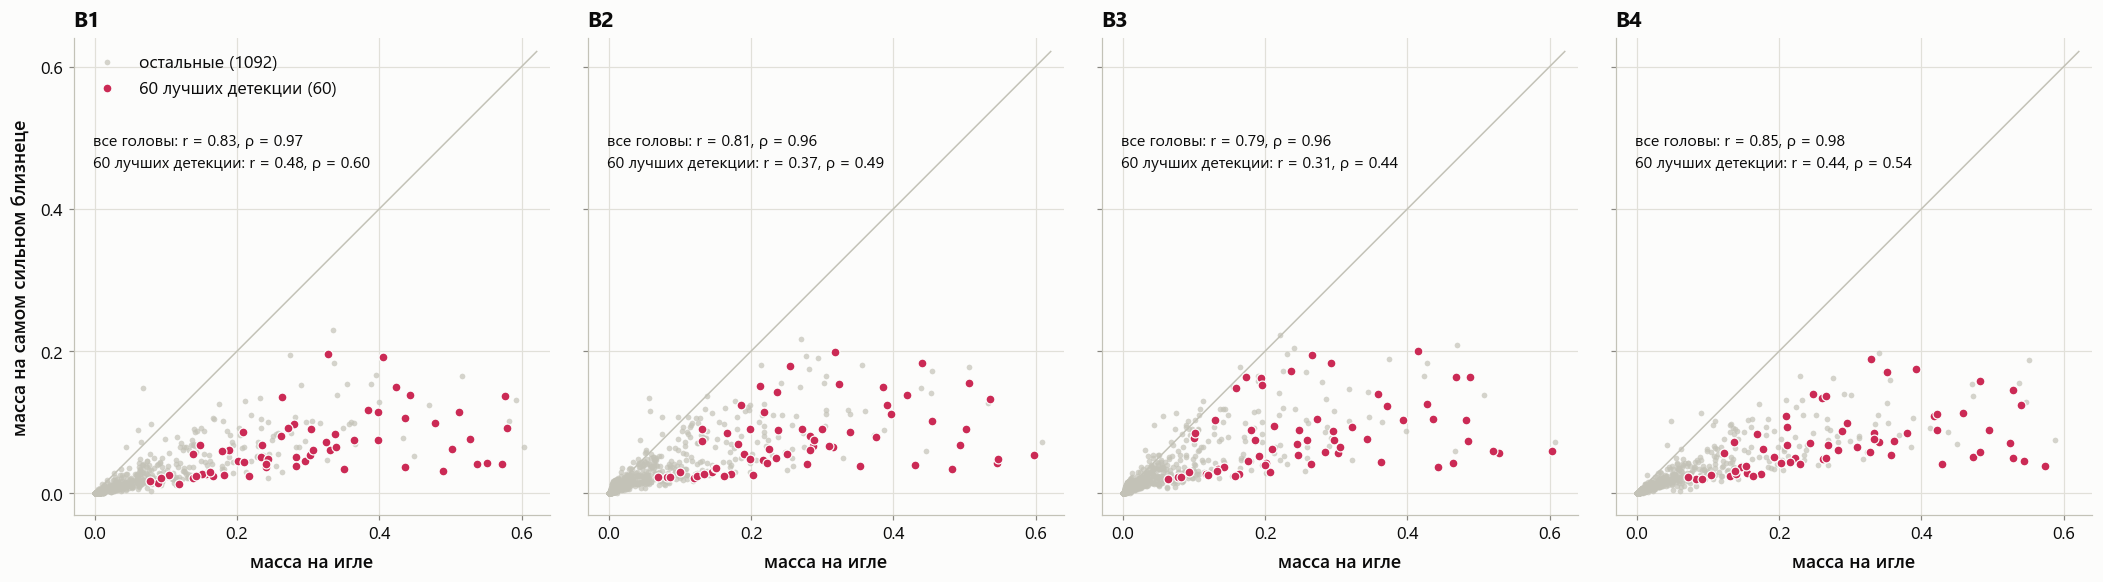

In [39]:
best = np.zeros(total_heads, dtype=bool)
best[order[:60]] = True
limit = max(float(needle[level].max()) for level in twin_levels) * 1.02
axes = panels(len(twin_levels), 4.8, 5.0, sharey=True)
for ax, level in zip(axes, twin_levels):
    plots.score_scatter(needle[level], rival[level], mark=best, mark_label="60 лучших детекции", top=limit, xlabel="масса на игле",
                        ylabel="масса на самом сильном близнеце", ax=ax, title=level)
    if ax is not axes[0]:
        ax.set_ylabel("")
        ax.get_legend().remove()
show(axes, "B_needle_twin_scatter")

In [40]:
# головы, которые больше всего смотрят на близнецов, на уровне с тремя близнецами рядом
LOOK = "B3"
most = np.argsort(-rival[LOOK].ravel(), kind="stable")[:20]
pd.DataFrame({"голова": [heads.name(i) for i in most], "место в детекции": [place[int(i)] for i in most],
              "скор копирования на уровне": scores[LOOK].ravel()[most], "масса на игле": needle[LOOK].ravel()[most],
              "масса на самом сильном близнеце": rival[LOOK].ravel()[most], "избирательность": select[LOOK].ravel()[most]}).round(3)

,голова,место в детекции,скор копирования на уровне,масса на игле,масса на самом сильном близнеце,избирательность
0,17-21,68,0.027,0.220,0.223,0.498
1,15-11,112,0.019,0.470,0.208,0.693
2,19-13,80,0.055,0.240,0.205,0.540
3,13-15,10,0.576,0.415,0.200,0.675
4,17-17,99,0.068,0.231,0.196,0.541
5,15-13,46,0.155,0.266,0.195,0.577
6,13-29,355,0.000,0.375,0.190,0.664
7,18-19,50,0.112,0.292,0.183,0.615
8,20-15,79,0.096,0.428,0.183,0.700
9,15-8,72,0.058,0.164,0.178,0.480


### Копирование: из иглы и из близнецов

`copy_sentence` — число шагов, на которых голова смотрит на токен иглы и модель выдаёт именно его; `copy_competing` — то же для токенов близнецов. Оба делятся на длину ответа иглы. Близнец повторяет шаблон иглы, поэтому часть его токенов совпадает с токенами верного ответа (`is asked to`, `and`, `a`): ненулевой `copy_competing` на верном ответе означает, что голова взяла общий токен из близнеца, а не из иглы.

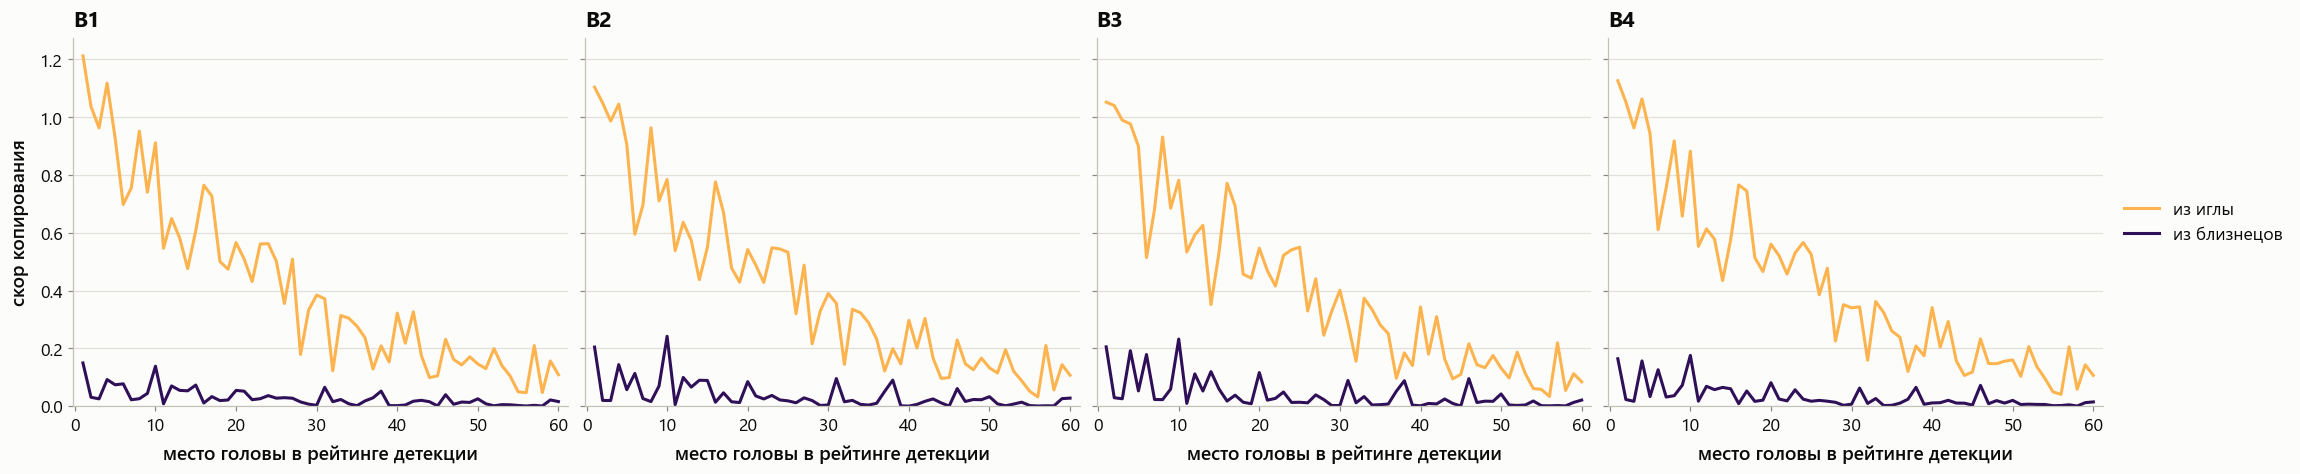

копирование из иглы (copy_sentence): среднее у лучших голов детекции


,A0,B1,B2,B3,B4
20 лучших,0.7856,0.7603,0.7234,0.7049,0.7388
40 лучших,0.5612,0.5492,0.5298,0.5196,0.5421
60 лучших,0.4220,0.4155,0.3996,0.3910,0.4091


копирование из близнецов (copy_competing)


,B1,B2,B3,B4
20 лучших,0.0537,0.0715,0.0782,0.0640
40 лучших,0.0383,0.0481,0.0514,0.0425
60 лучших,0.0291,0.0371,0.0393,0.0324


доля копирования из близнецов в общем копировании, %


,B1,B2,B3,B4
20 лучших,6.6,9.0,10.0,8.0
40 лучших,6.5,8.3,9.0,7.3
60 лучших,6.5,8.5,9.1,7.3


In [41]:
copy_needle = hard.level_scores(heads, "copy_sentence", where=common)
copy_twin = hard.level_scores(heads, "copy_competing", where=common)

top_copy = max(float(copy_needle[level].ravel()[order[:60]].max()) for level in twin_levels)
axes = panels(len(twin_levels), 4.8, extra=1.6, sharey=True)
for ax, level in zip(axes, twin_levels):
    plots.rank_profile({"из иглы": copy_needle[level], "из близнецов": copy_twin[level]}, order, top=60, ylabel="скор копирования",
                       legend=ax is axes[-1], ax=ax, title=level)
    ax.set_ylim(0, top_copy * 1.05)
    if ax is not axes[0]:
        ax.set_ylabel("")
show(axes, "B_copy_needle_vs_twin")

print("копирование из иглы (copy_sentence): среднее у лучших голов детекции")
display(hard.top_means(copy_needle, order))
print("копирование из близнецов (copy_competing)")
display(hard.top_means({level: copy_twin[level] for level in twin_levels}, order))
print("доля копирования из близнецов в общем копировании, %")
display((hard.top_means({level: copy_twin[level] for level in twin_levels}, order)
         / (hard.top_means({level: copy_twin[level] for level in twin_levels}, order) + hard.top_means({level: copy_needle[level] for level in twin_levels}, order)) * 100).round(1))

## 3.7. По семействам

Совпадает ли направление эффекта в каждом семействе: у 20 лучших голов детекции — скор копирования и избирательность по уровням.

средний скор копирования 20 лучших голов детекции


,A0,B1,B2,B3,B4
cairo,0.6675,0.6397,0.6008,0.5757,0.6534
lisbon,0.6822,0.6815,0.6757,0.6677,0.6640
oslo,0.6863,0.6248,0.6009,0.5900,0.5995


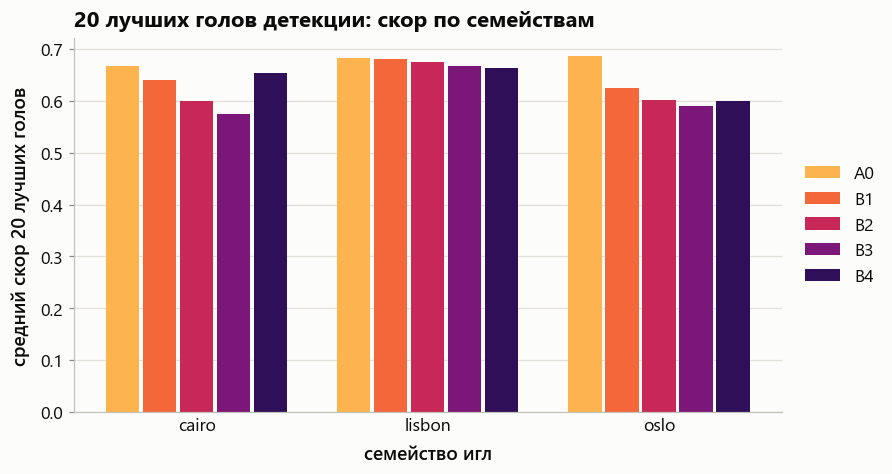

средняя избирательность 20 лучших голов детекции


,B1,B2,B3,B4
cairo,0.8473,0.7865,0.7589,0.8038
lisbon,0.8716,0.8462,0.8253,0.8686
oslo,0.7960,0.7518,0.7277,0.7480


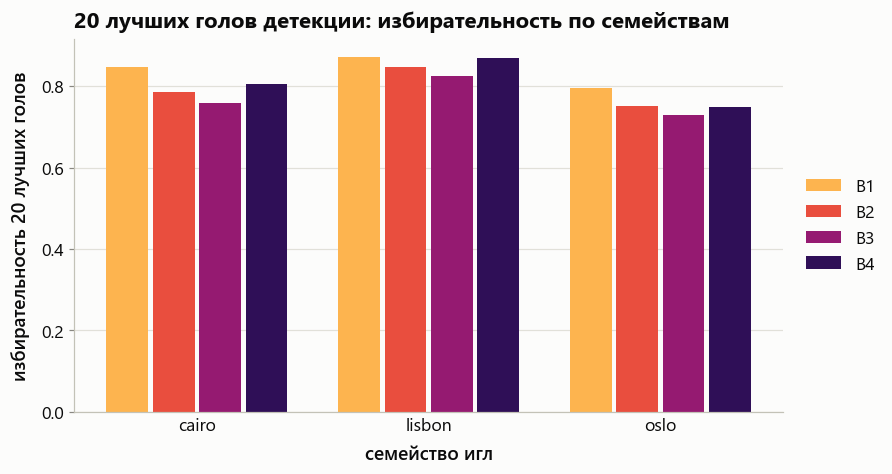

In [42]:
def family_mask(family):
    return common & (heads.samples["family"] == family).to_numpy()

family_top = pd.DataFrame({family: hard.top_means(hard.level_scores(heads, METRIC, where=family_mask(family)), order).loc["20 лучших"] for family in families}).T
print("средний скор копирования 20 лучших голов детекции")
display(family_top)
show(plots.group_bars(family_top, xlabel="семейство игл", ylabel="средний скор 20 лучших голов", title="20 лучших голов детекции: скор по семействам"), "B_family_top20")

rows = {}
for family in families:
    n = hard.level_scores(heads, "needle_sentence_mass", where=family_mask(family), levels=twin_levels)
    r = hard.level_scores(heads, "competing_max_mass", where=family_mask(family), levels=twin_levels)
    rows[family] = hard.top_means({level: hard.selectivity(n[level], r[level]) for level in twin_levels}, order).loc["20 лучших"]
family_select = pd.DataFrame(rows).T
print("средняя избирательность 20 лучших голов детекции")
display(family_select)
show(plots.group_bars(family_select, xlabel="семейство игл", ylabel="избирательность 20 лучших голов", title="20 лучших голов детекции: избирательность по семействам"), "B_family_selectivity")

## 3.8. Появляются ли новые головы

Головы, которые на уровне входят в 20 лучших по скору копирования, но в детекции стояли за пределами первых 60.

In [43]:
rows = []
for level in levels:
    for i in np.argsort(-scores[level].ravel(), kind="stable")[:20]:
        if place[int(i)] > 60:
            rows.append({"уровень": level, "голова": heads.name(i), "место в детекции": place[int(i)], "скор детекции": round(float(reference.ravel()[i]), 3),
                         **{l: round(float(scores[l].ravel()[i]), 3) for l in levels}})
pd.DataFrame(rows) if rows else print("таких голов нет")

таких голов нет


# 4. Выводы

Написаны по результатам этого ноутбука на 2026-10-12; числа взяты из таблиц выше. При пересчёте на других прогонах текст нужно сверить заново — он не обновляется сам.

**На чём стоят выводы.** Одна модель (Qwen3-8B), три семейства игл, 792 примера на прогон, по одному набору случайных голов. В точке «уровень × длина × глубина» три примера, поэтому надёжны только агрегаты: по уровню (198 примеров), по глубине (132–165), по длине (72–90). Различия в несколько процентных пунктов между отдельными уровнями или точками сетки — в пределах шума.

## 4.1. Главное

1. **Головы, найденные на простой задаче, сохраняют роль при близнецах.** Рейтинг относительно детекции: Спирмен 0.83–0.85, общих голов 17 из 20 и 35 из 40. Относительно A0 — 0.95 и 19 из 20. Новых голов нет.
2. **Без маски близнецы почти не мешают:** 99.5–100% верных ответов на всех уровнях, включая три близнеца рядом с иглой и запись с тем же ключом.
3. **Модель не путает иглу с близнецом даже под маской.** Ответов класса «путаница» 8 из 3163 на уровнях с близнецами; слова близнецов встречаются не чаще чем в 3.5% ответов. Маска обрезает ответ, а не подменяет его.
4. **Retrieval-головы на близнецов смотрят, но слабо:** на игле 0.33–0.37 массы внимания, на самом сильном близнеце 0.07–0.09. Избирательность 0.77–0.84 и падает с числом и близостью близнецов.
5. **Эффект близнецов под маской разный при 40 и при 60 головах** и сильно зависит от иглы — см. ниже.

## 4.2. Зависимости в ответах

### От маски

Все уровни ноутбука, включая A0:

| Маска | верно | частично | иное | путаница и смешано |
|---|---|---|---|---|
| без маски | 99.8 | 0 | 0 | 0.2 |
| 60 случайных | 99.0 | 0 | 0 | 1.0 |
| 40 лучших | 62.7 | 36.6 | 0.6 | 0.1 |
| 60 лучших | 49.6 | 35.2 | 14.9 | 0.3 |

- **Неверные ответы под маской лучших голов — это обрезка.** При 40 головах почти все они «частичные»; при 60 добавляется «иное». Фактов близнецов в них практически нет.
- **Случайная маска безобидна.** Единственное заметное отклонение — B4 (запись с тем же ключом): 96.5% верных и 3.5% ответов с фактами вставки, это 7 ответов.
- **При близнецах под маской остаётся больше дословных ответов, чем без них:** точных фраз 19–38% на B1–B4 против 2.5% на A0 при 40 головах. Причину эти данные не показывают.

### От уровня задачи

| Маска | A0 | B1 | B2 | B3 | B4 |
|---|---|---|---|---|---|
| без маски | 100 | 100 | 99.5 | 99.5 | 100 |
| 60 случайных | 100 | 99.0 | 99.5 | 100 | 96.5 |
| 40 лучших | 70.7 | 58.6 | 55.6 | 57.6 | 71.2 |
| 60 лучших | 29.8 | 41.9 | 48.5 | 58.1 | 69.7 |

- **При 40 головах близнецы вредят:** −12…−15 п.п. к A0 на B1–B3, независимо от их числа и расстояния до иглы. Запись с тем же ключом (B4) не вредит.
- **При 60 головах уровни с близнецами выше A0,** и тем выше, чем ближе и «похожее» вставка. Этот результат создаёт в основном `oslo` (85–98% верных). Без него B1 и B2 не лучше A0 (−9 и −1 п.п.), а B3 и B4 остаются выше (+12 и +27 п.п.).
- **Число и близость близнецов влияют на головы** (раздел 4.3), **но не на ответы без маски.**

### От глубины иглы

Верные ответы, %, все уровни вместе:

| Маска | 0 | 22 | 44 | 67 | 89 | 100 |
|---|---|---|---|---|---|---|
| без маски | 100 | 98.8 | 100 | 100 | 100 | 100 |
| 60 случайных | 100 | 98.2 | 99.4 | 98.2 | 99.4 | 98.8 |
| 40 лучших | 78.2 | 52.7 | 57.6 | 53.9 | 67.3 | 66.7 |
| 60 лучших | 72.7 | 43.0 | 46.7 | 44.8 | 43.6 | 46.7 |

- **Игла в самом начале контекста устойчивее всего:** 78% против 53–58% в середине при 40 головах, 73% против 43–47% при 60.
- **Конец контекста выигрывает меньше, чем на оси A:** при 40 головах 67% на глубинах 89 и 100, при 60 головах преимущества нет вовсе.
- **На глубине 0 меньше и обрезанных, и потерянных ответов:** «частично» 22% против 41–46% в середине при 40 головах; «иное» 4% против 16–18% при 60.
- **Преимущество глубины 0 под 60 головами несёт `cairo`** (95% против 22–38% на остальных глубинах); у `oslo` зависимости от глубины нет (71–87% везде).
- **Без маски и под случайной маской зависимости от глубины нет.**

### От длины контекста

| Маска | короткие (до 7k) | длинные (от 22k) | тренд по 11 длинам (Спирмен) |
|---|---|---|---|
| без маски | 100 | 99.5 | −0.40 |
| 60 случайных | 98.5 | 98.6 | −0.07 |
| 40 лучших | 69.6 | 58.6 | −0.80 |
| 60 лучших | 51.8 | 45.5 | −0.59 |

- **Длина контекста влияет только под маской лучших голов:** −11 п.п. при 40 головах, −6 при 60.
- **Без маски близнецы не делают длинный контекст труднее:** единственная точка ниже 100% — 97.8% на 28.5k.
- **Доля «иное» при 60 головах растёт с длиной** (6% на 1000 токенов, 11–23% на длинах от 10k), как и на оси A.

### От иглы

| Маска | `cairo` | `lisbon` | `oslo` |
|---|---|---|---|
| без маски | 99.7 | 100 | 99.7 |
| 60 случайных | 99.1 | 99.1 | 98.8 |
| 40 лучших | 49.7 | 86.7 | 51.8 |
| 60 лучших | 39.7 | 29.4 | 79.7 |

- **Порядок игл переворачивается между масками.** При 40 головах устойчивее всех `lisbon` (87%), при 60 — `oslo` (80%), а `lisbon` становится худшей (29%).
- **`oslo` под 60 головами при близнецах почти не страдает** (85–98% на B1–B4 против 32% на A0). Это самый сильный эффект в ноутбуке и он целиком принадлежит одной игле.
- **Без маски все три иглы ведут себя одинаково.**

## 4.3. Головы

- **Скор копирования снижается с числом и близостью близнецов:** у 20 лучших голов 0.68 (A0) → 0.65 (один далеко) → 0.62 (три случайно) → 0.61 (три рядом); запись с тем же ключом — 0.64. На дословных ответах числа те же, то есть это не артефакт формулировки.
- **Масса на игле снижается так же:** на всей игле 0.41 → 0.37 → 0.35 → 0.33 (B4 — 0.36).
- **Избирательность к игле высокая, но не полная:** 0.84 при одном близнеце далеко, 0.79 при трёх случайных, 0.77 при трёх рядом, 0.80 при записи с тем же ключом. У остальных голов, которые вообще смотрят на иглу или близнеца, она ниже: 0.66–0.75.
- **Из близнецов головы почти не копируют:** 7–10% от общего копирования; это общие с иглой токены шаблона.
- **Порядок голов устойчивее значений.** По 62 исходным головам Спирмен 0.91–0.92 на всех уровнях; Пирсон по 20 лучшим падает с 0.94 (A0) до 0.80 (B3) — значения лучших голов меняются неравномерно.
- **Больше всего на близнецов смотрят не лучшие головы детекции:** среди 20 голов с наибольшей массой на близнеце (уровень B3) только четыре из первых двадцати мест детекции.
- **По иглам направление одно:** избирательность падает от B1 к B3 во всех трёх семействах (`lisbon` 0.87 → 0.83, `cairo` 0.85 → 0.76, `oslo` 0.80 → 0.73).

## 4.4. В сравнении с другими осями

Верные ответы по фактам, %, среднее по уровням оси (A0 — общая точка отсчёта):

| Ось | без маски | 60 случайных | 40 лучших | 60 лучших |
|---|---|---|---|---|
| A0: дословный вопрос, без вставок | 100 | 100 | 70.7 | 29.8 |
| A: перефраз вопроса (A1–A3) | 95.8 | 87.6 | 77.3 | 30.1 |
| B: близнецы (B1–B4) | 99.8 | 98.8 | 60.8 | 54.6 |
| N: шум (N1–N4) | 100 | 100 | 66.1 | 28.7 |

Головы, 20 лучших по детекции на простой задаче:

| Ось | Спирмен рейтинга с A0 | общих голов в топ-20 с A0 | скор копирования | масса на игле | избирательность к вставкам |
|---|---|---|---|---|---|
| A0 | — | — | 0.68 | 0.40 | — |
| A | 0.95–0.96 | 17–19 | 0.61–0.67 (на дословных ответах 0.67–0.68) | 0.29–0.37 | — |
| B | 0.95 | 19 | 0.61–0.65 | 0.33–0.37 | 0.77–0.84 |
| N | 0.96–0.97 | 19 | 0.68–0.69 | 0.40–0.41 | 0.97–0.99 |

- **Набор голов один и тот же на всех трёх осях.** Ни на одном уровне в двадцатку не вошла голова из-за пределов первых 60 мест детекции.
- **Усложнения различаются тем, что они делают с вниманием этих голов.** Шум не меняет ничего; близнецы забирают часть внимания (до 0.09 массы на самого сильного близнеца) и снижают скор копирования; перефраз вопроса снижает массу на игле сильнее всего, не меняя копирования.
- **Без маски ни одно усложнение не ломает модель,** кроме A3 на одной игле. Запас прочности большой: эффект усложнения виден в ответах только тогда, когда часть голов отключена.
- **Маска 40 лучших голов делает усложнения различимыми:** близнецы (B1–B3) −12…−15 п.п. к A0, шум −3…−7 п.п., перефраз вопроса (A1) +15 п.п., замена ключа (A2) +6 п.п.
- **При 60 головах картина зашумлена иглами:** шум не отличается от A0, а «выигрыш» близнецов создаёт одно семейство.

## 4.5. Ограничения и что стоит проверить

- **Три иглы ведут себя по-разному,** и порядок их устойчивости меняется от оси к оси и от маски к маске. Любой вывод «уровень X труднее уровня Y под маской» нужно подтверждать на большем числе игл.
- **Один набор случайных голов** (seed 0). Вред случайной маски на оси A может быть свойством этого набора.
- **Метрики голов посчитаны только по верным ответам без маски.** Что делают головы в примерах, где модель ошиблась, и что делают оставшиеся головы под маской, эти данные не показывают: под маской внимание не сохранялось.
- **Класс по фактам требует точного написания.** «Ring the bell» без `brass` — это «иное», а не «частично». Доля «иное» под маской 60 голов поэтому включает ответы из иглы с потерянной деталью (раздел 2.4).
- **Маска — равномерное внимание головы на шагах генерации,** а не удаление её выхода; при прогоне контекста головы работают как обычно.